# EDA y calidad de datos

**Proyecto Integrador 1 - The Outliers**

Análisis exploratorio y de calidad de la tabla de oro `churn_gold.customer_360` (una fila por cliente) y de
las 6 tablas de plata de las que sale. Es la base del modelado (`02_modelado.ipynb`).

**Orden del análisis y qué datos usa cada parte**

| Sección | Datos | Por qué |
|---|---|---|
| 2. Entendimiento | Todos | Describe el conjunto tal como se entregó |
| 3. Calidad de datos | Todos (plata y oro) | Ninguna dimensión de calidad relaciona las variables con `churn`, y sus reglas son deterministas. Se aplican igual a cualquier cliente |
| 4. Partición | Todos: train / test | Se fija antes de cualquier análisis que use el objetivo |
| 5. Análisis exploratorio | **Solo train** | Guía decisiones del modelo (qué variables usar, cuáles tienen fuga). Si se mirara `test`, esas decisiones se ajustarían en parte a los datos con los que luego se evalúa |
| 6. Métricas y referencias | Solo train (validación cruzada) | Las referencias se construyen antes de entrenar cualquier modelo |
| 7. Propuestas para el modelado | Solo train (validación cruzada) | Reúne las variables y los criterios para `02_modelado.ipynb` |

**Metodología:** el proyecto sigue CRISP-DM. Este notebook cubre 2 de sus fases y deja listas las siguientes:

| Fase de CRISP-DM | Dónde se desarrolla |
|---|---|
| Entendimiento del negocio | Propuesta del proyecto |
| Entendimiento de los datos | Secciones 1, 2 y 5 |
| Preparación de los datos | Secciones 3 y 4 |
| Modelado y evaluación | `02_modelado.ipynb`, con las métricas y propuestas de las secciones 6 y 7 |
| Despliegue | API y tablero del proyecto |

Las decisiones de cada sección se registran también en `docs/eda_decisiones.md`.

## 1. Datos

### 1.1 Librerías y funciones

Las funciones del análisis están en `src/churn/` para que el modelado y la API usen exactamente las mismas:

| Módulo | Contenido |
|---|---|
| `churn.data` | Lectura desde Athena con caché local en parquet, normalización de tipos y partición train/test compartida |
| `churn.eda` | Distribución, atípicos, uniformidad, correlación, VIF, correlación parcial, completitud, duplicidad, conformidad, llaves, relación con el objetivo y la referencia `TasaPorGrupo` |
| `churn.features` | Diccionario de variables por grupo y pipeline de limpieza (reglas deterministas) |

Las funciones gráficas aceptan `nombre_figura="..."` para guardar la figura en `reports/figures/` (para el
documento final y la presentación).

In [1]:
import sys
import unicodedata
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_predict, cross_validate, permutation_test_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text

from churn import data, eda, features
from churn.features import FECHA_CORTE, LLAVE, OBJETIVO

SEMILLA = data.SEMILLA


def es_numerica(serie):
    return pd.api.types.is_numeric_dtype(serie) and not pd.api.types.is_bool_dtype(serie)

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.4f}".format)

### 1.2 Conexión a los datos

Requisito: el archivo `.env` con las llaves del usuario compartido, comprobado con `python tools/verificar_conexion.py`
(ver `docs/02_conexion_aws.md`). **Las credenciales nunca se suben al repositorio.**

La primera ejecución consulta Athena y guarda cada tabla en `data/*.parquet`. Las siguientes leen la caché. Para
volver a consultar Athena: `refrescar=True`.

In [2]:
c360 = data.normalizar_tipos(data.cargar_customer_360(), features.COLUMNAS_FECHA)
print(f"customer_360: {c360.shape[0]:,} filas x {c360.shape[1]} columnas")
c360.head()

customer_360: 500,000 filas x 70 columnas


,customer_id,age,gender,city,state,signup_date,tenure_months,membership_tier,occupation,income_group,marital_status,education,preferred_device,referral_source,app_usage_minutes,website_sessions,avg_session_duration,search_frequency,pages_viewed,wishlist_items,cart_abandon_rate,notification_click_rate,email_open_rate,days_since_last_login,usual_payment_method,last_payment_status,payment_failures,refund_amount,subscription_active,subscription_fee,average_monthly_spend,last_payment_date,payment_date_in_future,summary_total_orders,total_spent,average_order_value,total_returns,return_rate,loyalty_points,last_purchase_days,purchase_frequency,lifetime_value,customer_segment,churn_risk_score,orders_n,orders_amount_sum,orders_amount_avg,first_order_date,last_order_date,days_since_last_order,orders_last_3m,orders_last_6m,orders_last_12m,orders_cancelled_n,orders_status_returned_n,orders_returned_flag_n,orders_discount_avg,orders_coupon_share,orders_delivery_days_avg,orders_customer_rating_avg,tickets_n,tickets_last_year_max,tickets_resolution_hours_avg,tickets_satisfaction_avg,tickets_satisfaction_min,tickets_escalated_n,has_orders,has_tickets,summary_vs_orders_mismatch,churn
0,1003776,28.0000,Male,Chennai,Tamil Nadu,2019-11-21,69.0000,Silver,Manager,Medium,Married,Master,iPhone,Friend,227.0000,32.0000,33.1000,69.0000,226.0000,26.0000,0.9300,0.1800,0.4100,30.0000,Net Banking,Success,5.0000,0.0000,True,499.0000,"12,483.9500",2026-05-23,False,66.0000,"438,545.5800","6,644.6300",3.0000,0.0450,"4,385.0000",99.0000,7.8900,"616,105.0300",Occasional,33.2000,1.0000,"14,995.0000","14,995.0000",2021-05-25,2021-05-25,"1,825.0000",0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,4.0000,2.0000,1.0000,2.0000,31.0000,4.1000,4.1000,1.0000,True,True,True,False
1,1003779,75.0000,Female,Chennai,Tamil Nadu,2018-12-09,11.0000,Silver,Engineer,Low,Single,Bachelor,Android,Ads,260.0000,31.0000,26.8000,0.0000,440.0000,2.0000,0.1900,0.3300,0.1300,76.0000,Debit Card,Pending,1.0000,0.0000,True,999.0000,"10,912.3600",2026-10-22,True,65.0000,"432,373.5000","6,651.9000",2.0000,0.0310,"4,323.0000",285.0000,12.9200,"956,481.7200",At Risk,45.5000,0.0000,NaN,NaN,NaT,NaT,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,1.0000,2.0000,66.2000,2.7000,2.7000,0.0000,False,True,True,False
2,1003780,43.0000,Female,Hyderabad,Delhi,2024-08-31,67.0000,Basic,Teacher,Medium,Single,High School,Android,Organic,36.0000,12.0000,20.8000,22.0000,204.0000,39.0000,0.9900,0.2300,0.2200,199.0000,COD,Success,2.0000,0.0000,False,0.0000,"3,457.1500",2026-06-18,False,62.0000,"418,376.6200","6,748.0100",3.0000,0.0480,"4,183.0000",4.0000,3.4800,"785,206.2000",Occasional,28.6000,1.0000,"35,159.5900","35,159.5900",2024-07-20,2024-07-20,673.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,30.0000,0.0000,7.0000,2.0000,1.0000,2.0000,2.5000,3.6000,3.6000,1.0000,True,True,True,False
3,1003785,75.0000,Male,Hyderabad,Delhi,2019-12-19,53.0000,Silver,Engineer,High,Married,Bachelor,iPhone,Friend,209.0000,47.0000,41.7000,52.0000,308.0000,13.0000,0.1900,0.4900,0.2300,132.0000,COD,Pending,5.0000,0.0000,True,499.0000,"14,725.9000",2026-12-08,True,49.0000,"304,314.0100","6,210.4900",7.0000,0.1430,"3,043.0000",226.0000,1.0900,"732,459.9400",Occasional,55.6000,1.0000,"65,372.2800","65,372.2800",2020-05-15,2020-05-15,"2,200.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,15.0000,1.0000,4.0000,5.0000,0.0000,NaN,NaN,NaN,NaN,0.0000,True,False,True,False
4,1003798,21.0000,Male,Ahmedabad,Tamil Nadu,2024-04-04,42.0000,Silver,Manager,Low,Single,High School,iPhone,Friend,270.0000,56.0000,11.4000,27.0000,42.0000,44.0000,0.3700,0.2400,0.0900,261.0000,UPI,Refunded,2.0000,0.0000,False,0.0000,"9,111.7700",2026-09-01,True,69.0000,"517,902.2700","7,505.8300",10.0000,0.1450,"5,179.0000",323.0000,1.3700,"1,164,245.5200",High Value,64.7000,2.0000,"96,563.4200","48,281.7100",2020-11-28,2022-08-22,"1,371.0000",0.0000,0.0000,0.0000,2.0000,0.0000,0.0000,25.0000,1.0000,7.5000,1.5000,0.0000,NaN,NaN,NaN,NaN,0.0000,True,False,T

In [3]:
TABLAS_PLATA = ["customers", "orders", "engagement", "payments", "support_tickets", "customer_summary"]

plata = {t: data.cargar_plata(t) for t in TABLAS_PLATA}
rechazadas = {t: data.cargar_plata(f"{t}_rejected") for t in TABLAS_PLATA}

pd.DataFrame({
    "validas": {t: len(plata[t]) for t in TABLAS_PLATA},
    "rechazadas": {t: len(rechazadas[t]) for t in TABLAS_PLATA},
}).assign(total_bronce=lambda d: d.sum(axis=1))

,validas,rechazadas,total_bronce
customers,500000,0,500000
orders,1000000,0,1000000
engagement,500000,0,500000
payments,500000,0,500000
support_tickets,150000,0,150000
customer_summary,500000,0,500000


## 2. Entendimiento de los datos

### 2.1 Unidad de análisis y llaves
¿Qué representa una fila de cada tabla? ¿Qué llaves las cruzan?

In [4]:
LLAVES = {
    "customers": ["customer_id"],
    "orders": ["order_id"],
    "engagement": ["customer_id"],
    "payments": ["payment_id"],
    "support_tickets": ["ticket_id"],
    "customer_summary": ["customer_id"],
}
llaves = [eda.resumen_llave(plata[t], LLAVES[t], t) for t in TABLAS_PLATA]
llaves += [eda.resumen_llave(plata[t], ["customer_id"], f"{t} (por cliente)") for t in ["orders", "payments", "support_tickets"]]
llaves.append(eda.resumen_llave(c360, [LLAVE], "customer_360"))
pd.DataFrame(llaves).set_index("tabla")

,llave,filas,combinaciones_unicas,duplicadas,nulos_en_llave,es_llave
tabla,,,,,,
customers,customer_id,500000,500000,0,0,True
orders,order_id,1000000,1000000,0,0,True
engagement,customer_id,500000,500000,0,0,True
payments,payment_id,500000,500000,0,0,True
support_tickets,ticket_id,150000,150000,0,0,True
customer_summary,customer_id,500000,500000,0,0,True
orders (por cliente),customer_id,1000000,432581,567419,0,False
payments (por cliente),customer_id,500000,500000,0,0,True
support_tickets (por cliente),customer_id,150000,129594,20406,0,False


In [5]:
# ¿Cuántos clientes de `customers` aparecen en cada tabla?
cobertura = {}
for t in TABLAS_PLATA[1:]:
    cruce = eda.comparar_llaves(plata["customers"], plata[t], ["customer_id"], "customers", t)
    cobertura[t] = cruce["ubicacion"].str.replace(t, "la tabla").value_counts()
pd.DataFrame(cobertura).T.fillna(0).astype(int)

ubicacion,en ambas,solo en customers
orders,432581,67419
engagement,500000,0
payments,500000,0
support_tickets,129594,370406
customer_summary,500000,0


In [6]:
# Filas por cliente en las tablas con varios registros (entre los clientes que tienen al menos uno)
pd.DataFrame({
    "pedidos": plata["orders"].groupby("customer_id").size().describe(),
    "tickets": plata["support_tickets"].groupby("customer_id").size().describe(),
}).round(2)

,pedidos,tickets
count,"432,581.0000","129,594.0000"
mean,2.3100,1.1600
std,1.2600,0.4100
min,1.0000,1.0000
25%,1.0000,1.0000
50%,2.0000,1.0000
75%,3.0000,1.0000
max,11.0000,5.0000


**Hallazgos**

| Hallazgo | Qué implica |
|---|---|
| Las 6 tablas tienen una llave única y sin nulos, y `customer_360` tiene una fila por cada uno de los 500.000 clientes | La unidad de análisis es el cliente. Los cruces no duplican filas |
| `customers`, `engagement`, `payments` y `customer_summary` tienen una fila por cliente. Solo `orders` (1.000.000 de pedidos) y `support_tickets` (150.000 tickets) tienen varias | Solo esas 2 tablas deben agregarse para llegar a `customer_360` |
| `payments` tiene un solo registro por cliente, no un historial de pagos | Sus columnas son una foto de cada cliente, no una serie en el tiempo |
| Ninguna tabla tiene clientes que no existan en `customers` | La integridad referencial se cumple |
| 67.419 clientes (13,5 %) no tienen pedidos y 370.406 (74,1 %) no tienen tickets. Las demás tablas cubren al 100 % | Esos clientes no tienen información de pedidos o de tickets para agregar |
| Los clientes con pedidos tienen entre 1 y 11 (promedio 2,31), y los que tienen tickets, entre 1 y 5 | Muchos agregados por cliente salen de pocos registros (la mediana es de 2 pedidos y 1 ticket) |


### 2.2 Diccionario de variables por grupo
Grupo, origen, descripción, tipo y cardinalidad de cada columna de `customer_360`.

Las descripciones vienen de `data_dictionary.xlsx`, el diccionario del autor. Las columnas marcadas como `Calculada` no están en ese diccionario y se definen en `sql/03_silver` y `sql/04_gold`. Los enteros aparecen como `float64` porque `normalizar_tipos` unifica las numéricas.

In [7]:
grupo_de = {col: grupo for grupo, cols in features.GRUPOS_VARIABLES.items() for col in cols}
grupo_de.update({LLAVE: "Llave", OBJETIVO: "Objetivo"})

diccionario = pd.DataFrame({
    "grupo": [grupo_de.get(c, "SIN GRUPO") for c in c360.columns],
    "origen": [features.DESCRIPCIONES.get(c, ("SIN ORIGEN", ""))[0] for c in c360.columns],
    "descripcion": [features.DESCRIPCIONES.get(c, ("", "SIN DESCRIPCION"))[1] for c in c360.columns],
    "tipo": c360.dtypes.astype(str).values,
    "valores_unicos": c360.nunique().values,
    "pct_nulos": (100 * c360.isna().mean()).round(2).values,
    "ejemplo": [c360[c].dropna().iloc[0] if c360[c].notna().any() else None for c in c360.columns],
}, index=c360.columns)
print("Columnas sin grupo asignado:", diccionario.index[diccionario["grupo"] == "SIN GRUPO"].tolist())
print("Columnas sin descripción:", diccionario.index[diccionario["descripcion"] == "SIN DESCRIPCION"].tolist())

with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(diccionario)

Columnas sin grupo asignado: []
Columnas sin descripción: []


,grupo,origen,descripcion,tipo,valores_unicos,pct_nulos,ejemplo
customer_id,Llave,customers,Identificador único del cliente,Int64,500000,0.0000,1003776
age,Perfil,customers,Edad,float64,58,0.0000,28.0000
gender,Perfil,customers,Género,object,3,0.0000,Male
city,Perfil,customers,Ciudad,object,8,0.0000,Chennai
state,Perfil,customers,Estado,object,8,0.0000,Tamil Nadu
signup_date,Perfil,customers,Fecha de registro,datetime64[s],3103,0.0000,2019-11-21 00:00:00
tenure_months,Perfil,customers,Antigüedad del cliente,float64,120,0.0000,69.0000
membership_tier,Perfil,customers,Nivel de membresía,object,4,0.0000,Silver
occupation,Perfil,customers,Profesión,object,8,0.0000,Manager
income_group,Perfil,customers,Categoría de ingresos,object,3,0.0000,Medium


In [8]:
# Columnas por grupo y por tipo de origen
calculada = diccionario["origen"].str.startswith("Calculada")
display(pd.crosstab(diccionario["grupo"], calculada.map({True: "calculadas", False: "del_dataset"}), margins=True, margins_name="total"))

origen,calculadas,del_dataset,total
grupo,,,
Indicadores,3,0,3
Interacción digital,0,10,10
Llave,0,1,1
Objetivo,0,1,1
Pagos,1,8,9
Pedidos (recalculados),16,0,16
Perfil,0,13,13
Resumen de cliente,0,11,11
Soporte,6,0,6


**Hallazgos**

| Hallazgo | Qué implica |
|---|---|
| `customer_360` tiene 70 columnas: 44 vienen de las tablas del dataset y 26 se calcularon en plata u oro | Las 26 calculadas no están en el diccionario del autor. Su definición está en el SQL del repositorio |
| `orders` y `support_tickets` no aportan columnas originales: todas sus variables en `customer_360` son calculadas | Su detalle por pedido o por ticket solo se puede revisar en plata |
| El diccionario solo dice que `churn` es la "etiqueta de abandono", `churn_risk_score` un "riesgo estimado" y `customer_segment` un "segmento" | La documentación no explica cómo se define el abandono ni cómo se asignan esas columnas |

### 2.3 Variable objetivo y verificación del desbalance

In [9]:
conteo = c360[OBJETIVO].value_counts(dropna=False)
display(pd.DataFrame({"clientes": conteo, "porcentaje": (100 * conteo / conteo.sum()).round(2)}))
print(f"Tasa de churn: {c360[OBJETIVO].mean():.2%}")

,clientes,porcentaje
churn,,
False,396484,79.3000
True,103516,20.7000


Tasa de churn: 20.70%


**Hallazgos**

| Hallazgo | Qué implica |
|---|---|
| 103.516 clientes (20,70 %) tienen `churn` verdadero y 396.484 (79,30 %) falso | Hay desbalance. Conviene mantener la misma proporción de clases al dividir los datos |
| Un modelo que siempre prediga que nadie abandona tendría una exactitud (accuracy) de 79,30 % sin identificar a ningún cliente | La exactitud no sirve como métrica para comparar modelos |
| Ningún cliente tiene `churn` nulo | Los 500.000 clientes se pueden usar |

## 3. Calidad de datos
Se revisará la completitud, duplicidad, conformidad, consistencia, precisión y temporalidad, sobre las tablas de
plata (cada una en su propio grano) y sobre `customer_360`.

La capa de plata ya aplicó las reglas de rechazo y marcó las inconsistencias con columnas `flag_*`
(ver `docs/reglas_de_calidad.md`). Esta sección mide su alcance y decide qué hacer con cada una.

### 3.1 Completitud
¿Falta información?

In [10]:
# Variables que deben ser mayores que 0: un valor <= 0 sería un nulo disfrazado
COLUMNAS_POSITIVAS = {
    "customers": ["age", "tenure_months"],
    "orders": ["quantity", "unit_price", "order_amount", "delivery_days", "seller_rating", "customer_rating"],
    "engagement": ["app_usage_minutes", "website_sessions", "avg_session_duration", "pages_viewed"],
    "payments": ["average_monthly_spend"],
    "support_tickets": ["tickets_last_year", "avg_resolution_hours", "satisfaction_score"],
    "customer_summary": ["total_orders", "total_spent", "average_order_value", "lifetime_value", "purchase_frequency"],
}
completitud_plata = pd.concat(
    {t: eda.evaluar_completitud(plata[t], COLUMNAS_POSITIVAS[t]) for t in TABLAS_PLATA}, names=["tabla", "columna"]
)
completitud_plata[completitud_plata["total_faltantes"] > 0]

,,nulos,nulos_disfrazados,total_faltantes,pct_faltantes
tabla,columna,,,,
orders,return_reason,733784,0,733784,73.3780


`return_reason` solo debería tener valor cuando el pedido fue devuelto. Se separan sus faltantes según `returned`:

In [11]:
pedidos = plata["orders"]
motivo = pedidos["return_reason"].isna().map({True: "sin_motivo", False: "con_motivo"})
pd.crosstab(pedidos["returned"].astype(object), motivo, margins=True, margins_name="total")

return_reason,con_motivo,sin_motivo,total
returned,,,
False,0,666992,666992
True,266216,66792,333008
total,266216,733784,1000000


En `customer_360` hay 2 tipos de faltantes: los **estructurales** (el cliente no tiene pedidos o tickets, así que
no hay nada que agregar) y los **reales** (el dato debería existir y no está).

In [12]:
completitud = eda.evaluar_completitud(c360)
sin_pedidos, sin_tickets = ~c360["has_orders"].astype(bool), ~c360["has_tickets"].astype(bool)
cols_pedidos = [c for c in features.GRUPOS_VARIABLES["Pedidos (recalculados)"] if c in c360]
cols_soporte = [c for c in features.GRUPOS_VARIABLES["Soporte"] if c in c360]

estructurales = pd.Series(0, index=c360.columns)
estructurales[cols_pedidos] = (c360.loc[sin_pedidos, cols_pedidos].isna()).sum()
estructurales[cols_soporte] = (c360.loc[sin_tickets, cols_soporte].isna()).sum()
completitud["estructurales"] = estructurales
completitud["reales"] = completitud["total_faltantes"] - completitud["estructurales"]

print(f"Clientes sin pedidos: {sin_pedidos.mean():.1%} \nClientes sin tickets: {sin_tickets.mean():.1%}")
completitud[completitud["total_faltantes"] > 0].sort_values("pct_faltantes", ascending=False)

Clientes sin pedidos: 13.5% 
Clientes sin tickets: 74.1%


,nulos,nulos_disfrazados,total_faltantes,pct_faltantes,estructurales,reales
tickets_satisfaction_min,370406,0,370406,74.0810,370406,0
tickets_last_year_max,370406,0,370406,74.0810,370406,0
tickets_resolution_hours_avg,370406,0,370406,74.0810,370406,0
tickets_satisfaction_avg,370406,0,370406,74.0810,370406,0
orders_amount_sum,67419,0,67419,13.4840,67419,0
days_since_last_order,67419,0,67419,13.4840,67419,0
last_order_date,67419,0,67419,13.4840,67419,0
first_order_date,67419,0,67419,13.4840,67419,0
orders_amount_avg,67419,0,67419,13.4840,67419,0
orders_customer_rating_avg,67419,0,67419,13.4840,67419,0


**Hallazgos**

| Hallazgo | Qué implica |
|---|---|
| En plata, la única columna con faltantes es `return_reason` (733.784 pedidos, 73,38 %). No hay nulos disfrazados en texto ni valores <= 0 en las variables que deben ser positivas | Las demás columnas de plata están completas |
| De esos faltantes, 666.992 corresponden a pedidos no devueltos, donde el motivo no aplica. Los otros 66.792 son pedidos devueltos sin motivo: 20,06 % de las 333.008 devoluciones y 6,68 % de todos los pedidos | El faltante real de `return_reason` es de 6,68 %, no de 73,38 %. La columna no llega a `customer_360`, así que no requiere una regla de limpieza |
| En `customer_360`, 13 columnas tienen nulos: 9 de pedidos (67.419 clientes, 13,48 %) y 4 de tickets (370.406 clientes, 74,08 %) | Todos son estructurales (corresponden a clientes sin pedidos o sin tickets) |
| No hay faltantes reales. Los clientes con pedidos o tickets tienen completas esas columnas, y las demás columnas de `customer_360` no tienen nulos | La información disponible está completa. No se eliminan clientes |

**Decisión:** los nulos estructurales significan "no aplica" y se conservan en esta etapa. No se eliminan clientes ni se rellenan valores. Si un modelo no admite nulos, su pipeline definirá cómo representarlos, ajustado solo con train.

### 3.2 Duplicidad
¿Hay registros repetidos?

Se revisa cada tabla de plata en 3 niveles: filas idénticas, llave repetida y mismas características con distinta llave. Las características no incluyen las columnas que agregó plata (`flag_*`, `silver_load_date`) ni los nombres, porque `last_name` tiene un valor distinto por cliente y ocultaría cualquier repetición.

In [13]:
print(f"customers - first_name: {plata['customers']['first_name'].nunique()} valor · last_name: {plata['customers']['last_name'].nunique():,} valores")

EXCLUIR_DE_CARACTERISTICAS = {"first_name", "last_name", "silver_load_date"}

for tabla, llaves_tabla in LLAVES.items():
    df_t = plata[tabla]
    llave = llaves_tabla[0]
    caracteristicas = [c for c in df_t.columns
                       if c != llave and c not in EXCLUIR_DE_CARACTERISTICAS and not c.startswith("flag_")]
    resumen, _ = eda.evaluar_duplicidad(df_t, llave, caracteristicas)
    print(f"--- {tabla}")
    display(resumen)

customers - first_name: 1 valor · last_name: 500,000 valores
--- customers


,registros_sobrantes,registros_involucrados,pct_involucrados
Filas idénticas,0,0,0.0000
Duplicados por llave (customer_id),0,0,0.0000
Duplicados por características,0,0,0.0000


--- orders


,registros_sobrantes,registros_involucrados,pct_involucrados
Filas idénticas,0,0,0.0000
Duplicados por llave (order_id),0,0,0.0000
Duplicados por características,0,0,0.0000


--- engagement


,registros_sobrantes,registros_involucrados,pct_involucrados
Filas idénticas,0,0,0.0000
Duplicados por llave (customer_id),0,0,0.0000
Duplicados por características,0,0,0.0000


... (2 outputs left out)

--- support_tickets


,registros_sobrantes,registros_involucrados,pct_involucrados
Filas idénticas,0,0,0.0000
Duplicados por llave (ticket_id),0,0,0.0000
Duplicados por características,0,0,0.0000


--- customer_summary


,registros_sobrantes,registros_involucrados,pct_involucrados
Filas idénticas,0,0,0.0000
Duplicados por llave (customer_id),0,0,0.0000
Duplicados por características,0,0,0.0000


In [14]:
# Clientes con exactamente los mismos valores en customer_360 (todo menos la llave y el objetivo)
caracteristicas_c360 = [c for c in c360.columns if c not in (LLAVE, OBJETIVO)]
resumen, _ = eda.evaluar_duplicidad(c360, LLAVE, caracteristicas_c360)
display(resumen)

,registros_sobrantes,registros_involucrados,pct_involucrados
Filas idénticas,0,0,0.0000
Duplicados por llave (customer_id),0,0,0.0000
Duplicados por características,0,0,0.0000


**Hallazgos**

| Hallazgo | Qué implica |
|---|---|
| Ninguna de las 6 tablas de plata tiene filas idénticas ni llaves repetidas | No hay registros repetidos que eliminar |
| Ninguna tabla tiene registros con las mismas características y distinta llave | No hay copias de un mismo registro con otro identificador |
| En `customer_360`, ningún cliente tiene exactamente los mismos valores que otro | Cada cliente es único, así que la partición no necesita mantener juntos a clientes idénticos |

**Decisión:** no se requiere ninguna regla de limpieza por duplicidad.

### 3.3 Conformidad
¿Cumple el formato y dominio esperado?

Las reglas de tipo y de rango ya se aplicaron en plata (0 rechazos). Aquí se verifican sobre `customer_360`, y se revisa la escritura de sus categóricas y de las de `orders` y `support_tickets`, que no llegan a `customer_360`.

In [15]:
REGLAS = {
    "age": {"min": 18, "max": 100},
    "tenure_months": {"min": 0, "max": 120},
    "cart_abandon_rate": {"min": 0, "max": 1},
    "notification_click_rate": {"min": 0, "max": 1},
    "email_open_rate": {"min": 0, "max": 1},
    "days_since_last_login": {"min": 0, "max": 730},
    "return_rate": {"min": 0, "max": 1},
    "churn_risk_score": {"min": 0, "max": 100},
    "orders_discount_avg": {"min": 0, "max": 100},
    "orders_coupon_share": {"min": 0, "max": 1},
    "orders_customer_rating_avg": {"min": 1, "max": 5},
    "tickets_satisfaction_avg": {"min": 1, "max": 5},
    "tickets_satisfaction_min": {"min": 1, "max": 5},
    "signup_date": {"tipo": "fecha", "min": pd.Timestamp("2015-01-01"), "max": FECHA_CORTE},
    OBJETIVO: {"tipo": "booleano"},
}
no_negativas = ["app_usage_minutes", "website_sessions", "avg_session_duration", "search_frequency",
                "pages_viewed", "wishlist_items", "payment_failures", "refund_amount", "subscription_fee",
                "average_monthly_spend", "total_spent", "average_order_value", "total_returns",
                "loyalty_points", "last_purchase_days", "purchase_frequency", "lifetime_value",
                "tickets_resolution_hours_avg"]
REGLAS.update({c: {"min": 0} for c in no_negativas})
REGLAS["subscription_active"] = {"tipo": "booleano"}

# Variables enteras: normalizar_tipos las deja como float64, así que se verifica que no tengan decimales
enteras = ["age", "tenure_months", "app_usage_minutes", "website_sessions", "search_frequency", "pages_viewed",
           "wishlist_items", "days_since_last_login", "payment_failures", "total_returns", "loyalty_points",
           "last_purchase_days"]
for c in enteras:
    REGLAS[c]["decimales"] = 0

conformidad = eda.evaluar_conformidad(c360, REGLAS)
conformidad["minimo"] = [c360[c].min() if c != "subscription_active" and c != OBJETIVO else None for c in conformidad.index]
conformidad["maximo"] = [c360[c].max() if c != "subscription_active" and c != OBJETIVO else None for c in conformidad.index]
with pd.option_context("display.max_rows", None):
    display(conformidad)

,tipo_esperado,tipo_real,cumple_tipo,fuera_de_dominio,exceso_decimales,minimo,maximo
columna,,,,,,,
age,NaN,float64,None,0,0.0000,18.0000,75.0000
tenure_months,NaN,float64,None,0,0.0000,1.0000,120.0000
cart_abandon_rate,NaN,float64,None,0,NaN,0.0000,1.0000
notification_click_rate,NaN,float64,None,0,NaN,0.0000,1.0000
email_open_rate,NaN,float64,None,0,NaN,0.0000,1.0000
days_since_last_login,NaN,float64,None,0,0.0000,0.0000,365.0000
return_rate,NaN,float64,None,0,NaN,0.0000,1.0000
churn_risk_score,NaN,float64,None,0,NaN,0.0000,100.0000
orders_discount_avg,NaN,float64,None,0,NaN,0.0000,30.0000


In [16]:
# Escritura de las categóricas: variantes que solo difieren en mayúsculas o espacios
def revisar_escritura(df, columnas):
    tabla = pd.DataFrame({
        "categorias": df[columnas].nunique(),
        "categorias_normalizadas": df[columnas].apply(lambda s: s.astype(object).str.strip().str.lower().nunique()),
        "valores": pd.Series({c: sorted(df[c].dropna().unique()) for c in columnas}),
    })
    tabla["variantes_de_escritura"] = tabla["categorias"] - tabla["categorias_normalizadas"]
    return tabla


escritura = pd.concat({
    "customer_360": revisar_escritura(c360, list(c360.select_dtypes(include="object").columns)),
    "orders": revisar_escritura(plata["orders"], ["product_category", "product_name", "payment_method", "order_status", "return_reason"]),
    "support_tickets": revisar_escritura(plata["support_tickets"], ["complaint_category", "issue_status"]),
}, names=["tabla", "columna"])
with pd.option_context("display.max_colwidth", None):
    display(escritura)

categorias  categorias_normalizadas  \
tabla           columna                                                     
customer_360    gender                         3                        3   
                city                           8                        8   
                state                          8                        8   
                membership_tier                4                        4   
                occupation                     8                        8   
                income_group                   3                        3   
                marital_status                 3                        3   
                education                      4                        4   
                preferred_device               3                        3   
                referral_source                4                        4   
                usual_payment_method           6                        6   
                last_payment_status            4                        4   
                customer_segment               5                        5   
orders          product_category               5                        5   
                product_name                  15                       15   
                payment_method                 5                        5   
                order_status                   3                        3   
                return_reason                  4                        4   
support_tickets complaint_category             8                        8   
                issue_status                   4                        4   

                                                                                                                                                    valores  \
tabla           columna                                                                                                                                       
customer_360    gender                                                                                                                [Female, Male, Other]   
                city                                                          [Ahmedabad, Bengaluru, Chennai, Delhi, Faridabad, Hyderabad, Kolkata, Mumbai]   
                state                                                 [Delhi, Gujarat, Haryana, Karnataka, Maharashtra, Tamil Nadu, Telangana, West Bengal]   
                membership_tier                                                                                             [Basic, Gold, Platinum, Silver]   
                occupation                                                       [Analyst, Business, Designer, Doctor, Engineer, Manager, Student, Teacher]   
                income_group                                                                                                            [High, Low, Medium]   
                marital_status                                                                                                     [Married, Other, Single]   
                education                                                                                              [Bachelor, High School, Master, PhD]   
                preferred_device                                                                                                     [Android, Web, iPhone]   
                referral_source                                                                                        [Ads, Friend, Organic, Social Media]   
                usual_payment_method                                                               [COD, Credit Card, Debit Card, Net Banking, UPI, Wallet]   
                last_payment_status                                                                                    [Failed, Pending, Refunded, Success]   
                customer_segment                                                                              [At Ris

**Hallazgos**

| Hallazgo | Qué implica |
|---|---|
| Ninguna variable revisada de `customer_360` está fuera de su rango, y las variables enteras no tienen decimales | Se cumplen los dominios numéricos. Las columnas ya tienen el formato esperado |
| Las 20 variables categóricas revisadas no tienen variantes de escritura | No hay que unificar categorías |
| `gender`, `marital_status` y `complaint_category` incluyen la categoría `Other` | Se trata como una categoría válida, no como un dato faltante |
| 3 descripciones del diccionario del autor difieren de los datos: `education` usa `Bachelor`, no `Bachelor's`, y `churn` y `subscription_active` son booleanas en plata | Se usan los valores reales y las booleanas no se vuelven a codificar |

**Decisión:** no se requiere ninguna regla de limpieza por conformidad.

### 3.4 Consistencia
¿Los datos son coherentes entre sí?

Se revisan las banderas de plata y otras comparaciones entre columnas y tablas.

| Contradicción | Qué se compara | Dónde se revisa |
|---|---|---|
| Antigüedad | `tenure_months` vs meses entre `signup_date` y la fecha de corte | `flag_tenure_no_cuadra_con_signup_date` y comparación entre fuentes |
| Resumen vs detalle | Variables de `customer_summary` vs sus equivalentes calculadas desde `orders` | Comparación entre fuentes |
| Tickets | `tickets_last_year_max` vs `tickets_n` | Comparación entre fuentes |
| Orden de las fechas | Primer y último pedido, y último pago, vs `signup_date` | Orden de las fechas |
| Geografía | `city` vs `state` | Ciudad y estado |
| Soporte | `escalated` vs `issue_status` | `flag_no_escalado_pero_estado_escalated` y tabla cruzada |
| Devoluciones | `returned` vs `order_status` y `return_reason` | `flag_estado_vs_devuelto`, `flag_devuelto_sin_motivo`, `flag_motivo_sin_devolucion` |
| Monto | `order_amount` vs `quantity` × `unit_price` × (1 − descuento) | `flag_monto_no_cuadra` |
| Suscripción | Inactiva con tarifa > 0 | `flag_suscripcion_inactiva_con_tarifa` |
| Dentro de `customer_summary` | Devoluciones > pedidos; CLV < gasto; promedios y tasas | `flag_devoluciones_mayor_que_pedidos`, `flag_clv_menor_que_gasto_total` y coherencia interna |

In [17]:
banderas = []
for t in TABLAS_PLATA:
    for col in [c for c in plata[t].columns if c.startswith("flag_")]:
        banderas.append({"tabla": t, "bandera": col, "filas": int(plata[t][col].sum()),
                         "pct": 100 * plata[t][col].mean()})
pd.DataFrame(banderas).sort_values("pct", ascending=False).round(2)

,tabla,bandera,filas,pct
0,customers,flag_tenure_no_cuadra_con_signup_date,446785,89.3600
5,payments,flag_fecha_pago_futura,208300,41.6600
7,support_tickets,flag_no_escalado_pero_estado_escalated,18480,12.3200
1,orders,flag_devuelto_sin_motivo,66792,6.6800
3,orders,flag_estado_vs_devuelto,0,0.0000
2,orders,flag_motivo_sin_devolucion,0,0.0000
4,orders,flag_monto_no_cuadra,0,0.0000
6,payments,flag_suscripcion_inactiva_con_tarifa,0,0.0000
8,customer_summary,flag_devoluciones_mayor_que_pedidos,0,0.0000
9,customer_summary,flag_clv_menor_que_gasto_total,0,0.0000


In [18]:
# Comparación entre fuentes: correlación y, en los conteos, porcentaje de clientes con el mismo valor
meses_desde_signup = (FECHA_CORTE - c360["signup_date"]).dt.days / 30.44

comparaciones = [
    ("tenure_months vs meses desde signup_date", c360["tenure_months"], meses_desde_signup, False),
    ("summary_total_orders vs orders_n", c360["summary_total_orders"], c360["orders_n"], True),
    ("total_returns vs orders_returned_flag_n", c360["total_returns"], c360["orders_returned_flag_n"], True),
    ("total_spent vs orders_amount_sum", c360["total_spent"], c360["orders_amount_sum"], False),
    ("average_order_value vs orders_amount_avg", c360["average_order_value"], c360["orders_amount_avg"], False),
    ("last_purchase_days vs days_since_last_order", c360["last_purchase_days"], c360["days_since_last_order"], False),
    ("tickets_last_year_max vs tickets_n", c360["tickets_last_year_max"], c360["tickets_n"], True),
]
filas = []
for nombre, a, b, es_conteo in comparaciones:
    validos = a.notna() & b.notna()
    filas.append({
        "comparacion": nombre,
        "clientes": validos.sum(),
        "correlacion": a[validos].corr(b[validos]),
        "pct_mismo_valor": 100 * (a[validos] == b[validos]).mean() if es_conteo else None,
    })
display(pd.DataFrame(filas).set_index("comparacion").round(4))

sin_pedidos = ~c360["has_orders"].astype(bool)
print(f"Clientes sin ningún pedido en orders: {sin_pedidos.sum():,}")
print(f"  De ellos, con pedidos según customer_summary: {(c360.loc[sin_pedidos, 'summary_total_orders'] > 0).sum():,}")
print()
print("Mayor número de pedidos de un cliente:")
print(f"  Según customer_summary (summary_total_orders): {c360['summary_total_orders'].max():.0f}")
print(f"  Según orders (orders_n): {c360['orders_n'].max():.0f}")
print()
print("Mayor antigüedad de un cliente, en meses:")
print(f"  Según customers (tenure_months): {c360['tenure_months'].max():.0f}")
print(f"  Calculada desde signup_date hasta el {FECHA_CORTE.date()}: {meses_desde_signup.max():.1f}")

,clientes,correlacion,pct_mismo_valor
comparacion,,,
tenure_months vs meses desde signup_date,500000,0.0016,NaN
summary_total_orders vs orders_n,500000,-0.0015,0.7110
total_returns vs orders_returned_flag_n,500000,0.0010,10.0366
total_spent vs orders_amount_sum,432581,-0.0003,NaN
average_order_value vs orders_amount_avg,432581,-0.0002,NaN
last_purchase_days vs days_since_last_order,432581,0.0010,NaN
tickets_last_year_max vs tickets_n,129594,0.2146,11.1857


Clientes sin ningún pedido en orders: 67,419
  De ellos, con pedidos según customer_summary: 67,419

Mayor número de pedidos de un cliente:
  Según customer_summary (summary_total_orders): 120
  Según orders (orders_n): 11

Mayor antigüedad de un cliente, en meses:
  Según customers (tenure_months): 120
  Calculada desde signup_date hasta el 2026-07-31: 102.9


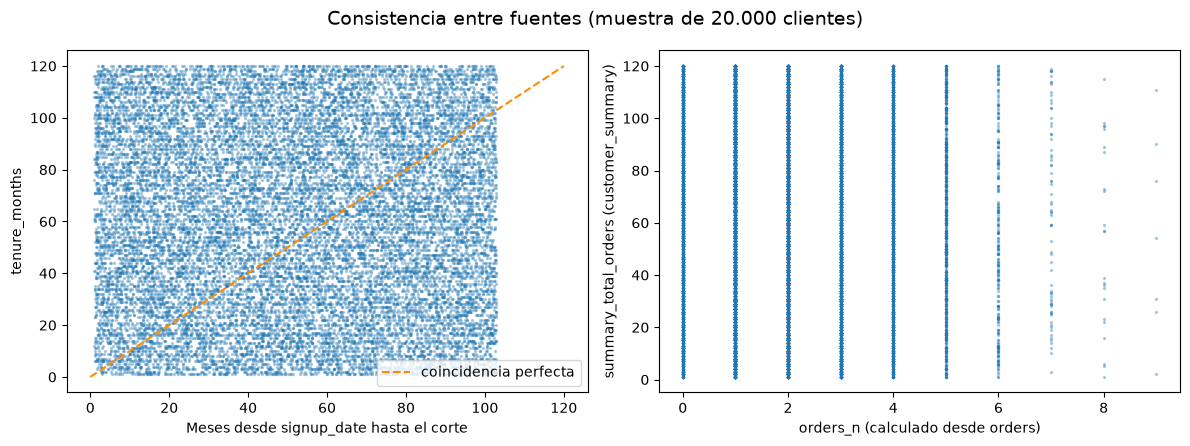

In [19]:
muestra = c360.sample(min(20_000, len(c360)), random_state=SEMILLA)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(meses_desde_signup.loc[muestra.index], muestra["tenure_months"], s=2, alpha=0.3)
axes[0].plot([0, 120], [0, 120], color="darkorange", linestyle="--", label="coincidencia perfecta")
axes[0].set_xlabel("Meses desde signup_date hasta el corte")
axes[0].set_ylabel("tenure_months")
axes[0].legend()
axes[1].scatter(muestra["orders_n"], muestra["summary_total_orders"], s=2, alpha=0.3)
axes[1].set_xlabel("orders_n (calculado desde orders)")
axes[1].set_ylabel("summary_total_orders (customer_summary)")
fig.suptitle("Consistencia entre fuentes (muestra de 20.000 clientes)", fontsize=14)
fig.tight_layout()
plt.show()

In [20]:
# Orden de las fechas: ¿hay actividad registrada antes de la fecha de registro?
con_pedidos = c360["has_orders"].astype(bool)
pd.DataFrame([
    {"comparacion": "Primer pedido antes de signup_date", "clientes": con_pedidos.sum(),
     "contradicen": (c360.loc[con_pedidos, "first_order_date"] < c360.loc[con_pedidos, "signup_date"]).sum()},
    {"comparacion": "Último pedido antes de signup_date", "clientes": con_pedidos.sum(),
     "contradicen": (c360.loc[con_pedidos, "last_order_date"] < c360.loc[con_pedidos, "signup_date"]).sum()},
    {"comparacion": "Último pago antes de signup_date", "clientes": len(c360),
     "contradicen": (c360["last_payment_date"] < c360["signup_date"]).sum()},
]).set_index("comparacion").assign(pct=lambda d: (100 * d["contradicen"] / d["clientes"]).round(2))

,clientes,contradicen,pct
comparacion,,,
Primer pedido antes de signup_date,432581,251869,58.2200
Último pedido antes de signup_date,432581,134371,31.0600
Último pago antes de signup_date,500000,7261,1.4500


In [21]:
# Ciudad y estado: cada ciudad pertenece a un solo estado en la geografía de India
ESTADO_DE_CIUDAD = {"Ahmedabad": "Gujarat", "Bengaluru": "Karnataka", "Chennai": "Tamil Nadu", "Delhi": "Delhi",
                    "Faridabad": "Haryana", "Hyderabad": "Telangana", "Kolkata": "West Bengal", "Mumbai": "Maharashtra"}
print(f"Clientes cuyo estado corresponde a su ciudad: {(c360['state'] == c360['city'].map(ESTADO_DE_CIUDAD)).mean():.2%}")
pd.crosstab(c360["city"], c360["state"])

Clientes cuyo estado corresponde a su ciudad: 12.56%


state,Delhi,Gujarat,Haryana,Karnataka,Maharashtra,Tamil Nadu,Telangana,West Bengal
city,,,,,,,,
Ahmedabad,7800,7899,7912,7781,7916,7689,7815,7907
Bengaluru,7801,7656,7811,7806,7710,7769,7992,7864
Chennai,7600,7838,7790,7752,7974,8078,7879,7873
Delhi,7662,7627,7893,7790,7791,7894,7843,7999
Faridabad,7644,7963,7734,7871,7801,7838,7795,7851
Hyderabad,7811,7747,7856,7781,7713,7938,8000,7718
Kolkata,7868,7795,7692,7752,7686,7832,7773,7794
Mumbai,7658,7689,7783,7862,7821,7887,7792,7844


In [22]:
# Soporte: escalated frente a issue_status
pd.crosstab(plata["support_tickets"]["issue_status"], plata["support_tickets"]["escalated"].astype(object))

escalated,False,True
issue_status,,
Closed,18739,19028
Escalated,18480,18876
Open,18620,18556
Resolved,18983,18718


In [23]:
# Coherencia dentro de customer_summary
print(f"Máxima diferencia average_order_value vs total_spent / pedidos: {(c360['average_order_value'] - c360['total_spent'] / c360['summary_total_orders']).abs().max():.4f}")
print(f"Máxima diferencia return_rate vs total_returns / pedidos: {(c360['return_rate'] - c360['total_returns'] / c360['summary_total_orders']).abs().max():.4f}")

Máxima diferencia average_order_value vs total_spent / pedidos: 0.0000
Máxima diferencia return_rate vs total_returns / pedidos: 0.0005


**Hallazgos**

| Hallazgo | Qué implica |
|---|---|
| 6 de las 10 banderas están en 0: estado vs devuelto, motivo sin devolución, monto, suscripción inactiva con tarifa, devoluciones > pedidos y CLV < gasto | Esas reglas se cumplen en todos los registros |
| `tenure_months` no cuadra con `signup_date` en 89,36 % de los clientes y su correlación es prácticamente 0. `tenure_months` llega a 120 meses, y desde `signup_date` solo hay 102,9 como máximo | Son dos medidas de antigüedad que no coinciden |
| El primer pedido es anterior a `signup_date` en 58,22 % de los clientes con pedidos, y el último en 31,06 %. El último pago lo es en 1,45 % de los clientes | `signup_date` tampoco es coherente con la actividad registrada, así que no se puede tratar como dato primario |
| `summary_total_orders` y `orders_n` coinciden en 0,71 % de los clientes, y las correlaciones entre `customer_summary` y sus equivalentes de `orders` son prácticamente 0. Los 67.419 clientes sin pedidos en `orders` tienen pedidos en `customer_summary` | Las 2 fuentes no describen las mismas compras. Por lo tanto, una no se puede corregir con la otra |
| En `customer_summary`, `average_order_value` es igual a `total_spent / summary_total_orders` y `return_rate` es igual a `total_returns / summary_total_orders` | Estas columnas cuadran dentro de la tabla. Esto no indica si `customer_summary` u `orders` tiene los valores correctos |
| El estado corresponde a la ciudad en 12,56 % de los clientes, y cada ciudad se reparte casi igual entre los 8 estados | `city` y `state` no se pueden interpretar juntas como una ubicación |
| `tickets_last_year_max` coincide con `tickets_n` en 11,19 % de los clientes con tickets | No se puede saber con la documentación disponible si miden lo mismo |
| `escalated` se reparte casi igual entre los estados de `issue_status`, incluidos 18.480 tickets con estado `Escalated` y `escalated` falso | Las 2 columnas no son coherentes. `issue_status` no llega a `customer_360` |

**Decisiones**

Son datos sintéticos y estas contradicciones no permiten saber qué valor es el correcto. Por eso no se rechazan filas ni se corrige una columna con otra. Las decisiones se refieren a las columnas de
`customer_360`, la tabla prevista para el modelado.

| Inconsistencia | Decisión |
|---|---|
| `tenure_months` vs `signup_date` | Se conservan ambas, y la antigüedad se puede calcular desde `signup_date`. Ninguna medida se trata como la verdadera |
| Columnas de `customer_summary` vs columnas `orders_*` | Se conservan los 2 grupos en `customer_360`, sin mezclarlos. Cuál usar se decide más adelante |
| `summary_vs_orders_mismatch` | No se usa como variable, porque marca una inconsistencia entre fuentes y no un comportamiento del cliente. Se quita con el pipeline de limpieza (sección 3.7) |
| `city` vs `state` | Se conservan sin construir variables geográficas combinadas |
| `tickets_last_year_max` vs `tickets_n` | Se conservan sin regla de limpieza |
| `escalated` vs `issue_status` (de `support_tickets`) | Ninguna está en `customer_360`. `tickets_escalated_n`, calculada desde `escalated`, se conserva sin regla de limpieza |

### 3.5 Precisión
¿Los valores son correctos o admisibles?

Los datos son sintéticos, así que no hay una fuente externa para verificar los valores. Se revisan atípicos y relaciones que deberían cumplirse.

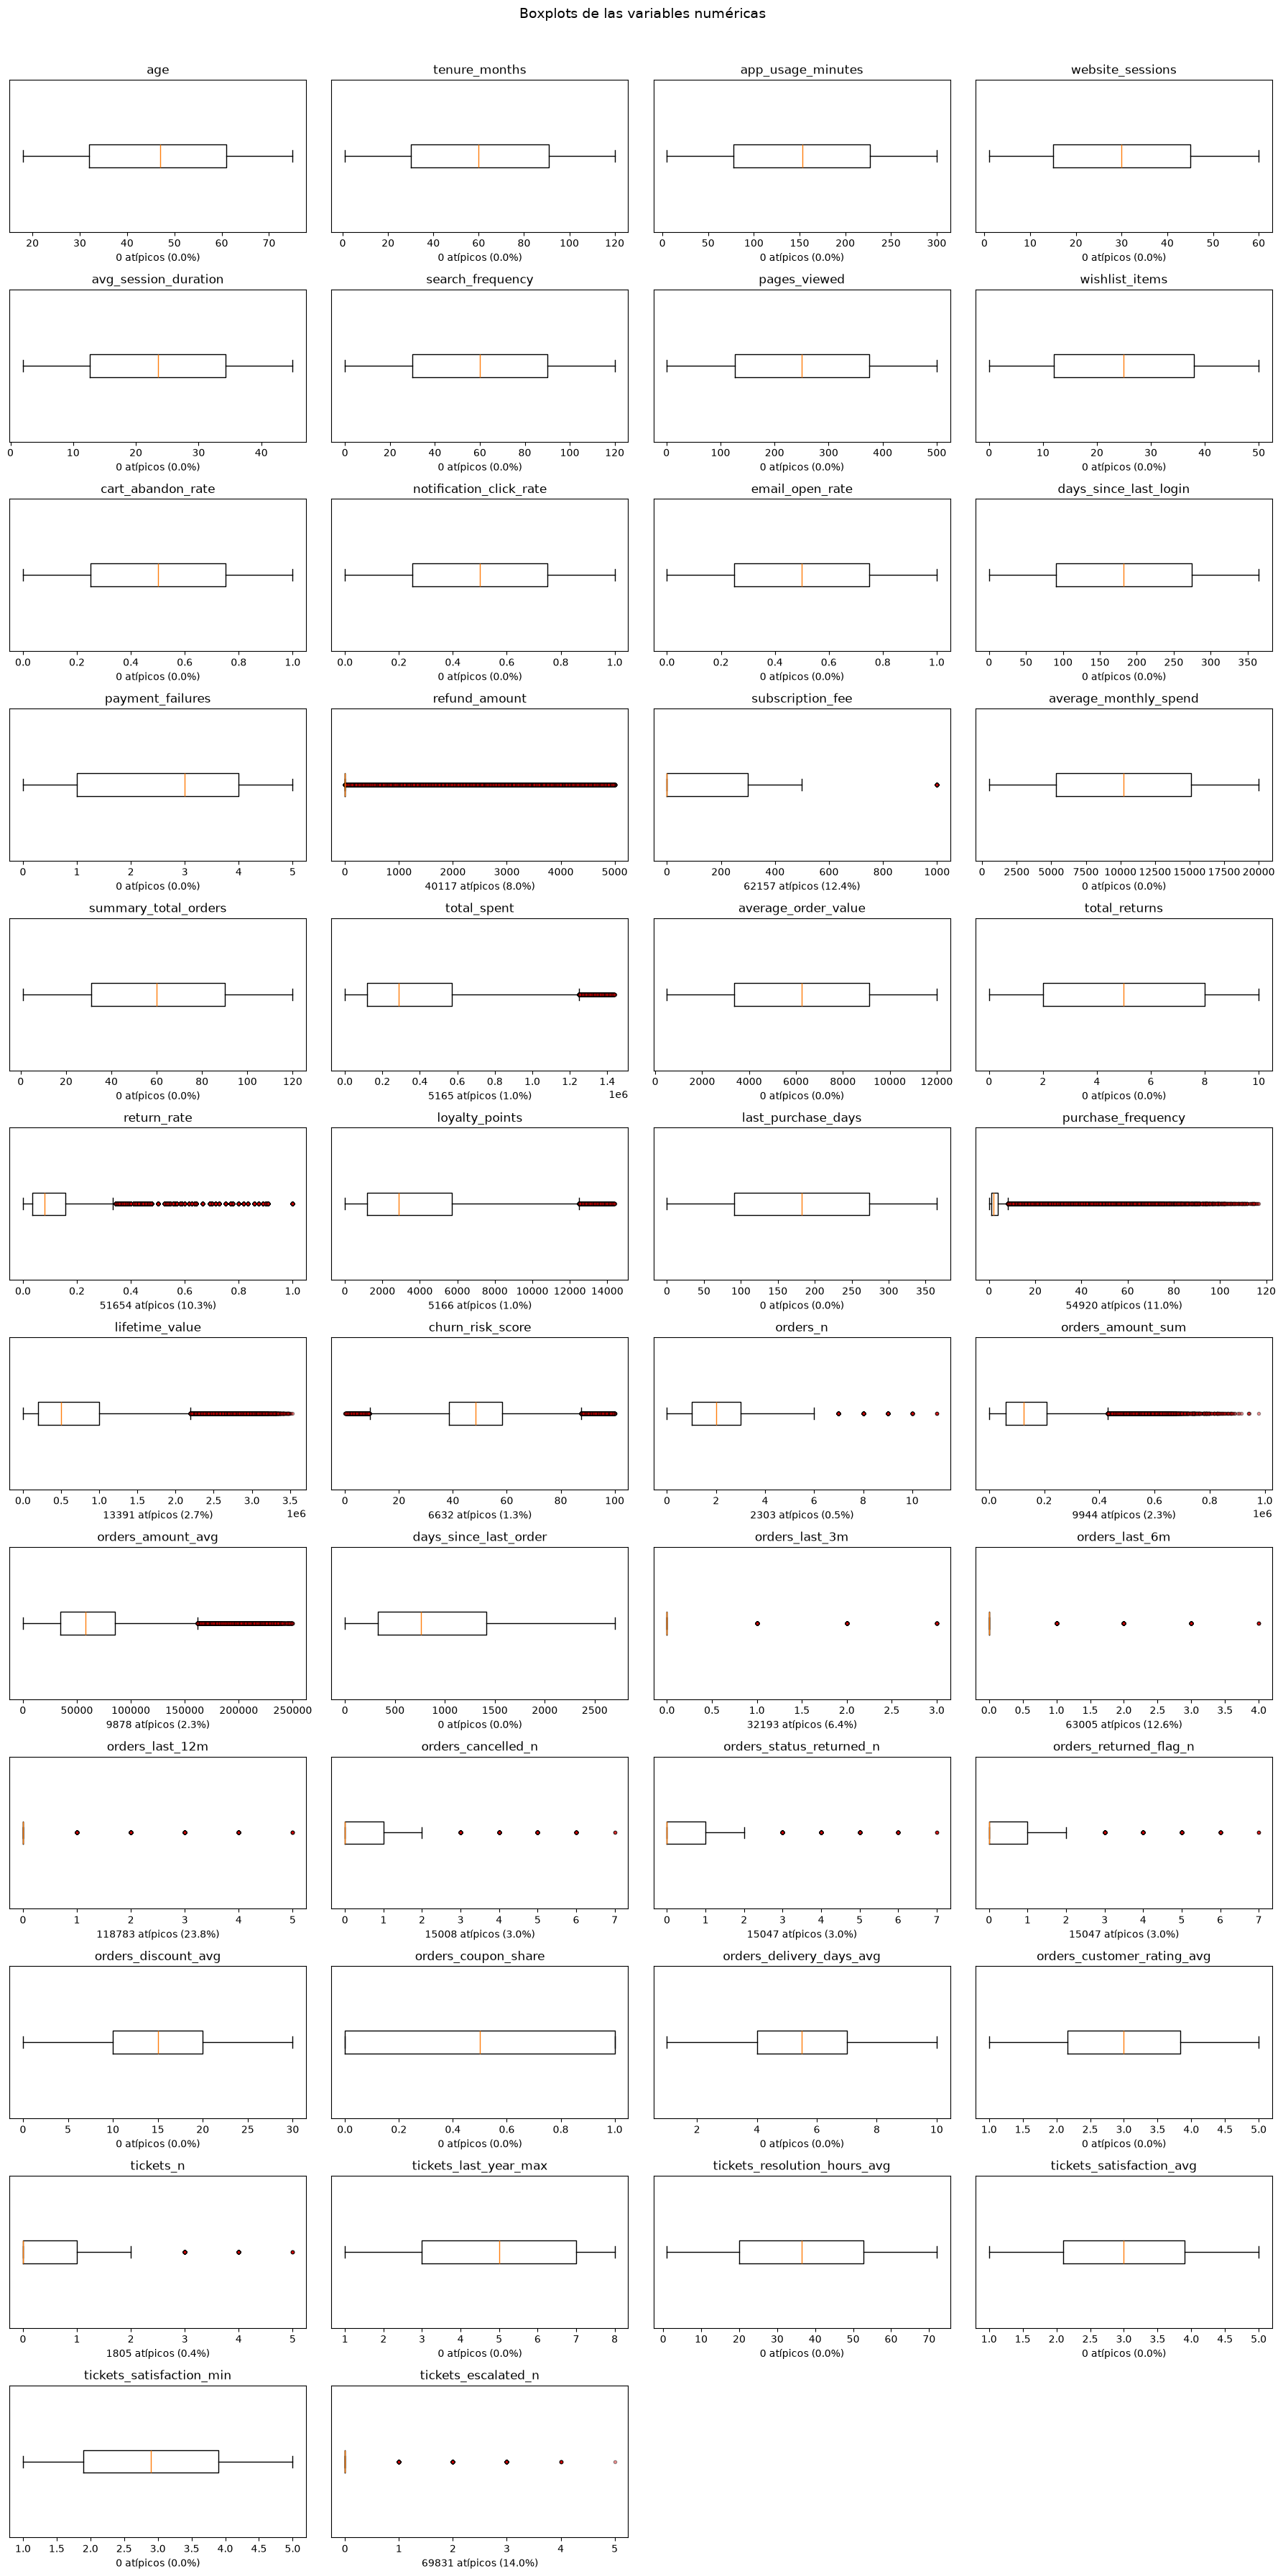

,limite_inferior,limite_superior,n_atipicos,pct_atipicos
variable,,,,
orders_last_12m,0.0000,0.0000,118783,23.7600
tickets_escalated_n,0.0000,0.0000,69831,13.9700
orders_last_6m,0.0000,0.0000,63005,12.6000
subscription_fee,-448.5000,747.5000,62157,12.4300
purchase_frequency,-3.2900,8.1500,54920,10.9800
return_rate,-0.1500,0.3400,51654,10.3300
refund_amount,0.0000,0.0000,40117,8.0200
orders_last_3m,0.0000,0.0000,32193,6.4400
orders_status_returned_n,-1.5000,2.5000,15047,3.0100


In [24]:
numericas_c360 = [c for c in c360.columns if es_numerica(c360[c]) and c != LLAVE]
atipicos = eda.graficar_atipicos(c360, numericas_c360)
atipicos[atipicos["n_atipicos"] > 0].sort_values("pct_atipicos", ascending=False)

**Conclusión**

19 variables tienen atípicos según la regla. En `orders_last_3m`, `orders_last_6m`, `orders_last_12m`,
`tickets_escalated_n` y `refund_amount` los límites son 0 y 0, así que cualquier valor distinto de 0 cuenta como
atípico. El porcentaje de atípicos, por sí solo, no indica si son errores.

In [25]:
# Forma de cada variable con atípicos, para distinguir colas o valores frecuentes de posibles errores
con_atipicos = atipicos.loc[atipicos["n_atipicos"] > 0].sort_values("pct_atipicos", ascending=False).index
contexto = c360[con_atipicos].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).T[["min", "25%", "50%", "75%", "99%", "max"]]
contexto.insert(0, "valores_distintos", c360[con_atipicos].nunique())
contexto.insert(1, "pct_cero", 100 * (c360[con_atipicos] == 0).mean())
contexto.round(2)

,valores_distintos,pct_cero,min,25%,50%,75%,99%,max
orders_last_12m,6,76.2400,0.0000,0.0000,0.0000,0.0000,2.0000,5.0000
tickets_escalated_n,6,86.0300,0.0000,0.0000,0.0000,0.0000,2.0000,5.0000
orders_last_6m,5,87.4000,0.0000,0.0000,0.0000,0.0000,1.0000,4.0000
subscription_fee,5,50.0200,0.0000,0.0000,0.0000,299.0000,999.0000,999.0000
purchase_frequency,7241,0.0000,0.0200,1.0000,1.9900,3.8600,42.7400,116.7500
return_rate,305,10.0900,0.0000,0.0400,0.0800,0.1600,1.0000,1.0000
refund_amount,38559,91.9800,0.0000,0.0000,0.0000,0.0000,"4,371.0800","4,999.9000"
orders_last_3m,4,93.5600,0.0000,0.0000,0.0000,0.0000,1.0000,3.0000
orders_status_returned_n,8,51.3500,0.0000,0.0000,0.0000,1.0000,3.0000,7.0000
orders_returned_flag_n,8,51.3500,0.0000,0.0000,0.0000,1.0000,3.0000,7.0000


**Conclusión**

- **Variables con límites de 0 y 0:** más del 75 % de sus valores son 0, así que la regla no señala errores en ellas.
- **`orders_n`, `orders_cancelled_n`, `orders_status_returned_n`, `orders_returned_flag_n` y `tickets_n`:** son conteos
  enteros con máximos entre 5 y 11, valores plausibles.
- **`total_spent`, `orders_amount_sum` y `orders_amount_avg`:** tienen colas hacia la derecha, sin ceros ni negativos.
  Sus máximos no muestran por sí solos un error de escala.
- **`churn_risk_score`:** sus atípicos están dentro de su rango de 0 a 100, así que son valores admisibles.
- **`purchase_frequency`:** tiene mediana de 1,99 y máximo de 116,75. El diccionario no indica su unidad de tiempo, así
  que no se puede juzgar si esos valores son plausibles.

In [26]:
# Qué hay detrás de las colas
print("Clientes por valor de subscription_fee:")
display(c360["subscription_fee"].value_counts().sort_index().rename("clientes").to_frame())

print("Proporción frente a total_spent:")
display(pd.DataFrame({
    "loyalty_points / total_spent": (c360["loyalty_points"] / c360["total_spent"]).describe(),
    "lifetime_value / total_spent": (c360["lifetime_value"] / c360["total_spent"]).describe(),
}).loc[["min", "50%", "max"]].round(4))

return_rate_alto = c360["return_rate"] > atipicos.loc["return_rate", "limite_superior"]
print("Mediana de pedidos en customer_summary:")
print(f"  Clientes con return_rate atípico: {c360.loc[return_rate_alto, 'summary_total_orders'].median():.0f}")
print(f"  Resto de clientes: {c360.loc[~return_rate_alto, 'summary_total_orders'].median():.0f}")
print()

print("Valor promedio por pedido según cada fuente:")
display(c360[["average_order_value", "orders_amount_avg"]].describe().loc[["min", "50%", "max"]].round(2))

Clientes por valor de subscription_fee:


,clientes
subscription_fee,
0.0000,250103
199.0000,62396
299.0000,62628
499.0000,62716
999.0000,62157


Proporción frente a total_spent:


,loyalty_points / total_spent,lifetime_value / total_spent
min,0.0084,1.1000
50%,0.0100,1.8010
max,0.0100,2.5000


Mediana de pedidos en customer_summary:
  Clientes con return_rate atípico: 11
  Resto de clientes: 67

Valor promedio por pedido según cada fuente:


,average_order_value,orders_amount_avg
min,500.0800,77.4700
50%,"6,239.4500","58,149.9400"
max,"11,999.9900","249,976.6500"


**Conclusión**

- **`subscription_fee`:** sus 62.157 atípicos son exactamente los clientes con tarifa de 999, una de sus 4 tarifas. Es
  un valor frecuente, no un error.
- **`loyalty_points` y `lifetime_value`:** el primero es cerca de 1 % de `total_spent`, y el segundo está entre 1,1 y 2,5
  veces `total_spent`. Sus atípicos están relacionados con los valores altos de `total_spent`.
- **`return_rate`:** los clientes con valores atípicos tienen una mediana de 11 pedidos, mientras que el resto, de 67. Con pocos
  pedidos, pocas devoluciones elevan la tasa.
- **`average_order_value` y `orders_amount_avg`:** la mediana es 6.239,45 en la primera y 58.149,94 en la segunda. Tienen escalas distintas, así que una no puede reemplazar a la otra ni sus valores se pueden comparar directamente.

In [27]:
# Relaciones que deberían cumplirse entre columnas de customer_360 (en cada una se cuentan los incumplimientos)
tiene_reembolso = c360["refund_amount"] > 0
relaciones = {
    "lifetime_value >= total_spent": c360["lifetime_value"] < c360["total_spent"],
    "total_returns <= summary_total_orders": c360["total_returns"] > c360["summary_total_orders"],
    "refund_amount <= total_spent": c360["refund_amount"] > c360["total_spent"],
    "orders_last_3m <= orders_last_6m": c360["orders_last_3m"] > c360["orders_last_6m"],
    "orders_last_6m <= orders_last_12m": c360["orders_last_6m"] > c360["orders_last_12m"],
    "orders_last_12m <= orders_n": c360["orders_last_12m"] > c360["orders_n"],
    "cancelados + devueltos <= orders_n": c360["orders_cancelled_n"] + c360["orders_status_returned_n"] > c360["orders_n"],
    "orders_amount_sum = orders_n x orders_amount_avg": (c360["orders_amount_sum"] - c360["orders_n"] * c360["orders_amount_avg"]).abs() > 0.1,
    "first_order_date <= last_order_date": c360["first_order_date"] > c360["last_order_date"],
    "tickets_escalated_n <= tickets_n": c360["tickets_escalated_n"] > c360["tickets_n"],
    "satisfacción mínima <= promedio (tickets)": c360["tickets_satisfaction_min"] > c360["tickets_satisfaction_avg"] + 1e-9,
}
display(pd.DataFrame({
    "incumplen": {regla: incumple.sum() for regla, incumple in relaciones.items()},
    "pct_incumplen": {regla: round(100 * incumple.mean(), 4) for regla, incumple in relaciones.items()},
}))

print("Porcentaje de clientes con refund_amount > 0 según last_payment_status:")
display((100 * tiene_reembolso.groupby(c360["last_payment_status"]).mean()).round(2).rename("pct_con_reembolso").to_frame())

es_refunded = c360["last_payment_status"] == "Refunded"
print(f"Clientes con estado Refunded y refund_amount en 0: {100 * (~tiene_reembolso[es_refunded]).mean():.2f} %")
print(f"Clientes con refund_amount > 0: {tiene_reembolso.sum():,}")
print(f"  Con estado Refunded: {(tiene_reembolso & es_refunded).sum():,}")
print(f"  Con otro estado: {(tiene_reembolso & ~es_refunded).sum():,}")

,incumplen,pct_incumplen
lifetime_value >= total_spent,0,0.0000
total_returns <= summary_total_orders,0,0.0000
refund_amount <= total_spent,103,0.0206
orders_last_3m <= orders_last_6m,0,0.0000
orders_last_6m <= orders_last_12m,0,0.0000
orders_last_12m <= orders_n,0,0.0000
cancelados + devueltos <= orders_n,0,0.0000
orders_amount_sum = orders_n x orders_amount_avg,0,0.0000
first_order_date <= last_order_date,0,0.0000
tickets_escalated_n <= tickets_n,0,0.0000


Porcentaje de clientes con refund_amount > 0 según last_payment_status:


,pct_con_reembolso
last_payment_status,
Failed,8.1300
Pending,8.0800
Refunded,7.9600
Success,7.9900


Clientes con estado Refunded y refund_amount en 0: 92.04 %
Clientes con refund_amount > 0: 40,117
  Con estado Refunded: 6,614
  Con otro estado: 33,503


**Conclusión**

- **Relaciones:** 10 de las 11 se cumplen en todos los clientes. `refund_amount` supera a `total_spent` en 103 clientes
  (0,0206 %). Son pocos casos, y no se puede saber cuál de las 2 columnas está mal.
- **Reembolsos:** `refund_amount` y `last_payment_status` se contradicen. De los 40.117 clientes con `refund_amount`
  mayor que 0, 33.503 no tienen estado `Refunded`. Y 92,04 % de los clientes con estado `Refunded` tiene `refund_amount`
  en 0. Con estos datos no se puede saber cuál de las 2 columnas es correcta.

**Resumen de la revisión**

| Revisión | Resultado | Qué implica |
|---|---|---|
| Valores fuera de rango (sección 3.3) | Sin incumplimientos en las 34 variables revisadas | No hay valores fuera de los rangos definidos |
| Atípicos (regla de 1,5 × IQR) | 19 variables con atípicos, explicados por valores frecuentes, conteos o colas. `purchase_frequency` no tiene unidad documentada | Ningún atípico se puede identificar como error, aunque `purchase_frequency` no se puede juzgar |
| Valor promedio por pedido | `average_order_value` y `orders_amount_avg` tienen escalas distintas | Una no puede reemplazar a la otra ni sus valores se pueden comparar directamente |
| Relaciones que deberían cumplirse | 10 de 11 se cumplen. `refund_amount` supera a `total_spent` en 103 clientes | Son pocos casos, y no se puede saber cuál de las 2 columnas está mal |
| `refund_amount` vs `last_payment_status` | 33.503 de los 40.117 clientes con `refund_amount` mayor que 0 no tienen estado `Refunded`, y 92,04 % de los `Refunded` tiene `refund_amount` en 0 | Se contradicen, y no se puede saber cuál es correcta |

**Decisiones**

Con la evidencia disponible, ningún atípico se puede identificar como error. Por eso el pipeline de limpieza no elimina ni recorta valores.

| Caso | Decisión |
|---|---|
| Atípicos según la regla de 1,5 × IQR | Se conservan. Si un modelo es sensible a las colas, la transformación se decide en el modelado y se ajusta solo con train |
| `purchase_frequency` | Se conserva, sin atribuirle una unidad de tiempo |
| `average_order_value` vs `orders_amount_avg` | Se conservan sin mezclarlas ni convertir una a la escala de la otra |
| `refund_amount` vs `total_spent` | Se conservan los 103 clientes, sin regla de limpieza |
| `refund_amount` vs `last_payment_status` | Se conservan ambas, sin regla de limpieza |

### 3.6 Temporalidad
**Fecha de corte:** 2026-07-31, la misma de las reglas de plata. Es la fecha de la última modificación del dataset en
Kaggle, correspondiente a su versión 2 (consultada el 2026-11-02). Un dataset publicado ese día no debería tener fechas
posteriores. Es un criterio del proyecto, porque los datos son sintéticos y su README no indica una fecha de extracción.

In [28]:
rangos = pd.DataFrame({
    col: {"minimo": c360[col].min(), "maximo": c360[col].max(),
          "pct_posterior_al_corte": 100 * (c360[col] > FECHA_CORTE).mean()}
    for col in features.COLUMNAS_FECHA
}).T
print(f"Fecha de corte de las reglas: {FECHA_CORTE.date()}")
rangos

Fecha de corte de las reglas: 2026-07-31


,minimo,maximo,pct_posterior_al_corte
signup_date,2018-01-01 00:00:00,2026-06-30 00:00:00,0.0000
last_payment_date,2026-01-01 00:00:00,2026-12-28 00:00:00,41.6600
first_order_date,2019-01-01 00:00:00,2026-05-24 00:00:00,0.0000
last_order_date,2019-01-01 00:00:00,2026-05-24 00:00:00,0.0000


**Conclusión**

`signup_date`, `first_order_date` y `last_order_date` terminan antes de la fecha de corte (2026-07-31). En cambio,
`last_payment_date` llega hasta 2026-12-28, y 41,66 % de sus valores es posterior al corte. Ninguna de estas 4 fechas
indica cuándo abandonó un cliente.

In [29]:
# Clientes por año en cada fecha, para ver hasta cuándo llega cada una
columnas_anio = ["signup_date", "first_order_date", "last_order_date", "last_payment_date"]
por_anio = pd.DataFrame({col: c360[col].dt.year.value_counts() for col in columnas_anio}).sort_index().fillna(0).astype(int)
por_anio.index = por_anio.index.astype(int).rename("año")
por_anio

,signup_date,first_order_date,last_order_date,last_payment_date
año,,,,
2018,58924,0,0,0
2019,58653,118586,21061,0
2020,59143,90254,27551,0
2021,58563,68798,36233,0
2022,59154,52626,47288,0
2023,58733,40764,62137,0
2024,58676,30608,81168,0
2025,58932,23323,106571,0
2026,29222,7622,50572,500000


**Conclusión**

- **Registros:** hay cerca de 59.000 por año entre 2018 y 2025, y 29.222 en 2026, hasta el 30 de junio.
- **Pedidos:** `last_order_date` tiene más clientes a medida que avanzan los años.
- **Pagos:** los 500.000 clientes tienen su último pago en 2026, incluidos los 382.009 cuyo último pedido fue antes de
  2026. Un pago no tiene que corresponder a un pedido, pero esta columna no sigue el mismo patrón por año que las demás.

In [30]:
# last_payment_date: reparto por mes y coincidencia con la bandera de plata
posterior_al_corte = c360["last_payment_date"] > FECHA_CORTE
print(f"Clientes con last_payment_date posterior al {FECHA_CORTE.date()}: {posterior_al_corte.sum():,} ({100 * posterior_al_corte.mean():.2f} %)")
print(f"  De ellos, marcados en payment_date_in_future: {c360.loc[posterior_al_corte, 'payment_date_in_future'].astype(bool).sum():,}")
print(f"  Mayor distancia después de esa fecha: {(c360['last_payment_date'] - FECHA_CORTE).dt.days.max()} días")
print()
print("Porcentaje de clientes por mes de last_payment_date:")
display((100 * c360["last_payment_date"].dt.to_period("M").value_counts(normalize=True).sort_index()).round(2).rename("pct_clientes").to_frame())

Clientes con last_payment_date posterior al 2026-07-31: 208,300 (41.66 %)
  De ellos, marcados en payment_date_in_future: 208,300
  Mayor distancia después de esa fecha: 150 días

Porcentaje de clientes por mes de last_payment_date:


,pct_clientes
last_payment_date,
2026-01,8.3700
2026-02,8.3400
2026-03,8.3200
2026-04,8.2900
2026-05,8.3300
2026-06,8.3100
2026-07,8.3800
2026-08,8.3600
2026-09,8.3500


**Conclusión**

Cada mes de 2026 tiene cerca de 8,3 % de los clientes, tanto antes como después del corte. Los 208.300 clientes con
fecha posterior al corte son los mismos que marca `payment_date_in_future`, con una distancia máxima de 150 días. La
fecha no se puede corregir, porque no se conoce el valor real. Cambiar la fecha de corte tampoco lo resolvería. Para
incluir estos pagos tendría que llegar a diciembre, siete meses después del último pedido.

In [31]:
# Fecha contra la que se mide la recencia
con_pedidos = c360["has_orders"].astype(bool)
pedido_mas_reciente = c360["last_order_date"].max()
dias_recalculados = (pedido_mas_reciente - c360.loc[con_pedidos, "last_order_date"]).dt.days
print(f"Fecha del pedido más reciente: {pedido_mas_reciente.date()}")
print(f"Clientes con pedidos cuyo days_since_last_order se mide contra esa fecha: {100 * (dias_recalculados == c360.loc[con_pedidos, 'days_since_last_order']).mean():.2f} %")
print()
print("Rango de las variables de días desde la última actividad:")
display(c360[["days_since_last_order", "last_purchase_days", "days_since_last_login"]].agg(["min", "median", "max"]))

Fecha del pedido más reciente: 2026-05-24
Clientes con pedidos cuyo days_since_last_order se mide contra esa fecha: 100.00 %

Rango de las variables de días desde la última actividad:


,days_since_last_order,last_purchase_days,days_since_last_login
min,0.0000,0.0000,0.0000
median,764.0000,182.0000,182.0000
max,"2,700.0000",365.0000,365.0000


**Conclusión**

- `days_since_last_order` se mide contra 2026-05-24, la fecha del pedido más reciente, y no
  contra la fecha de corte. La antigüedad desde `signup_date`, en cambio, se calculó hasta la fecha de corte.
- **Variables de días:** `days_since_last_order` llega a 2.700 días, con mediana de 764. `last_purchase_days` y
  `days_since_last_login` llegan a 365, con mediana de 182.

**Resumen de la revisión**

| Revisión | Resultado | Qué implica |
|---|---|---|
| Hasta dónde llegan las fechas | Registros hasta 2026-06-30, pedidos hasta 2026-05-24 y pagos hasta 2026-12-28 | Las tablas no comparten una misma fecha final |
| `last_payment_date` | 41,66 % posterior al corte, y cerca de 8,3 % de clientes en cada mes de 2026 | No se puede tomar como una fecha observada ni corregir |
| Fecha de referencia | `days_since_last_order` se mide contra 2026-05-24, y la antigüedad calculada contra 2026-07-31 | Estas variables no están medidas contra la misma fecha |
| Fecha de abandono | Ninguna de las fechas indica cuándo abandonó un cliente | No se puede construir una partición temporal ni verificar que las variables se midieron antes del abandono |

**Decisiones**

| Caso | Decisión |
|---|---|
| `last_payment_date` | No se corrige ni se usa como variable, y tampoco se calculan días desde el último pago. Se quita con el pipeline de limpieza (sección 3.7) |
| `payment_date_in_future` | No se usa como variable, porque marca un problema de calidad de la fecha y no un comportamiento del cliente. Se quita con el pipeline de limpieza (sección 3.7) |
| Fecha de corte | Se mantiene 2026-07-31, la última modificación del dataset en Kaggle y la misma de las reglas de plata |
| `days_since_last_order` | Se conserva sin recalcular. Se documenta que se mide contra 2026-05-24 |
| Partición | Es aleatoria y estratificada. No puede ser temporal porque no se sabe cuándo ocurrió el abandono. Esto no evita que alguna variable se haya medido después del abandono, ni permite evaluar el modelo con clientes futuros; el riesgo de fuga se audita en la sección 5.3 |

### 3.7 Pipeline de limpieza

Las reglas de limpieza se reúnen en `crear_pipeline_limpieza()` (`src/churn/features.py`), para aplicarlas exactamente
igual a train, a test y a los clientes nuevos de la API. Ninguna elimina clientes ni corrige valores.

| Regla | Problema | Dimensión | Acción | ¿Aprende de los datos? |
|---|---|---|---|---|
| **1** | `tenure_months` no cuadra con `signup_date` | Consistencia | Se agrega `antiguedad_meses`, calculada desde `signup_date`, y se conservan ambas columnas | No |
| **2** | `last_payment_date` posterior al corte | Temporalidad | Se descartan `last_payment_date` y `payment_date_in_future` | No |
| **3** | `summary_total_orders` no coincide con `orders_n` | Consistencia | Se descarta `summary_vs_orders_mismatch` | No |

Estos casos no tienen regla en el pipeline:

| Caso | Dimensión | Tratamiento |
|---|---|---|
| Columnas de `customer_summary` vs columnas `orders_*` | Consistencia | Se conservan los 2 grupos, sin mezclarlos. Cuál usar se decide más adelante |
| Nulos estructurales (sin pedidos / sin tickets) | Completitud | Se conservan. Si un modelo no admite nulos, su pipeline definirá cómo representarlos, ajustado solo con train |

Las variables candidatas a fuga (`churn_risk_score`, `customer_segment`) no se quitan aquí. Se auditan con train más adelante.

In [32]:
limpio = features.crear_pipeline_limpieza().fit_transform(c360)
print(f"Antes: {c360.shape} -> Después: {limpio.shape}")
print("Columnas nuevas:", sorted(set(limpio.columns) - set(c360.columns)))
print("Columnas descartadas:", sorted(set(c360.columns) - set(limpio.columns)))

Antes: (500000, 70) -> Después: (500000, 68)
Columnas nuevas: ['antiguedad_meses']
Columnas descartadas: ['last_payment_date', 'payment_date_in_future', 'summary_vs_orders_mismatch']


**Conclusión**

El pipeline conserva los 500.000 clientes. Agrega `antiguedad_meses` y quita `last_payment_date`,
`payment_date_in_future` y `summary_vs_orders_mismatch`, así que `customer_360` pasa de 70 a 68 columnas para el análisis.

**Hallazgos de calidad**

| Dimensión | Hallazgo | Decisión |
|---|---|---|
| Completitud | Los nulos de `customer_360` son estructurales, clientes sin pedidos o sin tickets | Se conservan, sin eliminar clientes ni rellenar valores |
| Duplicidad | No hay llaves duplicadas ni clientes idénticos en `customer_360` | Sin regla de limpieza |
| Conformidad | Las 34 variables revisadas no tienen incumplimientos y las 20 categóricas no tienen variantes | Sin regla de limpieza |
| Consistencia | `tenure_months` no cuadra con `signup_date` en 89,36 % de los clientes | Regla 1: se agrega `antiguedad_meses` y se conservan ambas columnas. Ninguna medida se trata como la verdadera |
| Consistencia | `summary_total_orders` coincide con `orders_n` solo en 0,71 % de los clientes | Regla 3: se quita `summary_vs_orders_mismatch`. Se conservan las columnas de ambas fuentes, sin mezclarlas ni corregir una con la otra |
| Precisión | Ningún atípico se puede identificar como error. `refund_amount` y `last_payment_status` se contradicen | Sin regla de limpieza. No se eliminan ni se recortan valores |
| Temporalidad | 41,66 % de `last_payment_date` es posterior a la fecha de corte | Regla 2: se quitan `last_payment_date` y `payment_date_in_future` |
| Temporalidad | Ninguna fecha indica cuándo abandonó un cliente | Sin regla de limpieza. Por eso la partición es aleatoria y estratificada, no temporal |

## 4. Partición del conjunto de datos

| Conjunto | Proporción | Uso |
|---|---|---|
| `train` | 70 % | EDA de la sección 5, comparación de modelos y ajuste de hiperparámetros (con validación cruzada) |
| `test` | 30 % | Evaluar **una sola vez** el modelo definitivo, con clientes que no se usaron para analizar la relación con `churn` ni para ajustar modelos |

La sección 3 sí revisó a todos los clientes, pero sin relacionar las variables con `churn`.

**¿Por qué la partición es aleatoria?** Aquí cada cliente es una
fila y no se sabe cuándo ocurrió el abandono, así que no se puede construir una partición temporal. La
partición es **aleatoria y estratificada por `churn`**, para que ambos conjuntos tengan la misma tasa. Su límite es que
`test` mide el rendimiento con clientes parecidos a los de `train`, no con clientes futuros.

La partición se guarda en `data/particion.parquet` y la usa también el modelado. Así, el EDA y los modelos ven exactamente
los mismos clientes en cada conjunto. Antes de partir se ordena por `customer_id`, porque Athena no garantiza el orden
de las filas. De este modo, todo el equipo obtiene la misma partición con la misma semilla.

In [33]:
particion = data.cargar_particion(limpio, OBJETIVO, LLAVE)
limpio = limpio.merge(particion, on=LLAVE, how="inner")
train = limpio[limpio["conjunto"] == "train"].drop(columns="conjunto").reset_index(drop=True)
test = limpio[limpio["conjunto"] == "test"].drop(columns="conjunto").reset_index(drop=True)

Verificación de la partición:

In [34]:
print(f"train: {len(train):,} ({len(train) / len(limpio):.1%}) - test: {len(test):,} ({len(test) / len(limpio):.1%})")
print(f"Clientes en ambos conjuntos: {len(set(train[LLAVE]) & set(test[LLAVE]))}")
print(f"Tasa de churn: train {train[OBJETIVO].mean():.2%} · test {test[OBJETIVO].mean():.2%}")
pd.DataFrame({
    "train": train["membership_tier"].value_counts(normalize=True),
    "test": test["membership_tier"].value_counts(normalize=True),
}).mul(100).round(2)

train: 350,000 (70.0%) - test: 150,000 (30.0%)
Clientes en ambos conjuntos: 0
Tasa de churn: train 20.70% · test 20.70%


,train,test
membership_tier,,
Basic,55.0800,54.8700
Silver,24.9200,25.0900
Gold,15.0100,15.0200
Platinum,4.9900,5.0200


**Conclusión**

- **Tamaños:** `train` tiene 350.000 clientes (70 %) y `test` 150.000 (30 %).
- **Clientes repetidos:** ningún cliente está en ambos conjuntos. Esto no descarta una fuga en las variables, que se
  audita más adelante.
- **Representatividad:** la tasa de churn es 20,70 % en ambos. `membership_tier`, que no se usó para estratificar,
  difiere como máximo 0,21 puntos porcentuales entre conjuntos.

## 5. Análisis exploratorio (solo train)

Este análisis guía el modelado. De aquí salen decisiones como qué variables usar. Por eso usa solo `train`, para **evitar
fuga de datos**. `test` simula el futuro (son clientes que no se conocerían al construir el modelo). Si influyeran en
estas decisiones, el modelo se ajustaría indirectamente a ellos y su evaluación final resultaría demasiado optimista.

Como la partición es aleatoria, es una simulación. Los clientes de `test` no son realmente posteriores a los de `train`.
Además, esta separación solo evita la fuga desde `test`. No descarta que alguna variable contenga información de la
etiqueta, lo cual se auditará más adelante.

In [35]:
excluir = {LLAVE, OBJETIVO, *features.COLUMNAS_FECHA, *features.COLUMNAS_FUGA}
NUMERICAS = [c for c in train.columns if es_numerica(train[c]) and c not in excluir]
BOOLEANAS = [c for c in train.columns if pd.api.types.is_bool_dtype(train[c]) and c not in excluir]
CATEGORICAS = [c for c in train.select_dtypes(include="object").columns if c not in excluir]

grupo_de.update({"antiguedad_meses": "Perfil"})
print(f"{len(NUMERICAS)} numéricas · {len(CATEGORICAS)} categóricas · {len(BOOLEANAS)} booleanas")

46 numéricas · 12 categóricas · 3 booleanas


El análisis parte de 61 variables de las 68 columnas que deja el pipeline de limpieza: 46 numéricas, 12 categóricas y 3
booleanas. `antiguedad_meses` queda entre las numéricas, dentro del grupo Perfil.

Estas 7 columnas siguen en `train`, pero no entran en las listas de variables que se analizan de forma general:

| Columnas | Motivo |
|---|---|
| `customer_id` | Es la llave, no una característica del cliente |
| `churn` | Es la variable objetivo. Las demás se comparan contra ella más adelante |
| `signup_date`, `first_order_date` y `last_order_date` | Son fechas y no se analizan directamente. `signup_date` y `last_order_date` se reflejan en `antiguedad_meses` y `days_since_last_order`. `first_order_date` no tiene una variable calculada |
| `churn_risk_score` y `customer_segment` | Son candidatas a fuga de información. Se revisan aparte más adelante |

### 5.1 Análisis univariado

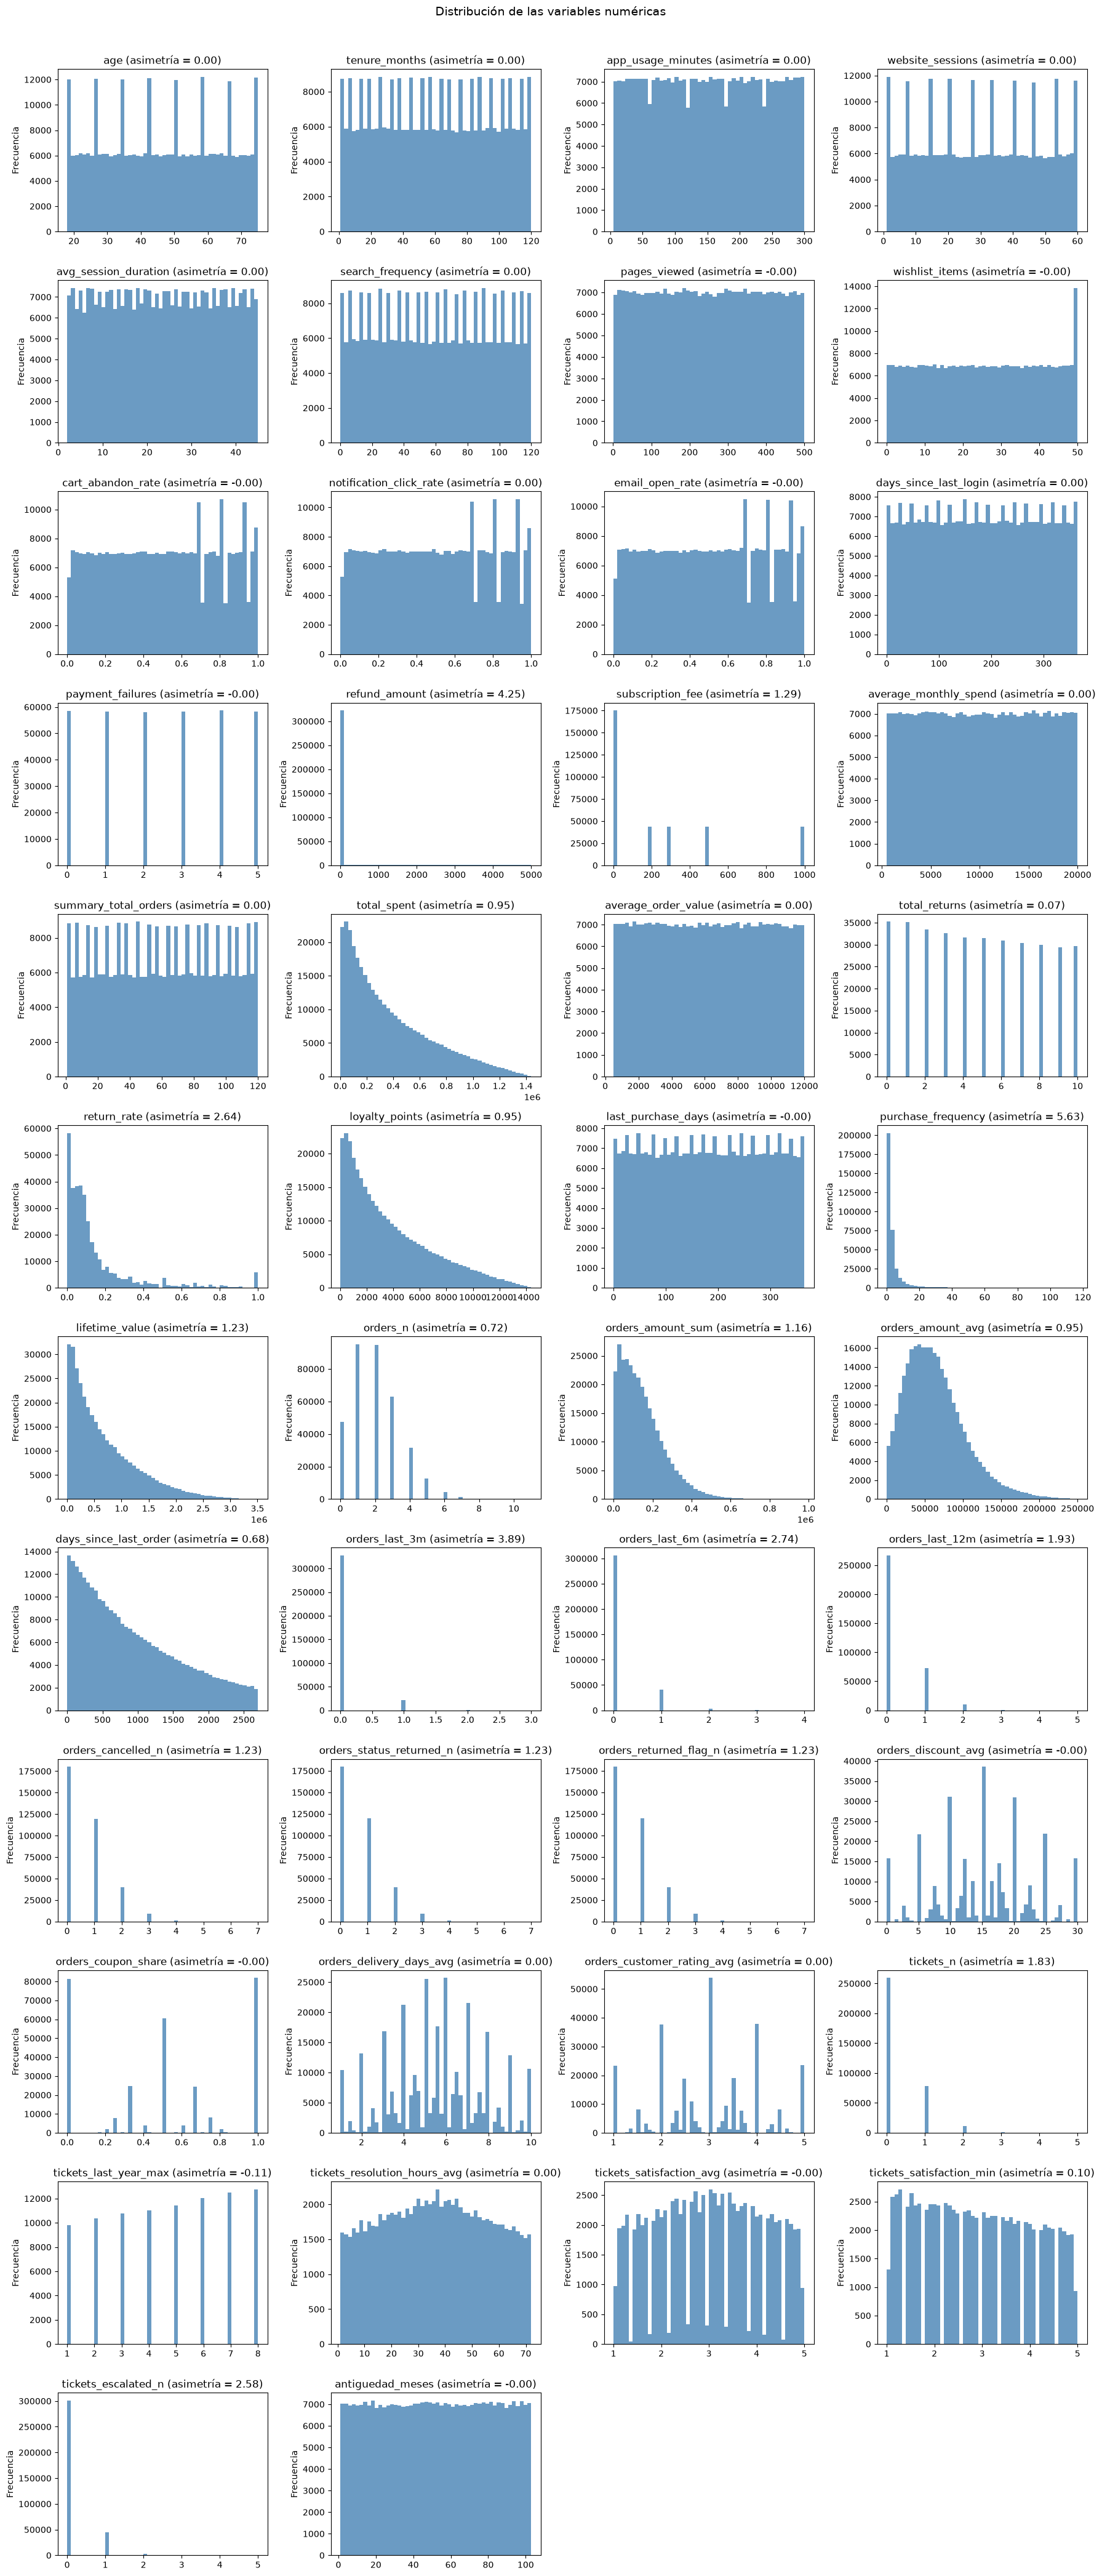

In [36]:
eda.graficar_distribucion(train, NUMERICAS, nombre_figura="distribucion_numericas")

In [37]:
# Variables con mayor asimetría
asimetria = train[NUMERICAS].skew().round(2)
print(f"Variables por nivel de asimetría (de {len(asimetria)}):")
print(f"  Alta (mayor a 1 en valor absoluto): {(asimetria.abs() > 1).sum()}")
print(f"  Moderada (entre 0,5 y 1): {((asimetria.abs() > 0.5) & (asimetria.abs() <= 1)).sum()}")
print(f"  Baja (hasta 0,5): {(asimetria.abs() <= 0.5).sum()}")
asimetria[asimetria.abs() > 1].sort_values(ascending=False).rename("asimetria").to_frame()

Variables por nivel de asimetría (de 46):
  Alta (mayor a 1 en valor absoluto): 14
  Moderada (entre 0,5 y 1): 5
  Baja (hasta 0,5): 27


,asimetria
purchase_frequency,5.6300
refund_amount,4.2500
orders_last_3m,3.8900
orders_last_6m,2.7400
return_rate,2.6400
tickets_escalated_n,2.5800
orders_last_12m,1.9300
tickets_n,1.8300
subscription_fee,1.2900
lifetime_value,1.2300


**Conclusión**

- **Asimetría:** 14 variables tienen asimetría alta, todas hacia la derecha. Las mayores son `purchase_frequency` (5,63),
  `refund_amount` (4,25) y `orders_last_3m` (3,89). Muchas son conteos o montos con gran proporción de ceros.
- **Picos regulares en los histogramas:** en variables como `age` o `tenure_months` no indican valores más frecuentes. El
  gráfico usa 50 barras y estas variables tienen un número limitado de valores, así que unas barras agrupan más valores que
  otras y se ven más altas. Por ejemplo, cada edad tiene cerca de 6.000 clientes, pero las barras que agrupan 2 edades
  llegan a cerca de 12.000.

¿Las variables son casi uniformes? `cv_frecuencias` cercano a 0 = casi uniforme. La forma de una variable no indica por sí sola si se relaciona con `churn`.

In [38]:
eda.evaluar_uniformidad(train, NUMERICAS)

,valores_unicos,cv_frecuencias,v_cramer_vs_uniforme
variable,,,
payment_failures,6,0.0030,0.0020
tenure_months,120,0.0060,0.0010
average_monthly_spend,320446,0.0070,0.0020
summary_total_orders,120,0.0070,0.0020
average_order_value,301940,0.0070,0.0020
pages_viewed,500,0.0070,0.0020
website_sessions,60,0.0080,0.0020
antiguedad_meses,3103,0.0080,0.0020
avg_session_duration,431,0.0230,0.0050


**Conclusión**

21 de las 46 variables tienen `cv_frecuencias` menor a 0,2, un umbral práctico para considerarlas casi uniformes. Incluyen
perfil (`age`, `tenure_months`), interacción digital (`pages_viewed`, `website_sessions`), pagos (`average_monthly_spend`,
`payment_failures`) y resumen de cliente (`summary_total_orders`, `average_order_value`). En el otro extremo están
`refund_amount` y `purchase_frequency`, muy concentradas en valores bajos.

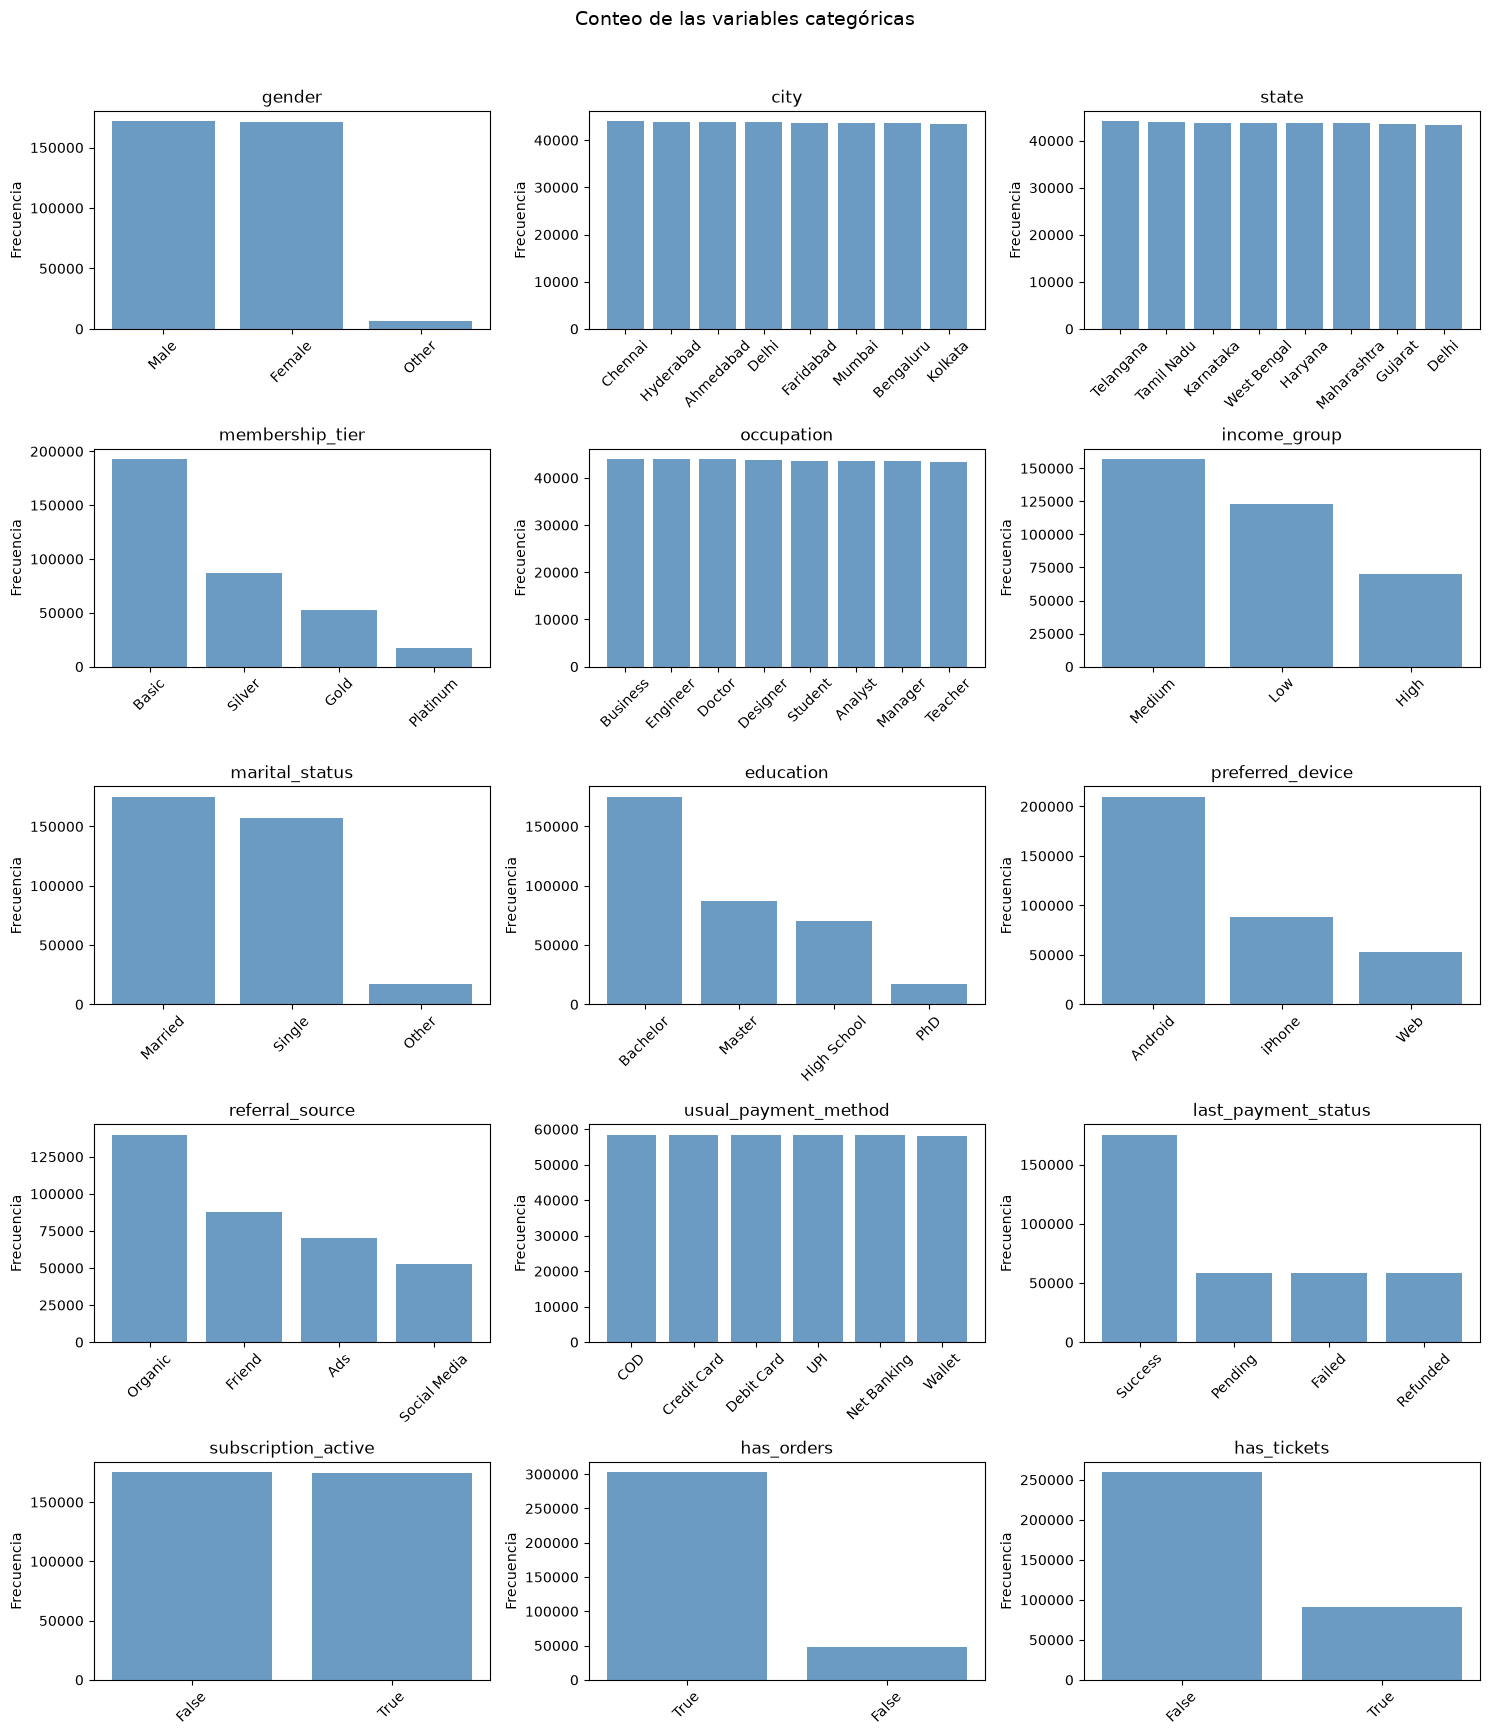

In [39]:
conteo_cat = eda.conteo_categoricas(train, CATEGORICAS + BOOLEANAS, nombre_figura="conteo_categoricas")

In [40]:
# Tamaño de la categoría menos frecuente de cada variable
resumen_cat = conteo_cat.groupby("variable")["porcentaje"].agg(categorias="size", pct_minimo="min", pct_maximo="max")
resumen_cat.sort_values("pct_minimo")

,categorias,pct_minimo,pct_maximo
variable,,,
gender,3,1.9700,49.0400
membership_tier,4,4.9900,55.0800
marital_status,3,5.0000,49.9900
education,4,5.0100,49.9800
state,8,12.3800,12.6000
occupation,8,12.4200,12.5700
city,8,12.4300,12.5700
has_orders,2,13.5200,86.4800
referral_source,4,15.0000,39.9900


**Conclusión**

- **Categorías poco frecuentes:** ninguna está por debajo de 1 %. Las menores son `Other` en `gender` (1,97 %), `Platinum`
  en `membership_tier` (4,99 %), `Other` en `marital_status` (5,00 %) y `PhD` en `education` (5,01 %).
- **Variables casi uniformes:** `city`, `state`, `occupation` y `usual_payment_method` reparten sus categorías casi por igual.
- **Booleanas:** `subscription_active` está casi en 50 %. Además, 13,52 % de los clientes no tiene pedidos y 25,92 % tiene
  tickets.

**Resumen de la revisión**

| Revisión | Resultado | Qué implica |
|---|---|---|
| Asimetría | 14 de 46 variables numéricas tienen asimetría alta, todas hacia la derecha | Algunos modelos podrían necesitar una transformación |
| Uniformidad | 21 de 46 variables numéricas son casi uniformes | Su forma no indica por sí sola si se relacionan con `churn` |
| Categorías | Ninguna categoría está por debajo de 1 % | Ninguna necesita agruparse por falta de clientes |

**Decisiones**

| Caso | Decisión |
|---|---|
| Variables asimétricas | No se transforman en el pipeline de limpieza. Se decide en el modelado según el modelo. Como muchas tienen ceros, un logaritmo simple no serviría |
| Variables casi uniformes | Se conservan. Su relación con `churn` se mide más adelante |
| Categorías poco frecuentes | No se agrupan |

### 5.2 Relación con churn por grupo de variables

3 herramientas, todas sobre train:

- **AUC univariado**: probabilidad de que una sola variable distinga correctamente, entre un cliente que abandonó y uno
  que no, cuál es cuál. 0,5 equivale al azar (la variable no ayuda) y 1 a distinguirlos siempre.
- **Tamaño del efecto**: indica qué tan grande es la diferencia. No se usa el p-valor porque, con 350 mil clientes, una
  diferencia muy pequeña puede salir "estadísticamente significativa".
  - **d de Cohen (numéricas):** cuántas desviaciones estándar separan los 2 promedios. Se considera 0,2 pequeño, 0,5
    mediano y 0,8 grande.
  - **V de Cramér (categóricas):** qué tan asociada está la categoría con `churn`. Se considera 0,1 pequeño, 0,3 mediano y
    0,5 grande.
- **Tasa de churn por categoría o por rango**, con la tasa global como referencia.

In [41]:
relacion = eda.resumen_relacion_objetivo(train, OBJETIVO, NUMERICAS + CATEGORICAS + BOOLEANAS)
relacion.insert(0, "grupo", relacion.index.map(grupo_de))
with pd.option_context("display.max_rows", None):
    display(relacion)

print("AUC univariado por grupo:")
relacion.groupby("grupo")["auc_univariado"].agg(variables="size", minimo="min", maximo="max").sort_values("maximo", ascending=False)

,grupo,tipo,pct_nulos,auc_univariado,metrica_efecto,efecto
variable,,,,,,
last_purchase_days,Resumen de cliente,numérica,0.0000,0.8647,d_cohen,1.5555
return_rate,Resumen de cliente,numérica,0.0000,0.7722,d_cohen,1.0299
purchase_frequency,Resumen de cliente,numérica,0.0000,0.7536,d_cohen,-0.5770
summary_total_orders,Resumen de cliente,numérica,0.0000,0.7447,d_cohen,-0.9093
loyalty_points,Resumen de cliente,numérica,0.0000,0.6962,d_cohen,-0.6318
total_spent,Resumen de cliente,numérica,0.0000,0.6962,d_cohen,-0.6318
lifetime_value,Resumen de cliente,numérica,0.0000,0.6930,d_cohen,-0.5994
total_returns,Resumen de cliente,numérica,0.0000,0.5895,d_cohen,0.3163
tickets_resolution_hours_avg,Soporte,numérica,74.0829,0.5052,d_cohen,-0.0186


AUC univariado por grupo:


,variables,minimo,maximo
grupo,,,
Resumen de cliente,9,0.5012,0.8647
Soporte,6,0.5002,0.5052
Perfil,13,0.5002,0.5030
Pedidos (recalculados),14,0.5000,0.5028
Pagos,7,0.5003,0.5023
Interacción digital,10,0.5000,0.5022
Indicadores,2,0.5003,0.5005


**Conclusión**

8 de las 61 variables tienen AUC univariado de 0,55 o más, todas del grupo Resumen de cliente. La mayor es
`last_purchase_days` (0,8647). Las otras 53 están por debajo de 0,51.

Para el siguiente análisis, se definirán unos rangos de la siguiente manera:

Cada variable numérica se divide en deciles. 10 grupos con aproximadamente la misma cantidad de clientes, ordenados de menor a mayor valor. La tasa de churn se calcula dentro de cada grupo.

Se usan deciles, y no rangos de igual ancho, por 3 razones:

- **Tamaño parecido:** cada tasa se calcula con una cantidad parecida de clientes. Con rangos de igual ancho, en variables como `purchase_frequency` casi todos caerían en el primero y las tasas de la cola saldrían de muy pocos clientes.
- **Comparación entre variables:** el 10 % más alto significa lo mismo en días, en dinero o en pedidos.
- **Relaciones no lineales:** se ven curvas o saltos que un solo promedio ocultaría.

Una variable puede tener menos rangos si muchos clientes comparten el mismo valor o si tiene pocos valores distintos. Los clientes sin dato en una variable no entran en sus rangos.

In [42]:
# Tasa de churn en el primer y el último rango de cada variable numérica, y mayor diferencia entre rangos
y_pct = 100 * train[OBJETIVO].astype(int)
filas = []
for col in NUMERICAS:
    tasa = y_pct.groupby(pd.qcut(train[col], 10, duplicates="drop"), observed=True).mean()
    filas.append({
        "variable": col, "grupo": grupo_de[col], "rangos": len(tasa), "tasa_primer_rango": tasa.iloc[0],
        "tasa_ultimo_rango": tasa.iloc[-1], "diferencia_maxima": tasa.max() - tasa.min(),
    })
variacion = pd.DataFrame(filas).set_index("variable").round(2)
with pd.option_context("display.max_rows", None):
    display(variacion.sort_values("diferencia_maxima", ascending=False))

,grupo,rangos,tasa_primer_rango,tasa_ultimo_rango,diferencia_maxima
variable,,,,,
last_purchase_days,Resumen de cliente,10,2.1700,81.0400,78.8700
return_rate,Resumen de cliente,9,7.3800,72.8400,65.4700
purchase_frequency,Resumen de cliente,10,56.0300,0.3300,55.7000
summary_total_orders,Resumen de cliente,10,58.6000,6.9300,51.6700
total_spent,Resumen de cliente,10,49.0600,8.1100,40.9500
loyalty_points,Resumen de cliente,10,49.0400,8.1100,40.9300
lifetime_value,Resumen de cliente,10,48.5200,8.4800,40.0400
total_returns,Resumen de cliente,9,12.4400,27.9200,15.4800
tickets_resolution_hours_avg,Soporte,10,21.4400,19.4500,2.0000


**Conclusión**

Fuera de Resumen de cliente, la tasa de churn cambia como máximo 2 puntos porcentuales entre rangos de una misma variable.
En `refund_amount` y `orders_last_3m` solo hay 1 rango, porque la mayoría de sus valores son 0, por lo tanto, la tabla no permite
evaluarlas, y su AUC es 0,5003 y 0,5004.

In [43]:
# Mediana de cada variable numérica para clientes sin churn y con churn, ordenadas por AUC univariado
medianas = train.groupby(OBJETIVO)[NUMERICAS].median().T
medianas.columns = ["mediana_sin_churn", "mediana_con_churn"]
medianas.insert(0, "grupo", medianas.index.map(grupo_de))
medianas["auc_univariado"] = relacion["auc_univariado"]
with pd.option_context("display.max_rows", None):
    display(medianas.sort_values("auc_univariado", ascending=False).round(3))

,grupo,mediana_sin_churn,mediana_con_churn,auc_univariado
last_purchase_days,Resumen de cliente,151.0000,315.0000,0.8650
return_rate,Resumen de cliente,0.0690,0.2080,0.7720
purchase_frequency,Resumen de cliente,2.2900,0.9500,0.7540
summary_total_orders,Resumen de cliente,68.0000,27.0000,0.7450
total_spent,Resumen de cliente,"337,589.1000","132,058.0800",0.6960
loyalty_points,Resumen de cliente,"3,375.0000","1,320.0000",0.6960
lifetime_value,Resumen de cliente,"584,986.6000","230,865.1400",0.6930
total_returns,Resumen de cliente,4.0000,6.0000,0.5900
tickets_resolution_hours_avg,Soporte,36.5000,36.2000,0.5050
tickets_last_year_max,Soporte,5.0000,5.0000,0.5030


**Conclusión**

- **Quienes abandonan se ven distintos solo en Resumen de cliente:** llevan más días sin comprar (mediana de 315 frente a
  151), tienen mayor `return_rate` (0,208 frente a 0,069), menos pedidos (27 frente a 68) y menor `total_spent` (132.058
  frente a 337.589).
- **En los demás grupos, las medianas son iguales o muy parecidas,** con 2 excepciones que no reflejan una diferencia real:
  `subscription_fee` (199 frente a 0) y `payment_failures` (2 frente a 3). Son variables con pocos valores y la mediana
  queda justo entre 2 de ellos, así que una diferencia mínima la hace saltar. Su AUC es 0,5016 y 0,5008.

In [44]:
def analizar_grupo(grupo):
    cols = [c for c in features.GRUPOS_VARIABLES[grupo] + (["antiguedad_meses"] if grupo == "Perfil" else [])
            if c in train.columns and c not in excluir]
    num = [c for c in cols if c in NUMERICAS]
    cat = [c for c in cols if c in CATEGORICAS + BOOLEANAS]
    slug = unicodedata.normalize("NFKD", grupo.lower().split(" ")[0]).encode("ascii", "ignore").decode()
    if num:
        eda.tasa_objetivo_por_rango(train, OBJETIVO, num, nombre_figura=f"churn_por_rango_{slug}")
    if cat:
        return eda.tasa_objetivo_por_categoria(train, OBJETIVO, cat, nombre_figura=f"churn_por_categoria_{slug}")

#### Perfil

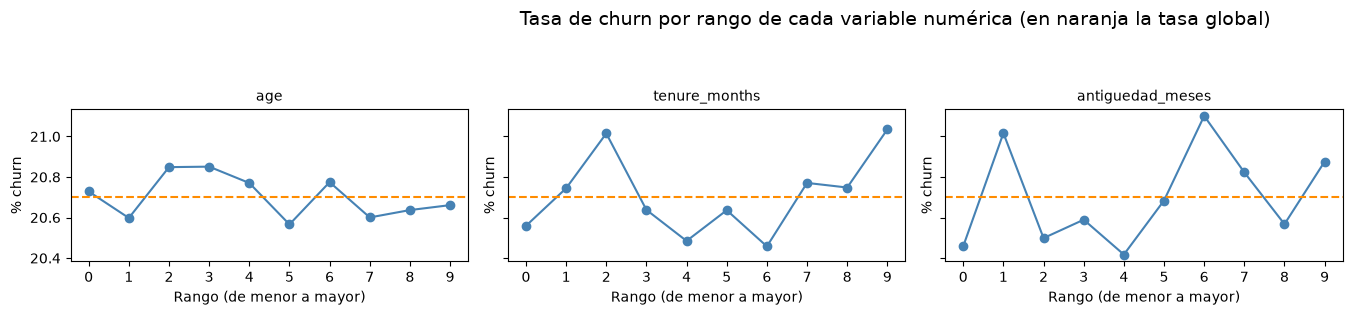

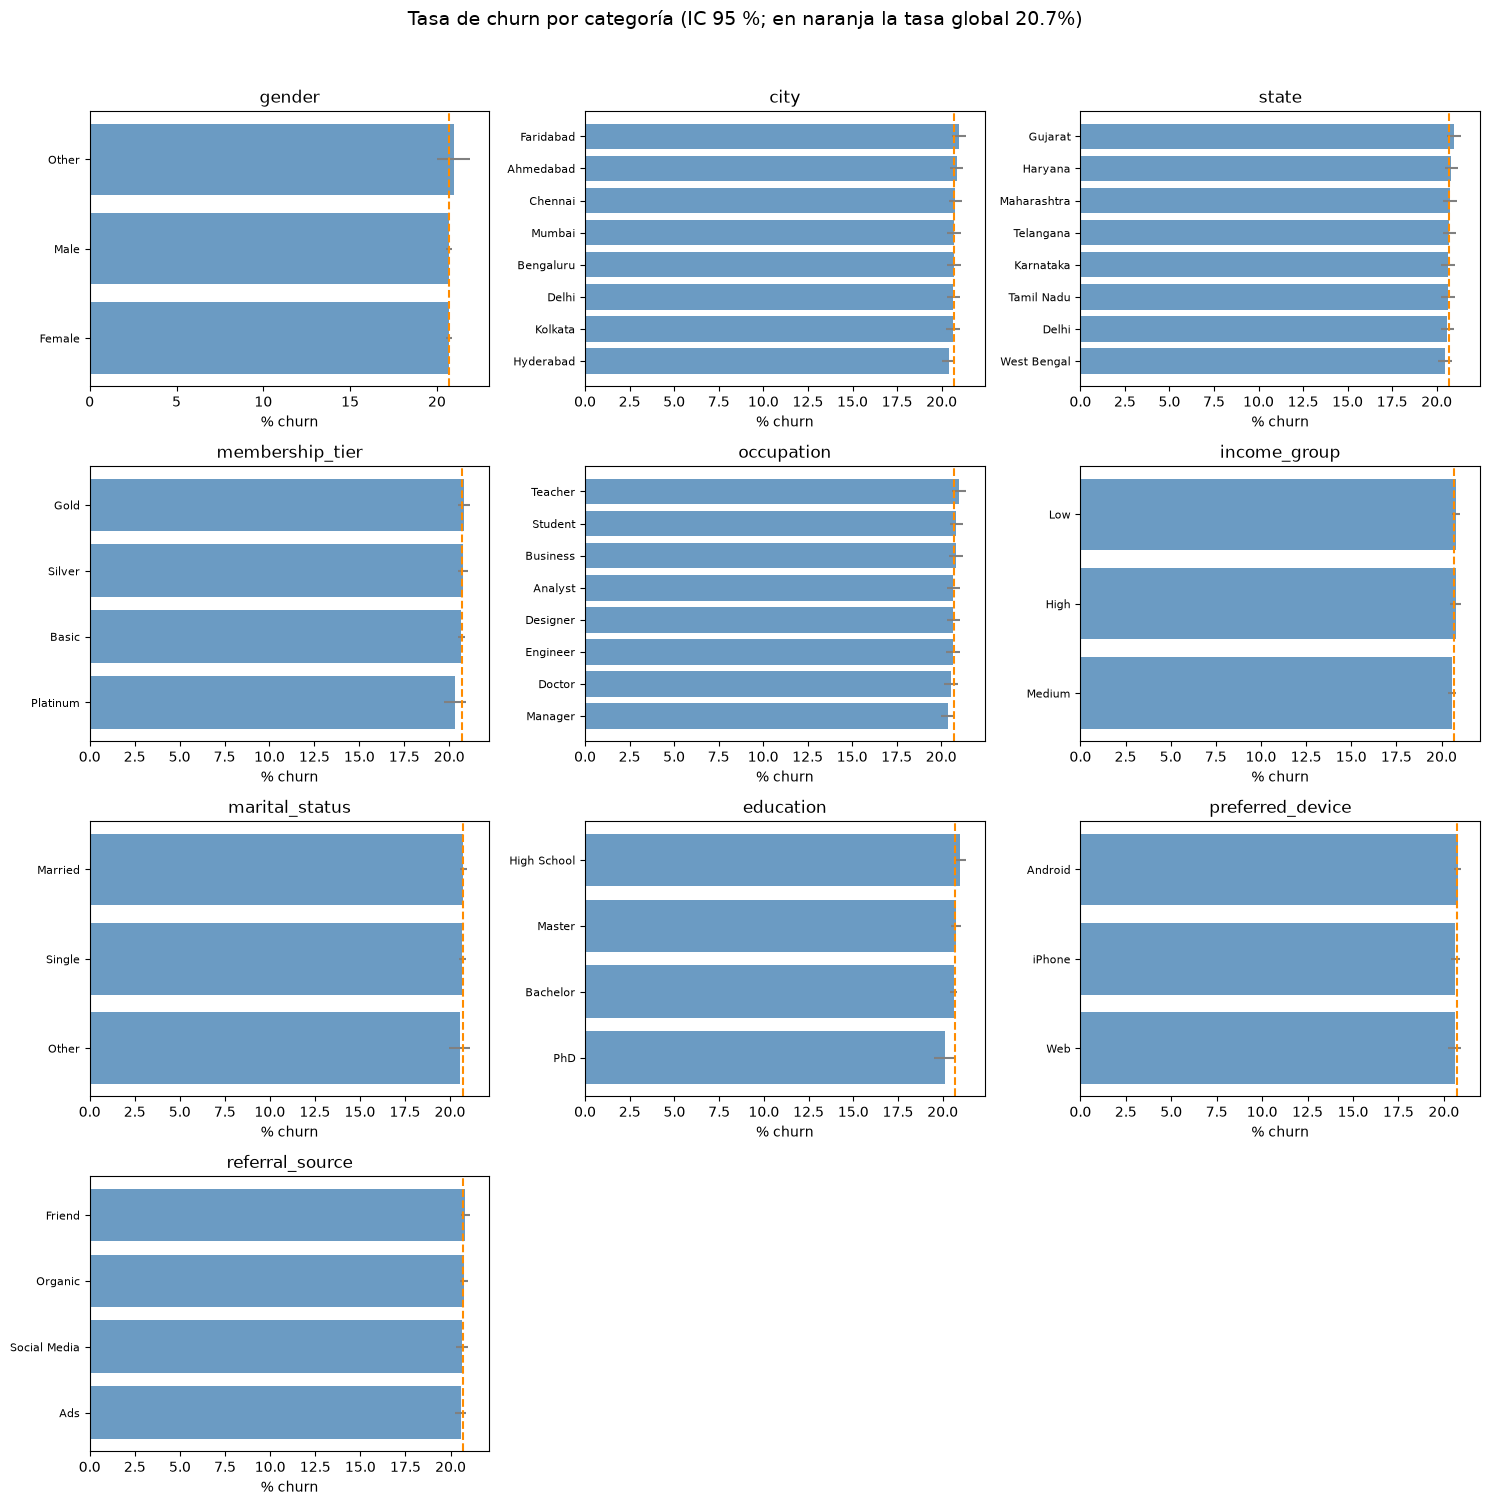

registros    tasa   ic95
variable         categoria                             
gender           Female           171454 20.7000 0.1900
                 Male             171657 20.7000 0.1900
                 Other              6889 20.9600 0.9600
city             Hyderabad         43915 20.3900 0.3800
                 Kolkata           43508 20.6300 0.3800
                 Delhi             43817 20.6600 0.3800
                 Bengaluru         43615 20.6800 0.3800
                 Mumbai            43650 20.6900 0.3800
                 Chennai           43992 20.7700 0.3800
                 Ahmedabad         43848 20.8400 0.3800
                 Faridabad         43655 20.9600 0.3800
state            West Bengal       43811 20.4700 0.3800
                 Delhi             43341 20.6000 0.3800
                 Tamil Nadu        43901 20.6300 0.3800
                 Karnataka         43824 20.6500 0.3800
                 Telangana         44114 20.7200 0.3800
                 Maharashtra       43722 20.7600 0.3800
                 Haryana           43724 20.8200 0.3800
                 Gujarat           43563 20.9800 0.3800
membership_tier  Platinum          17458 20.3300 0.6000
                 Basic            192784 20.6800 0.1800
                 Silver            87215 20.7600 0.2700
                 Gold              52543 20.8200 0.3500
occupation       Manager           43511 20.3700 0.3800
                 Doctor            43930 20.5600 0.3800
                 Engineer          43965 20.6600 0.3800
                 Designer          43843 20.6800 0.3800
                 Analyst           43586 20.6900 0.3800
                 Business          43990 20.8300 0.3800
                 Student           43692 20.8600 0.3800
                 Teacher           43483 20.9900 0.3800
income_group     Medium           156943 20.5800 0.2000
                 High              70235 20.7800 0.3000
                 Low              122822 20.8100 0.2300
marital_status   Other             17512 20.5300 0.6000
                 Single           157520 20.6900 0.2000
                 Married          174968 20.7300 0.1900
education        PhD               17523 20.1200 0.5900
                 Bachelor         174914 20.6200 0.1900
                 Master            87328 20.7500 0.2700
                 High School       70235 20.9800 0.3000
preferred_device Web               52512 20.6000 0.3500
                 iPhone            87832 20.6400 0.2700
                 Android          209656 20.7600 0.1700
referral_source  Ads               70032 20.5600 0.3000
                 Social Media      52500 20.6300 0.3500
                 Organic          139955 20.7300 0.2100
                 Friend            87513 20.8200 0.2700

In [45]:
analizar_grupo("Perfil")

**Conclusión**

Perfil no muestra relación con `churn` por sí solo. Su mayor AUC es 0,503 (`occupation`). La tasa cambia como máximo 0,68
puntos porcentuales entre rangos y 0,86 entre categorías (`education`). Esas diferencias son muy pequeñas frente a la tasa
global de 20,70 %.

#### Interacción digital

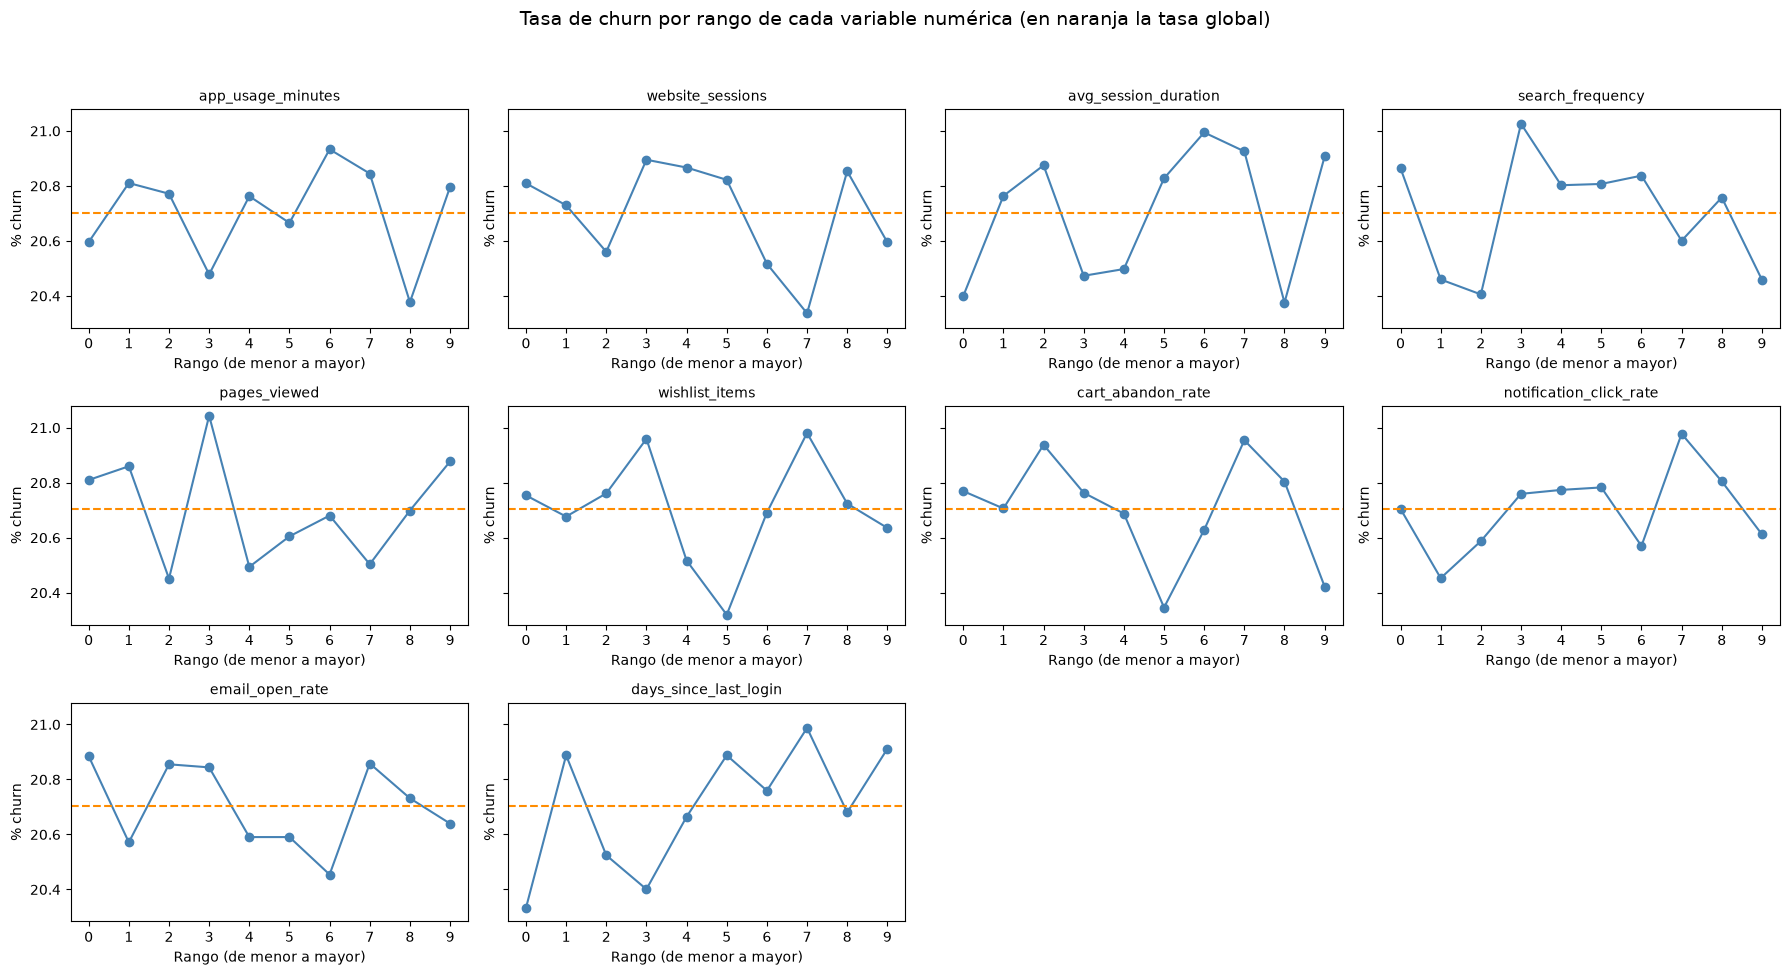

In [46]:
analizar_grupo("Interacción digital")

**Conclusión**

Interacción digital tampoco muestra relación por sí sola. Su mayor AUC es 0,5022 (`days_since_last_login`), y la tasa cambia
como máximo 0,66 puntos porcentuales entre rangos.

#### Pagos

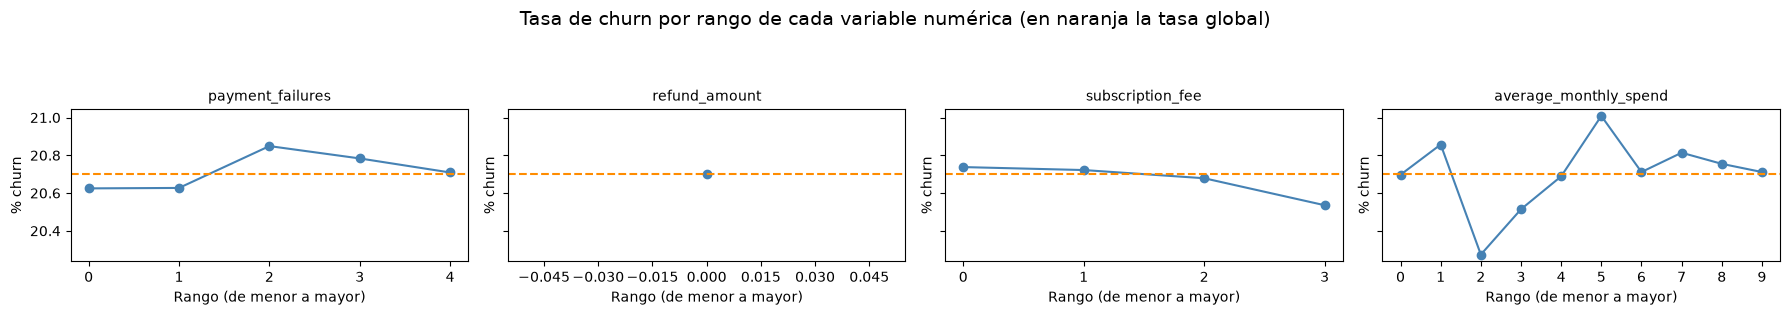

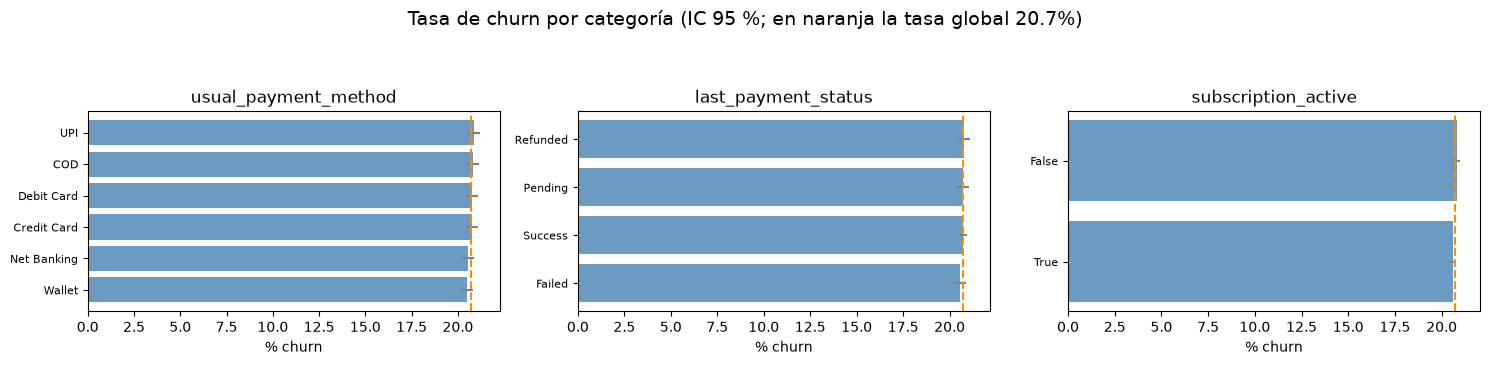

registros    tasa   ic95
variable             categoria                            
usual_payment_method Wallet           58139 20.4800 0.3300
                     Net Banking      58269 20.5500 0.3300
                     Credit Card      58457 20.7500 0.3300
                     Debit Card       58372 20.7500 0.3300
                     COD              58484 20.8200 0.3300
                     UPI              58279 20.8700 0.3300
last_payment_status  Failed           58217 20.5500 0.3300
                     Success         175342 20.7200 0.1900
                     Pending          58270 20.7300 0.3300
                     Refunded         58171 20.7800 0.3300
subscription_active  True            174884 20.5900 0.1900
                     False           175116 20.8100 0.1900

In [47]:
analizar_grupo("Pagos")

**Conclusión**

Pagos no muestra relación por sí solo. Su mayor AUC es 0,5023 (`usual_payment_method`). La tasa cambia como máximo 0,73
puntos porcentuales entre rangos y 0,38 entre categorías.

#### Pedidos (recalculados desde `orders`)

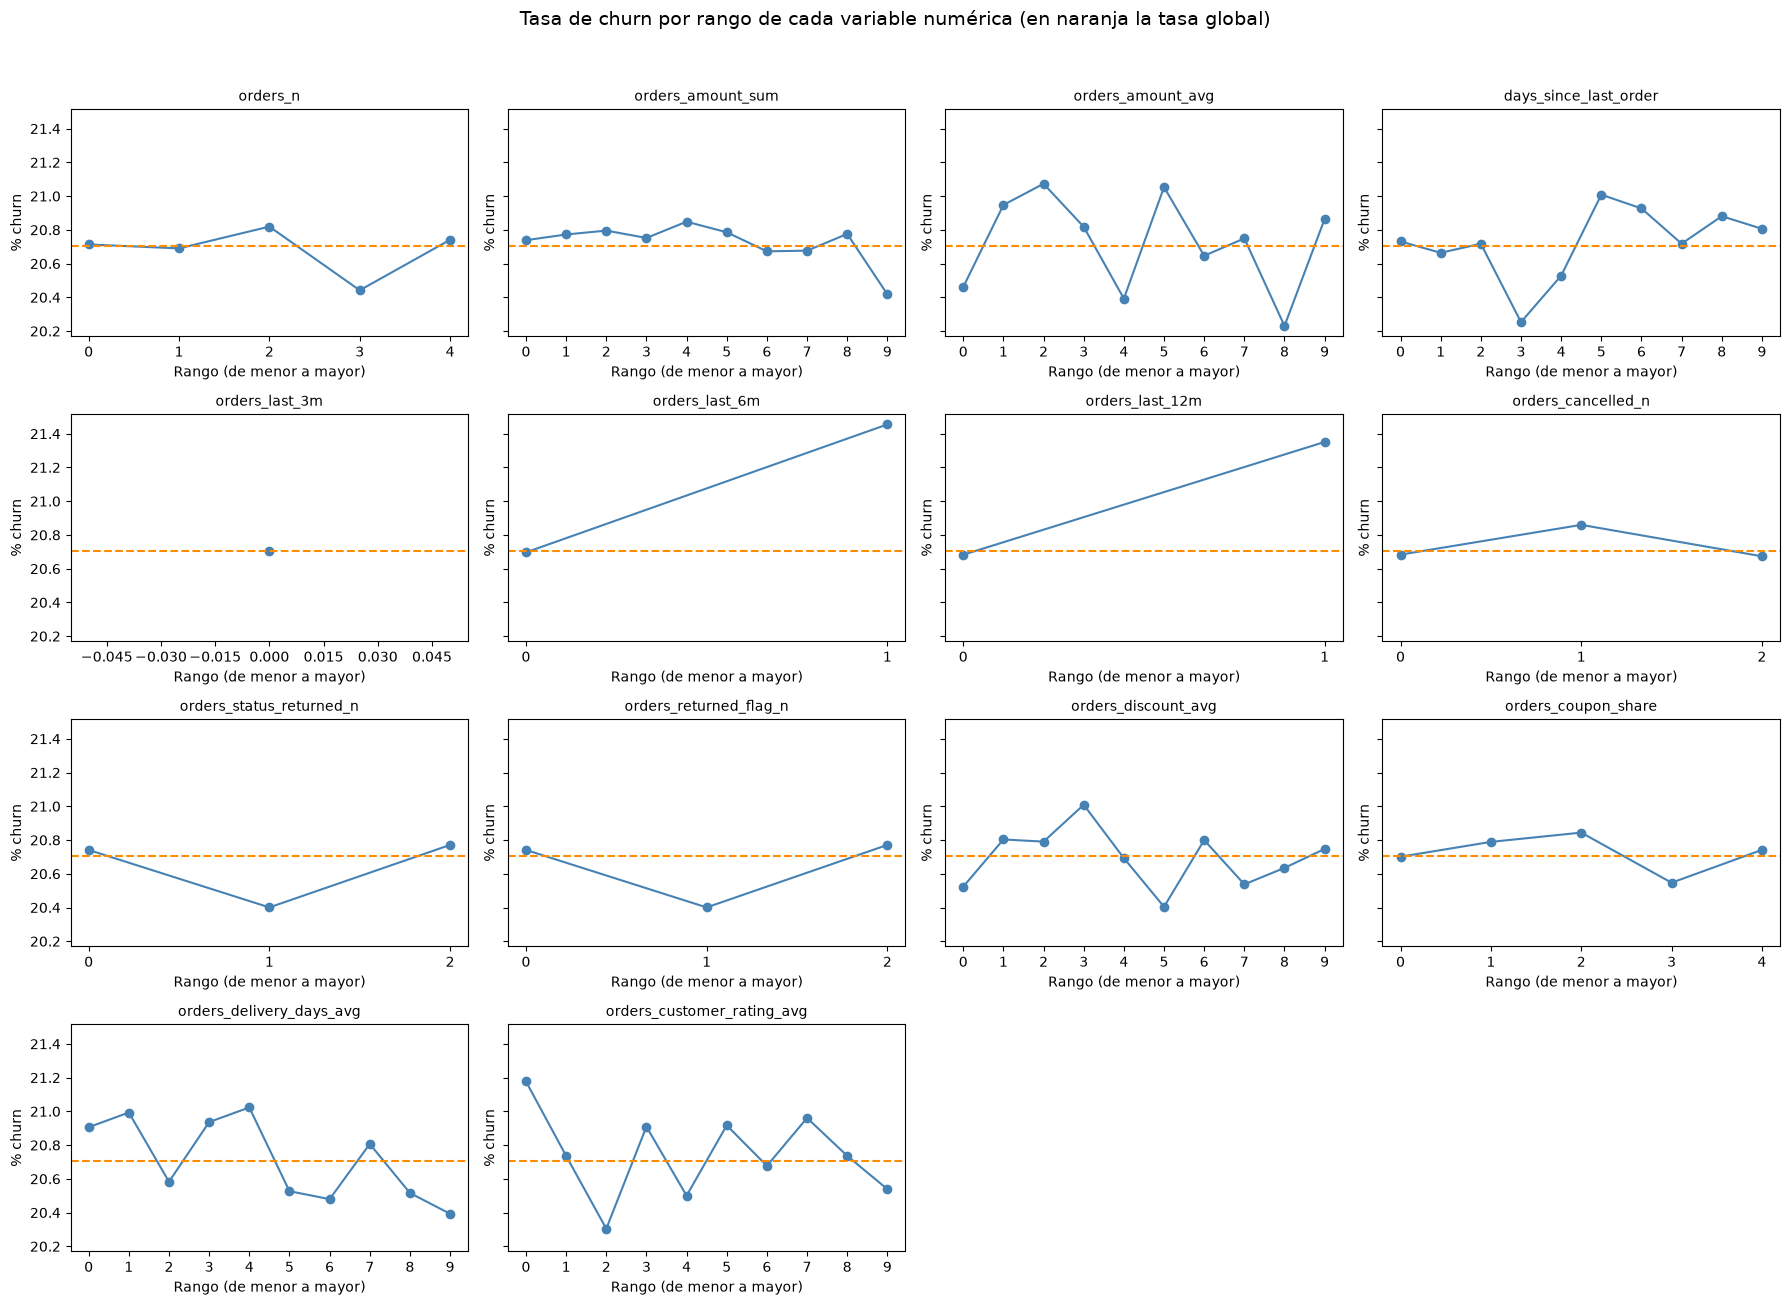

In [48]:
analizar_grupo("Pedidos (recalculados)")

**Conclusión**

Las variables recalculadas de pedidos no muestran relación por sí solas. Su mayor AUC es 0,5028 (`orders_delivery_days_avg`).
Las líneas del gráfico parecen irregulares porque su eje va aproximadamente de 20 % a 21,5 %. La tasa cambia como máximo 0,87
puntos porcentuales.

#### Resumen de cliente (`customer_summary`)

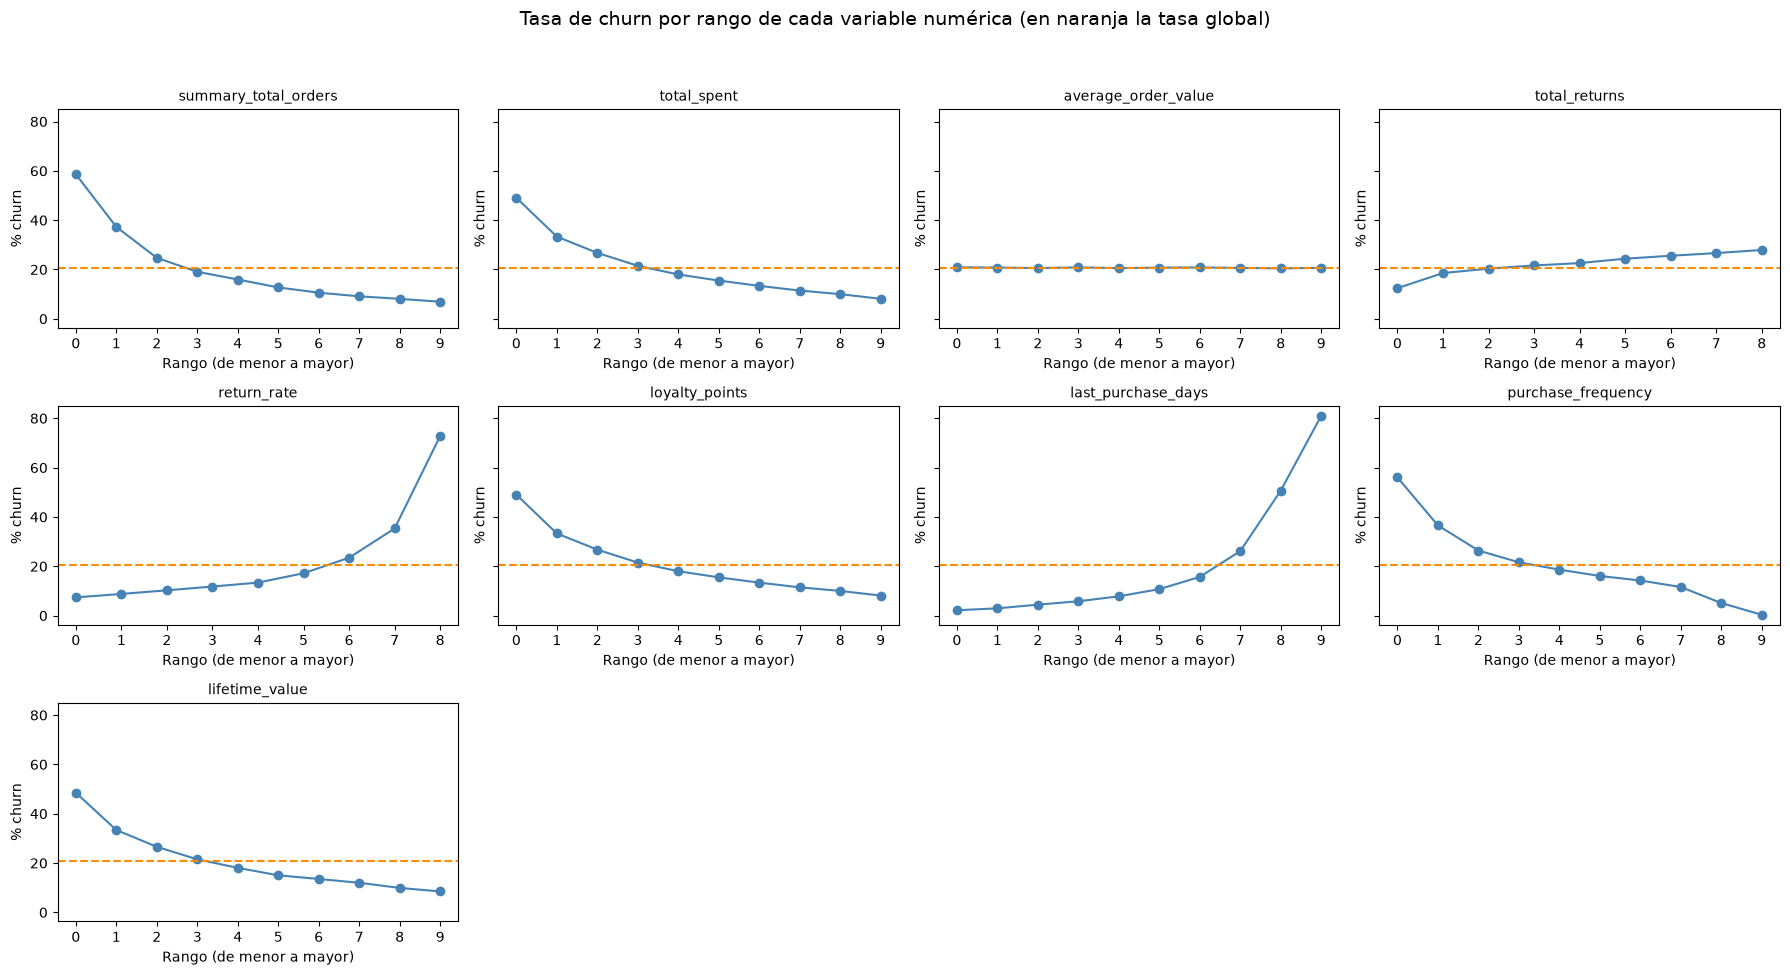

In [49]:
analizar_grupo("Resumen de cliente")

**Conclusión**

Es el único grupo con relaciones fuertes:

- **Mayor churn con valores altos:** `last_purchase_days` pasa de 2,17 % a 81,04 % entre el primer y el último rango, y
  `return_rate` de 7,38 % a 72,84 %.
- **Mayor churn con valores bajos:** `summary_total_orders` pasa de 58,60 % a 6,93 %, y `purchase_frequency` de 56,03 % a
  0,33 %. `total_spent`, `loyalty_points` y `lifetime_value` tienen un patrón parecido, de cerca de 49 % a 8 %.
- **Sin relación:** `average_order_value` tiene un AUC de 0,5012.

Una relación tan fuerte no prueba por sí sola que la variable sirva para predecir: se debe auditar si contiene información de
la etiqueta (sección 5.3).

#### Soporte

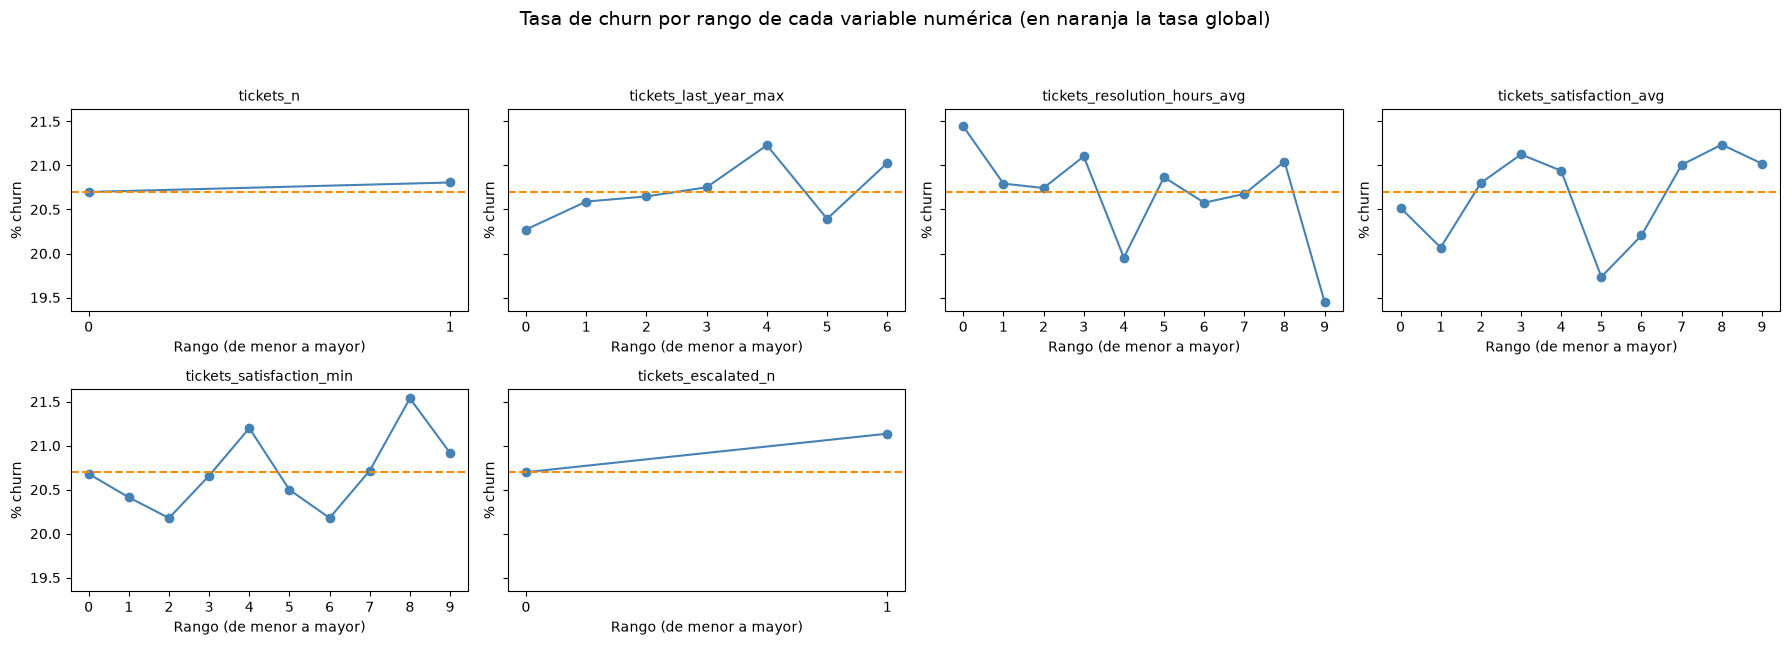

In [50]:
analizar_grupo("Soporte")

**Conclusión**

Soporte no muestra relación clara por sí solo. Su mayor AUC es 0,5052 (`tickets_resolution_hours_avg`). La tasa cambia como
máximo 2 puntos porcentuales entre rangos, y es el grupo con menos clientes por rango, porque solo 25,92 % tiene tickets.

#### Clientes sin pedidos o sin tickets
¿La ausencia de pedidos o de tickets se relaciona con el churn? Si es así, los indicadores `has_orders` y
`has_tickets` son variables útiles por sí mismas.

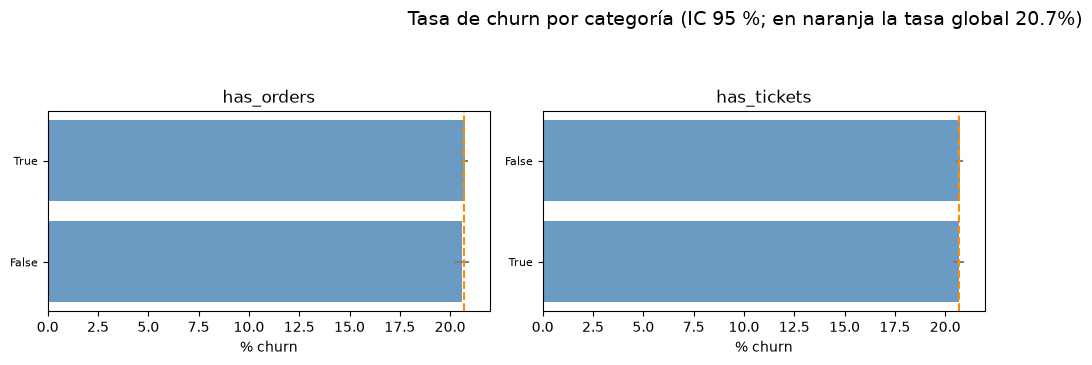

registros    tasa   ic95
variable    categoria                          
has_orders  False          47336 20.5700 0.3600
            True          302664 20.7200 0.1400
has_tickets True           90710 20.6700 0.2600
            False         259290 20.7200 0.1600

In [51]:
eda.tasa_objetivo_por_categoria(train, OBJETIVO, ["has_orders", "has_tickets"])

**Conclusión**

Tener o no pedidos o tickets casi no cambia el churn: la diferencia es de 0,15 puntos porcentuales en `has_orders` y de 0,05
en `has_tickets`.

#### `customer_summary` frente a pedidos recalculados
Se compara el AUC univariado de las variables equivalentes de las 2 fuentes.

In [52]:
pares = [("summary_total_orders", "orders_n"), ("total_spent", "orders_amount_sum"),
         ("average_order_value", "orders_amount_avg"), ("last_purchase_days", "days_since_last_order"),
         ("total_returns", "orders_returned_flag_n")]
pd.DataFrame([
    {"customer_summary": a, "auc_customer_summary": relacion.loc[a, "auc_univariado"],
     "orders": b, "auc_orders": relacion.loc[b, "auc_univariado"]}
    for a, b in pares
])

,customer_summary,auc_customer_summary,orders,auc_orders
0,summary_total_orders,0.7447,orders_n,0.5000
1,total_spent,0.6962,orders_amount_sum,0.5010
2,average_order_value,0.5012,orders_amount_avg,0.5008
3,last_purchase_days,0.8647,days_since_last_order,0.5016
4,total_returns,0.5895,orders_returned_flag_n,0.5006


**Conclusión**

En los 5 pares, la variable de `orders` queda cerca de 0,50. La de `customer_summary` es mayor en 4 de ellos. La excepción es
`average_order_value`, donde ambas están cerca de 0,50. Esto muestra qué fuente se relaciona con `churn`, pero no si esa relación se puede usar para predecir. La auditoría de la
sección 5.3 revisa si estas variables contienen información de la etiqueta.

**Resumen de la revisión**

| Revisión | Resultado | Qué implica |
|---|---|---|
| Variables con relación fuerte | 8 de 61 tienen AUC de 0,55 o más, todas de Resumen de cliente. La mayor es `last_purchase_days` (0,8647) | Se deben auditar antes de considerarlas predictoras |
| Variables sin relación individual | 53 de 61 tienen AUC menor a 0,51. Fuera de Resumen de cliente, la tasa cambia como máximo 2 puntos porcentuales | Por sí solas no separan a quienes abandonan. Esto no descarta relaciones al combinarlas |
| `customer_summary` vs `orders` | En 4 de 5 pares, `customer_summary` tiene mayor AUC, y en todos `orders` queda cerca de 0,50 | La señal está en una sola fuente |
| `has_orders` y `has_tickets` | Diferencias de 0,15 y 0,05 puntos porcentuales | Por sí solos casi no cambian el churn |

**Decisiones**

| Caso | Decisión |
|---|---|
| 8 variables con relación fuerte | No se eligen todavía como predictoras. Se auditan en la sección 5.3 |
| 53 variables sin relación individual | No se descartan todavía. El AUC univariado no mide combinaciones de variables |
| Columnas de `customer_summary` vs columnas `orders_*` | No se elige solo por señal. Se decide después de la auditoría de la sección 5.3 |
| `has_orders` y `has_tickets` | Se conservan, porque indican por qué hay nulos estructurales |

### 5.3 Auditoría de fuga de información

`churn_risk_score` y `customer_segment` vienen de `customer_summary` y podrían contener información de la etiqueta. La
sección 5.2 mostró además que las demás variables de esa tabla concentran toda la relación fuerte con `churn`. Si una
variable así entra al modelo, el desempeño se infla sin que el modelo aprenda a anticipar el abandono. Se audita con 4
preguntas:

1. ¿`churn_risk_score` define `churn`?
2. ¿`customer_segment` sale de otras columnas?
3. ¿Cuánto rinde un modelo con y sin `customer_summary`? (gradient boosting rápido con validación cruzada sobre una
   muestra de `train`)
4. ¿De qué variables sale `churn_risk_score`?

,tipo,pct_nulos,auc_univariado,metrica_efecto,efecto
variable,,,,,
churn_risk_score,numérica,0.0000,1.0000,d_cohen,2.5834
customer_segment,categórica,0.0000,0.8123,v_cramer,0.5736


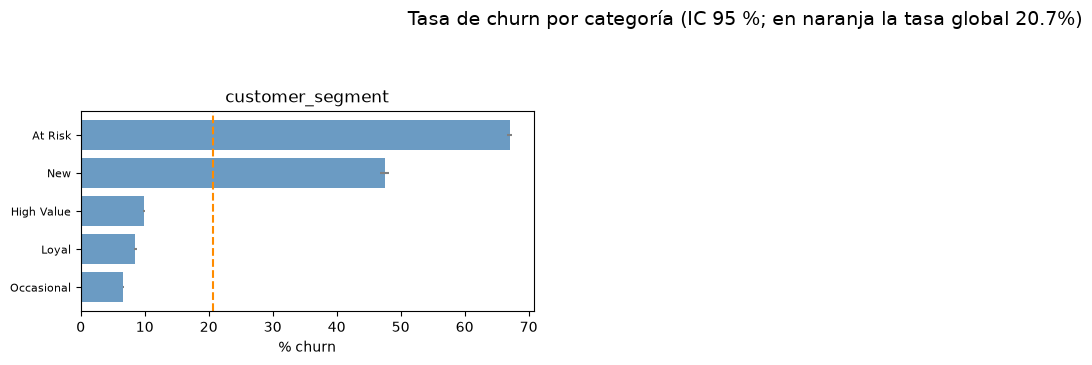

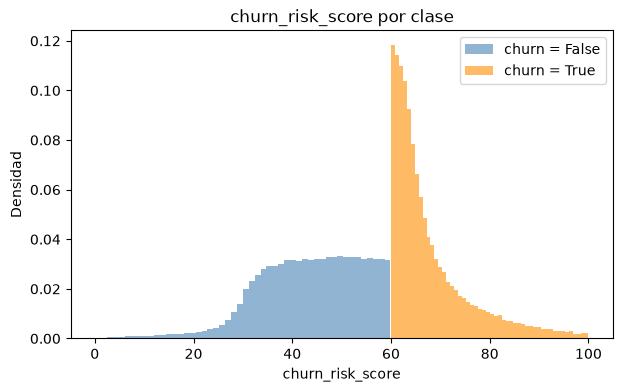

In [53]:
display(eda.resumen_relacion_objetivo(train, OBJETIVO, features.COLUMNAS_FUGA))
eda.tasa_objetivo_por_categoria(train, OBJETIVO, ["customer_segment"])

fig, ax = plt.subplots(figsize=(7, 4))
for clase, color in [(False, "steelblue"), (True, "darkorange")]:
    ax.hist(train.loc[train[OBJETIVO] == clase, "churn_risk_score"].dropna(), bins=50, alpha=0.6,
            density=True, color=color, label=f"churn = {clase}")
ax.set_xlabel("churn_risk_score")
ax.set_ylabel("Densidad")
ax.legend()
ax.set_title("churn_risk_score por clase")
plt.show()

**Conclusión**

`churn_risk_score` tiene AUC de 1,0, sus distribuciones con y sin `churn` no se traslapan. `customer_segment` tiene AUC de
0,8123, solo por debajo de `last_purchase_days` (0,8647) entre las variables de la sección 5.2.

In [54]:
# ¿churn_risk_score define churn?
puntaje = train["churn_risk_score"].astype(float)
tiene_churn = train[OBJETIVO].astype(bool)
print(f"Menor puntaje con churn: {puntaje[tiene_churn].min()}")
print(f"Mayor puntaje sin churn: {puntaje[~tiene_churn].max()}")
print(f"Clientes en los que churn coincide con churn_risk_score >= 60: {100 * ((puntaje >= 60) == tiene_churn).mean():.2f} %")

Menor puntaje con churn: 60.0
Mayor puntaje sin churn: 59.9
Clientes en los que churn coincide con churn_risk_score >= 60: 100.00 %


**Conclusión**

El menor puntaje con `churn` es 60,0 y el mayor sin `churn` es 59,9, así que los datos separan las 2 clases justo en 60. Por eso se
prueba ese umbral: `churn` es exactamente `churn_risk_score >= 60` en todos los clientes de `train`. El puntaje contiene la
etiqueta, así que hay **fuga directa** si se usa como variable.

In [55]:
# ¿customer_segment sale de otras columnas? Primero se miran los rangos de cada segmento
train.groupby("customer_segment").agg(
    clientes=(OBJETIVO, "size"), total_spent_min=("total_spent", "min"), total_spent_max=("total_spent", "max"),
    pedidos_min=("summary_total_orders", "min"), pedidos_max=("summary_total_orders", "max"),
    last_purchase_days_min=("last_purchase_days", "min"), last_purchase_days_max=("last_purchase_days", "max"),
)

,clientes,total_spent_min,total_spent_max,pedidos_min,pedidos_max,last_purchase_days_min,last_purchase_days_max
customer_segment,,,,,,,
At Risk,62224,512.5700,"499,960.4400",1.0000,80.0000,251.0000,365.0000
High Value,105101,"500,014.4500","1,439,544.0000",42.0000,120.0000,0.0000,365.0000
Loyal,46227,"40,574.5200","499,983.1800",81.0000,120.0000,0.0000,365.0000
New,17969,502.2700,"107,838.9000",1.0000,9.0000,0.0000,250.0000
Occasional,118479,"5,026.9000","499,994.0000",10.0000,80.0000,0.0000,250.0000


**Conclusión**

Algunos segmentos tienen límites muy marcados: `At Risk` empieza en 251 días de `last_purchase_days`, `High Value` cerca de
500.000 de `total_spent`, `Loyal` en 81 pedidos y `New` llega hasta 9 pedidos. Eso sugiere reglas fijas, pero estas columnas se
eligieron a simple vista. El árbol de decisión de la siguiente celda lo comprueba sin indicarle qué columnas ni qué cortes usar.

In [56]:
# Árbol de decisión: se entrena con una mitad de train y se evalúa con la otra, con las 9 variables de customer_summary
columnas_resumen = [c for c in features.GRUPOS_VARIABLES["Resumen de cliente"] if c in NUMERICAS]
mitad_a, mitad_b = train_test_split(train, test_size=0.5, stratify=train["customer_segment"], random_state=SEMILLA)
X_a, X_b = mitad_a[columnas_resumen].astype(float), mitad_b[columnas_resumen].astype(float)

exactitud = {}
for profundidad in [2, 3, 4, 5]:
    arbol = DecisionTreeClassifier(max_depth=profundidad, random_state=SEMILLA).fit(X_a, mitad_a["customer_segment"])
    exactitud[profundidad] = arbol.score(X_b, mitad_b["customer_segment"])
display(pd.Series(exactitud, name="exactitud_en_la_otra_mitad").rename_axis("profundidad").round(4).to_frame())

arbol = DecisionTreeClassifier(max_depth=4, random_state=SEMILLA).fit(X_a, mitad_a["customer_segment"])
print("Reglas del árbol de profundidad 4:")
print(export_text(arbol, feature_names=columnas_resumen))
importancia = pd.Series(arbol.feature_importances_, index=columnas_resumen)
print("Columnas que usa el árbol:", ", ".join(importancia[importancia > 0].sort_values(ascending=False).index))

,exactitud_en_la_otra_mitad
profundidad,
2,0.8166
3,0.9487
4,1.0000
5,1.0000


Reglas del árbol de profundidad 4:
|--- total_spent <= 500004.22
|   |--- last_purchase_days <= 250.50
|   |   |--- summary_total_orders <= 80.50
|   |   |   |--- summary_total_orders <= 9.50
|   |   |   |   |--- class: New
|   |   |   |--- summary_total_orders >  9.50
|   |   |   |   |--- class: Occasional
|   |   |--- summary_total_orders >  80.50
|   |   |   |--- class: Loyal
|   |--- last_purchase_days >  250.50
|   |   |--- summary_total_orders <= 80.50
|   |   |   |--- class: At Risk
|   |   |--- summary_total_orders >  80.50
|   |   |   |--- class: Loyal
|--- total_spent >  500004.22
|   |--- class: High Value

Columnas que usa el árbol: summary_total_orders, total_spent, last_purchase_days


**Conclusión**

Con profundidad 4, el árbol clasifica correctamente al 100 % de los clientes de la mitad que no usó para entrenar. De las 9
variables usa solo `summary_total_orders`, `total_spent` y `last_purchase_days`, con cortes cercanos a 500.000, 81, 251 y 9.

In [57]:
# Regla simplificada a partir de los cortes del árbol, con cifras redondas y aplicada en orden
segmento_por_regla = np.select(
    [train["total_spent"] >= 500_000, train["summary_total_orders"] >= 81, train["last_purchase_days"] >= 251,
     train["summary_total_orders"] <= 9],
    ["High Value", "Loyal", "At Risk", "New"], default="Occasional",
)
print(f"Clientes cuyo customer_segment coincide con la regla: {100 * (segmento_por_regla == train['customer_segment']).mean():.2f} %")

Clientes cuyo customer_segment coincide con la regla: 100.00 %


**Conclusión**

`customer_segment` se reproduce en todos los clientes de `train` con esta regla, aplicada en orden: `High Value` si `total_spent`
es 500.000 o más, `Loyal` si `summary_total_orders` es 81 o más, `At Risk` si `last_purchase_days` es 251 o más, `New` si
`summary_total_orders` es 9 o menos, y `Occasional` en el resto. Las cifras redondas son nuestra interpretación de los cortes del
árbol, porque el dataset no documenta la regla.

La regla no necesita `churn`, así que el segmento **no es una fuga directa como el puntaje**. Es un resumen de otras columnas de
`customer_summary`.

In [58]:
def crear_modelo_rapido(numericas, categoricas, estimador=None):
    # Diagnóstico, no el modelo final: las categóricas se codifican como ordinales y los nulos los maneja el modelo
    preprocesador = ColumnTransformer([
        ("categoricas", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-2,
                                       encoded_missing_value=-1), categoricas),
        ("numericas", "passthrough", numericas),
    ])
    return Pipeline([
        ("preprocesador", preprocesador),
        ("modelo", estimador or HistGradientBoostingClassifier(max_iter=200, random_state=SEMILLA)),
    ])


def preparar_X(df, numericas, categoricas, booleanas):
    X = df[numericas + categoricas + booleanas].copy()
    X[booleanas] = X[booleanas].astype(float)
    return X


def separar_por_tipo(variables):
    """Devuelve las variables separadas en numéricas, categóricas y booleanas."""
    categoricas = [c for c in variables if c in CATEGORICAS or c == "customer_segment"]
    booleanas = [c for c in variables if c in BOOLEANAS]
    numericas = [c for c in variables if c not in categoricas and c not in booleanas]
    return numericas, categoricas, booleanas


muestra_train = train.sample(min(100_000, len(train)), random_state=SEMILLA)
y_muestra = muestra_train[OBJETIVO].astype(int)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA)

TODAS = NUMERICAS + CATEGORICAS + BOOLEANAS
RESUMEN = [c for c in features.GRUPOS_VARIABLES["Resumen de cliente"] if c in TODAS]
SIN_RESUMEN = [c for c in TODAS if c not in RESUMEN]
# Las 3 variables de mayor AUC univariado en la sección 5.2
TRES_VARIABLES = ["last_purchase_days", "return_rate", "purchase_frequency"]
RESUMEN_SIN_LAS_TRES = [c for c in RESUMEN if c not in TRES_VARIABLES]

escenarios = {
    "A. Sin customer_summary": SIN_RESUMEN,
    "B. Solo customer_summary, sin puntaje ni segmento": RESUMEN,
    "Todas, sin puntaje ni segmento": TODAS,
    "last_purchase_days, return_rate y purchase_frequency": TRES_VARIABLES,
    "customer_summary sin esas 3 variables": RESUMEN_SIN_LAS_TRES,
    "A + customer_segment": SIN_RESUMEN + ["customer_segment"],
    "Todas + customer_segment": TODAS + ["customer_segment"],
    "Todas + churn_risk_score": TODAS + ["churn_risk_score"],
}
auditoria = {}
for nombre, variables in escenarios.items():
    numericas, categoricas, booleanas = separar_por_tipo(variables)
    X = preparar_X(muestra_train, numericas, categoricas, booleanas)
    modelo = crear_modelo_rapido(numericas + booleanas, categoricas)
    resultado = cross_validate(modelo, X, y_muestra, cv=cv, scoring=["roc_auc", "average_precision"], n_jobs=-1)
    auditoria[nombre] = {
        "variables": len(variables), "roc_auc": resultado["test_roc_auc"].mean(),
        "pr_auc": resultado["test_average_precision"].mean(),
    }
print(f"Tasa de churn en la muestra, referencia de PR-AUC al azar: {y_muestra.mean():.4f}")
pd.DataFrame(auditoria).T.astype({"variables": int}).round(4)

Tasa de churn en la muestra, referencia de PR-AUC al azar: 0.2064


,variables,roc_auc,pr_auc
A. Sin customer_summary,52,0.4990,0.2064
"B. Solo customer_summary, sin puntaje ni segmento",9,0.9999,0.9995
"Todas, sin puntaje ni segmento",61,0.9999,0.9994
"last_purchase_days, return_rate y purchase_frequency",3,0.9999,0.9996
customer_summary sin esas 3 variables,6,0.7766,0.5911
A + customer_segment,53,0.8093,0.5647
Todas + customer_segment,62,0.9998,0.9994
Todas + churn_risk_score,62,1.0000,1.0000


**Conclusión**

- **Sin el puntaje ni el segmento** pero con las demás variables, el AUC sigue en 0,9999. Agregar `churn_risk_score` lo
  lleva a 1,0 y agregar `customer_segment` no lo mejora.
- **Sin `customer_summary`,** las 52 variables restantes dan AUC de 0,499 y PR-AUC de 0,2064, igual que el azar.
- **Solo 3 variables concentran la señal:** `last_purchase_days`, `return_rate` y `purchase_frequency`, las 3 de mayor AUC
  univariado en la sección 5.2 (0,8647, 0,7722 y 0,7536), dan AUC de 0,9999. Las otras 6 variables de `customer_summary` bajan a
  0,7766.
- **`customer_segment` reintroduce señal:** agregado a las 52 variables, sube el AUC de 0,499 a 0,8093.

In [59]:
# ¿De qué variables sale churn_risk_score? R² y error fuera de muestra, con validación cruzada
puntaje_muestra = muestra_train["churn_risk_score"].astype(float)
kf = KFold(n_splits=3, shuffle=True, random_state=SEMILLA)
origen = {}
for nombre, variables in {
    "last_purchase_days, return_rate y purchase_frequency": TRES_VARIABLES,
    "customer_summary sin esas 3 variables": RESUMEN_SIN_LAS_TRES,
    "Sin customer_summary": SIN_RESUMEN,
}.items():
    numericas, categoricas, booleanas = separar_por_tipo(variables)
    regresor = crear_modelo_rapido(numericas + booleanas, categoricas,
                                   HistGradientBoostingRegressor(max_iter=200, random_state=SEMILLA))
    prediccion = cross_val_predict(regresor, preparar_X(muestra_train, numericas, categoricas, booleanas), puntaje_muestra, cv=kf)
    origen[nombre] = {"r2": r2_score(puntaje_muestra, prediccion), "error_absoluto_medio": mean_absolute_error(puntaje_muestra, prediccion)}
pd.DataFrame(origen).T.round(4)

,r2,error_absoluto_medio
"last_purchase_days, return_rate y purchase_frequency",0.9994,0.2195
customer_summary sin esas 3 variables,0.3302,9.5279
Sin customer_summary,-0.0007,11.1248


**Conclusión**

`last_purchase_days`, `return_rate` y `purchase_frequency` explican casi todo el puntaje (R² de 0,9994 y error absoluto medio de
0,22 sobre una escala de 0 a 100). Las 52 variables fuera de `customer_summary` no lo explican (R² cercano a 0).

**Resumen de la revisión**

| Revisión | Resultado | Qué implica |
|---|---|---|
| `churn_risk_score` | `churn` es exactamente `churn_risk_score >= 60` en todos los clientes | Fuga directa |
| `customer_segment` | Se reproduce con una regla sobre `total_spent`, `summary_total_orders` y `last_purchase_days` | No usa `churn`, pero resume otras columnas y reintroduce señal |
| Modelo sin `customer_summary` | AUC de 0,499 y PR-AUC de 0,2064 con 52 variables | Igual que el azar |
| Modelo con `customer_summary` | AUC de 0,9999 con sus 9 variables, sin puntaje ni segmento | Las variables se pueden usar. El AUC es tan alto porque `churn` parece calculado a partir de ellas |
| Origen del puntaje | R² de 0,9994 con `last_purchase_days`, `return_rate` y `purchase_frequency` | Probablemente reconstruyen la regla que definió `churn` |

**Decisiones**

| Variable o grupo | AUC univariado | Efecto en el modelo | Decisión |
|---|---|---|---|
| `churn_risk_score` | 1,0 | Lleva el AUC a 1,0 | **Se excluye**, por fuga directa |
| `customer_segment` | 0,8123 | No mejora el AUC con las demás variables. Pero lo sube a 0,8093 sin `customer_summary` | **Se excluye**, porque no aporta nada propio y reintroduce señal |
| Otras 9 variables de `customer_summary` | Hasta 0,8647 | AUC de 0,9999 | **Se conservan como escenario principal** |

**Decisión sobre `customer_summary`:** el escenario principal usa sus 9 variables, sin puntaje ni segmento (la sección 5.4 revisa si alguna es redundante). Están disponibles y Kaggle presenta la tabla como lista para modelar. El escenario con las otras 52 variables, sin `customer_summary`, se reporta como comparación. El AUC de 0,9999 es tan alto porque `churn` parece calculado a partir de estas 9 variables, así que el modelo reproduce esa relación casi perfectamente.

**Sobre la documentación del dataset:** Kaggle no indica cómo se calcularon `churn_risk_score` ni `churn`, ni advierte sobre fuga. La exclusión de `churn_risk_score` se concluye a partir de los datos, no de la documentación.

### 5.4 Análisis multivariado
Correlaciones, redundancias y multicolinealidad. La multicolinealidad importa sobre todo para la regresión
logística, cuyos coeficientes se usarán para la interpretación (Explainable AI).

Correlación de Spearman entre las variables de Interacción digital:


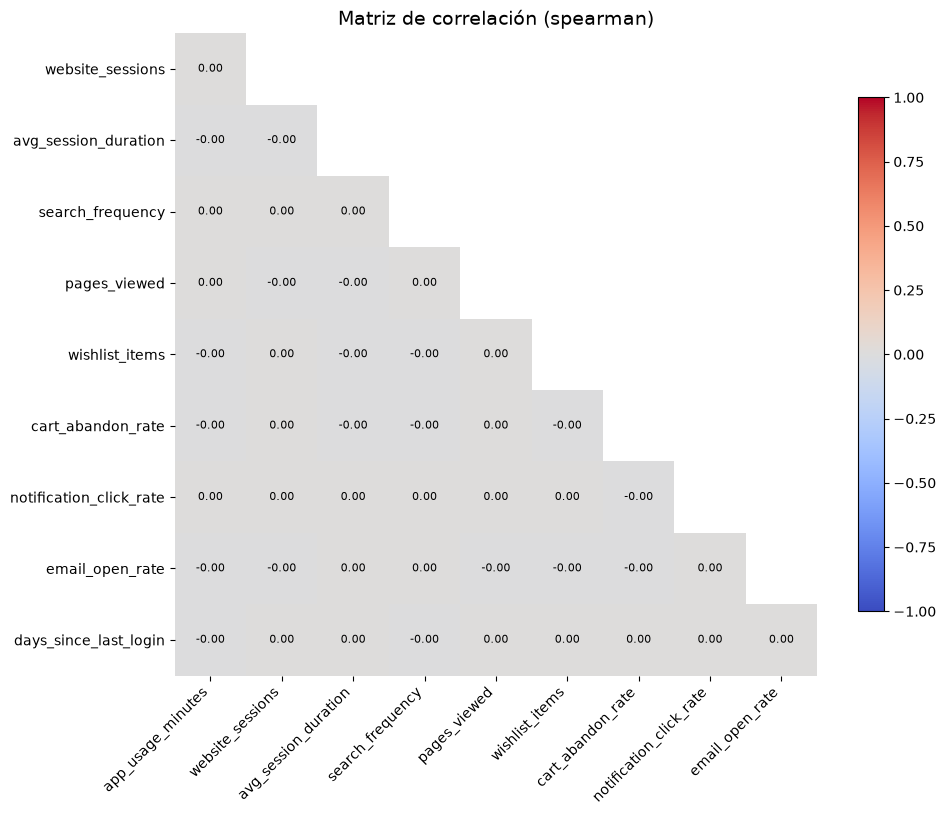

Correlación de Spearman entre las variables de Pagos:


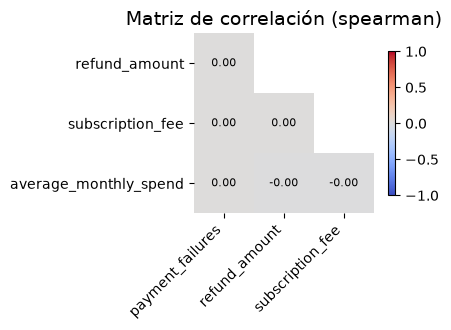

Correlación de Spearman entre las variables de Resumen de cliente:


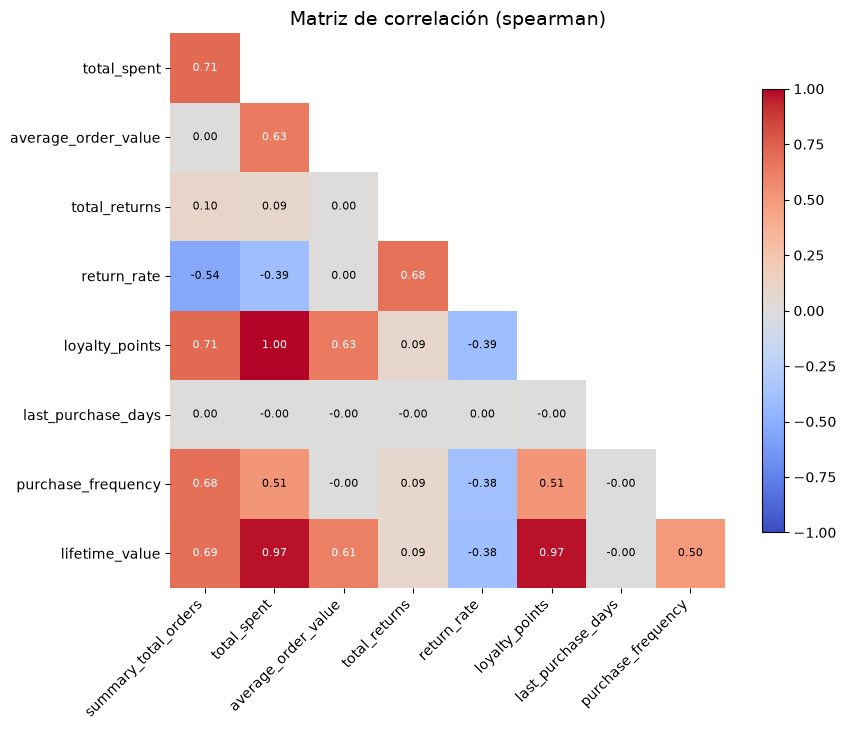

Correlación de Spearman entre las variables de Pedidos (recalculados):


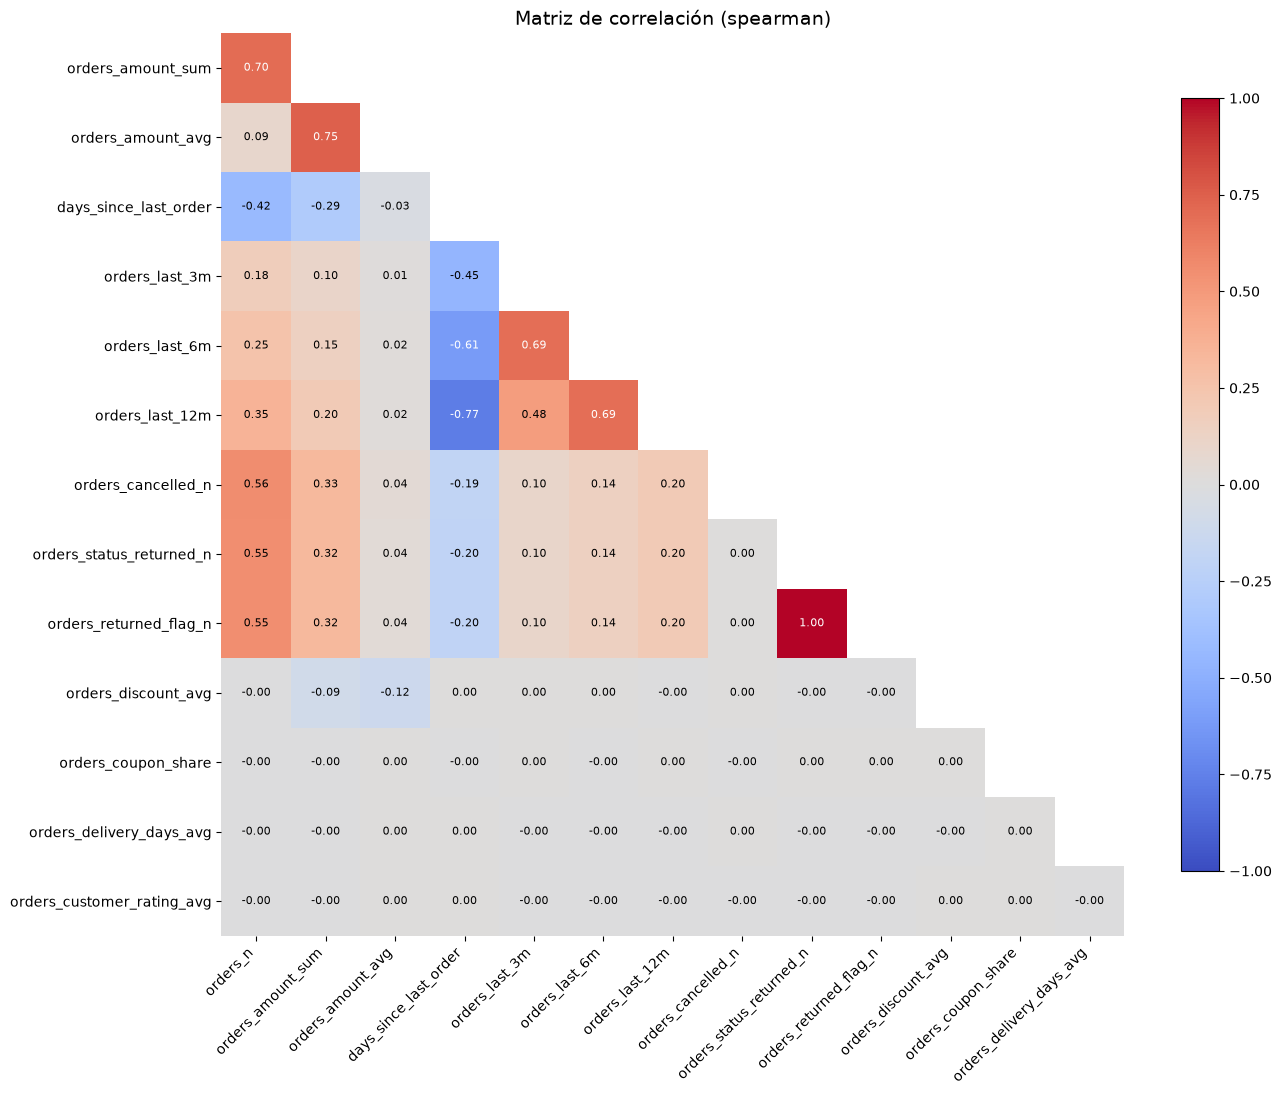

Correlación de Spearman entre las variables de Soporte:


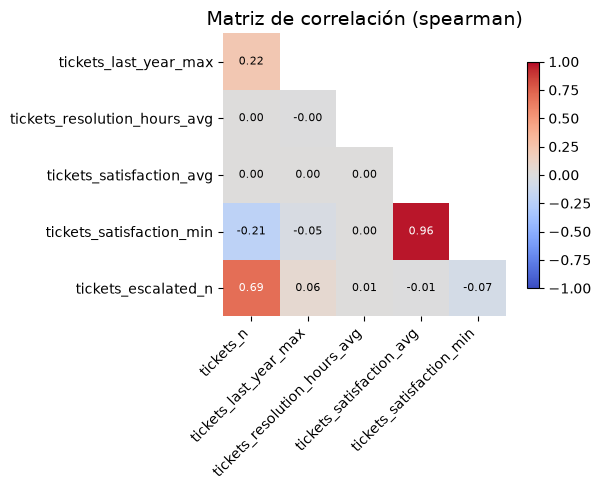

In [60]:
for grupo in ["Interacción digital", "Pagos", "Resumen de cliente", "Pedidos (recalculados)", "Soporte"]:
    cols = [c for c in features.GRUPOS_VARIABLES[grupo] if c in NUMERICAS]
    if len(cols) > 1:
        print(f"Correlación de Spearman entre las variables de {grupo}:")
        eda.graficar_matriz_correlacion(train, "spearman", cols)

**Conclusión**

Hay grupos de variables muy parecidas entre sí. En Resumen de cliente, `total_spent` tiene correlación de 1,00 con `loyalty_points`
y de 0,97 con `lifetime_value`. `last_purchase_days`, en cambio, no se correlaciona con ninguna de las demás variables de ese grupo.

In [61]:
# Pares muy correlacionados entre todos los grupos
corr = train[NUMERICAS].corr(method="spearman")
pares_corr = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
              .rename("spearman").rename_axis(["variable_1", "variable_2"]).reset_index())
pares_corr[pares_corr["spearman"].abs() > 0.7].sort_values("spearman", key=abs, ascending=False)

,variable_1,variable_2,spearman
1552,orders_status_returned_n,orders_returned_flag_n,1.0000
803,total_spent,loyalty_points,1.0000
990,loyalty_points,lifetime_value,0.9738
806,total_spent,lifetime_value,0.9738
1975,tickets_satisfaction_avg,tickets_satisfaction_min,0.9618
1319,days_since_last_order,orders_last_12m,-0.7716
1223,orders_amount_sum,orders_amount_avg,0.7472
757,summary_total_orders,loyalty_points,0.7097
753,summary_total_orders,total_spent,0.7097


**Conclusión**

- **Prácticamente idénticas:** `orders_status_returned_n` y `orders_returned_flag_n`, y `total_spent` y `loyalty_points`.
- **Muy parecidas:** `lifetime_value` con `total_spent` (0,97) y `tickets_satisfaction_avg` con `tickets_satisfaction_min` (0,96).
- **Moderadas:** los demás pares, entre 0,71 y 0,77 en valor absoluto, miden aspectos relacionados, pero no lo mismo.

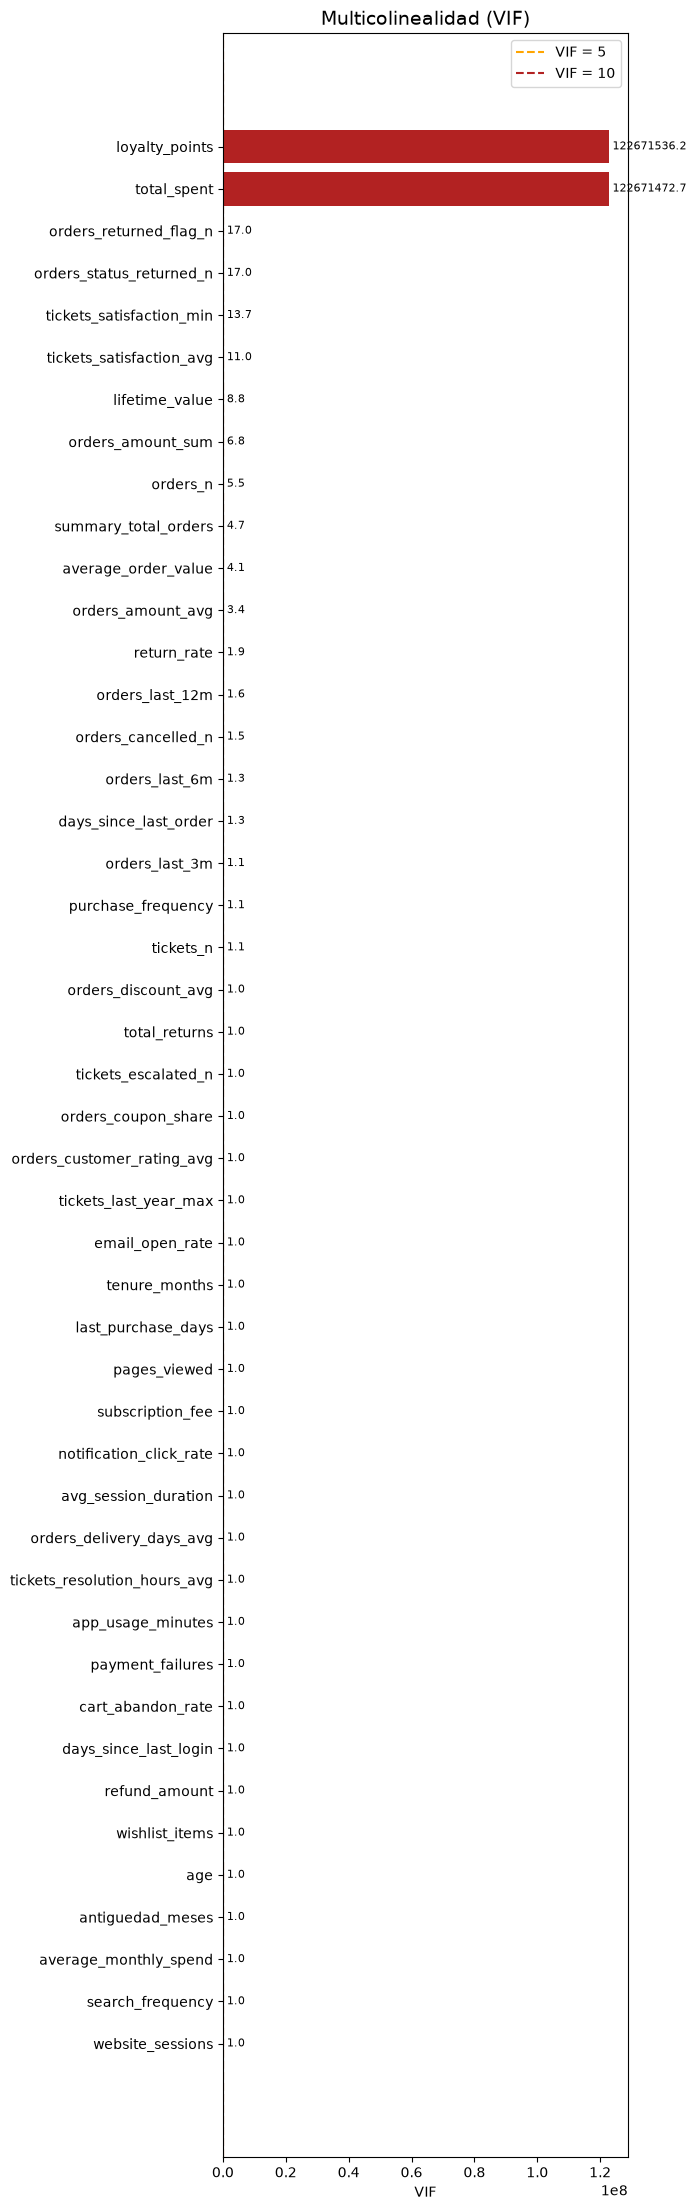

orders_n                             5.4900
orders_amount_sum                    6.8300
lifetime_value                       8.8400
tickets_satisfaction_avg            10.9700
tickets_satisfaction_min            13.6800
orders_status_returned_n            16.9600
orders_returned_flag_n              16.9600
total_spent                122,671,472.7300
loyalty_points             122,671,536.2100
Name: VIF, dtype: float64

In [62]:
# VIF sobre los clientes con pedidos y tickets (calcular_vif excluye las filas con nulos)
vif = eda.calcular_vif(train.sample(min(50_000, len(train)), random_state=SEMILLA), NUMERICAS,
                       nombre_figura="vif")
vif[vif > 5]

**Conclusión**

`total_spent` y `loyalty_points` tienen un VIF superior a 100 millones (una se puede calcular casi exactamente con la otra). También
superan 10 `orders_status_returned_n`, `orders_returned_flag_n`, `tickets_satisfaction_avg` y `tickets_satisfaction_min`. Este cálculo
solo incluye clientes con pedidos y tickets, porque excluye las filas con nulos.

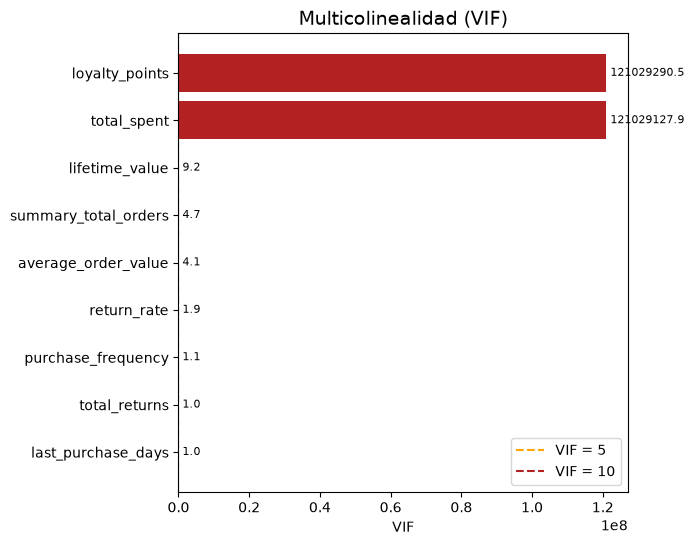

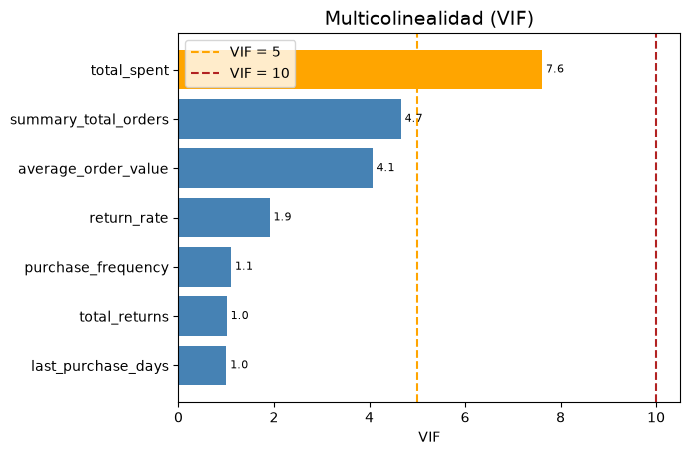

,9 variables,7 variables
loyalty_points,"121,029,290.4900",NaN
total_spent,"121,029,127.8700",7.6100
lifetime_value,9.1700,NaN
summary_total_orders,4.6500,4.6500
average_order_value,4.0600,4.0600
return_rate,1.9100,1.9100
purchase_frequency,1.1000,1.1000
total_returns,1.0100,1.0100
last_purchase_days,1.0000,1.0000


In [63]:
# VIF de las variables de customer_summary, antes y después de quitar las redundantes (estas no tienen nulos)
vif_resumen = pd.DataFrame({
    "9 variables": eda.calcular_vif(train, RESUMEN),
    "7 variables": eda.calcular_vif(train, features.VARIABLES_ESCENARIO_PRINCIPAL),
}).sort_values("9 variables", ascending=False).round(2)
vif_resumen

**Conclusión**

Con las 9 variables de `customer_summary`, el VIF de `total_spent` y `loyalty_points` supera los 100 millones. Al quitar
`loyalty_points` y `lifetime_value`, el mayor VIF baja a 7,61 (`total_spent`), una multicolinealidad moderada. `total_spent` se
relaciona con `summary_total_orders` y `average_order_value`, porque el gasto es el producto de ambas.

In [64]:
# ¿lifetime_value aporta algo frente a total_spent?
variables_redundantes = ["total_spent", "lifetime_value"]
eda.correlacion_parcial(train, OBJETIVO, variables_redundantes)

,correlacion_simple,parcial (controlando las otras),parcial (controlando las otras + extra)
variable,,,
total_spent,-0.2350,-0.0780,-0.0780
lifetime_value,-0.2220,-0.0020,-0.0020


**Conclusión**

La correlación simple con `churn` es parecida: −0,235 en `total_spent` y −0,222 en `lifetime_value`. Al controlar una por la otra,
`total_spent` conserva −0,078, mientras que `lifetime_value` baja a −0,002. Es decir, `lifetime_value` casi no aporta sobre `churn`
una vez se conoce `total_spent`.

In [65]:
# ¿Cambia el rendimiento al quitar las variables redundantes? Misma muestra y validación cruzada de la sección 5.3
principal_sin_lealtad = [c for c in RESUMEN if c != "loyalty_points"]
comparacion = [c for c in SIN_RESUMEN if c not in features.COLUMNAS_REDUNDANTES]
filas = []
for nombre, variables in {
    "customer_summary: 9 variables": RESUMEN,
    "Sin loyalty_points: 8 variables": principal_sin_lealtad,
    "Sin loyalty_points ni lifetime_value: 7 variables": features.VARIABLES_ESCENARIO_PRINCIPAL,
    "Comparación sin customer_summary: 52 variables": SIN_RESUMEN,
    "Comparación sin orders_status_returned_n: 51 variables": comparacion,
}.items():
    numericas, categoricas, booleanas = separar_por_tipo(variables)
    X = preparar_X(muestra_train, numericas, categoricas, booleanas)
    r = cross_validate(crear_modelo_rapido(numericas + booleanas, categoricas), X, y_muestra, cv=cv,
                       scoring=["roc_auc", "average_precision"], n_jobs=-1)
    fila = {"variables": nombre, "roc_auc_gradient_boosting": r["test_roc_auc"].mean(), "pr_auc_gradient_boosting": r["test_average_precision"].mean()}
    if not categoricas:
        logistica = Pipeline([("escala", StandardScaler()), ("modelo", LogisticRegression(max_iter=2000))])
        r = cross_validate(logistica, X, y_muestra, cv=cv, scoring=["roc_auc", "average_precision"], n_jobs=-1)
        fila.update({"roc_auc_logistica": r["test_roc_auc"].mean(), "pr_auc_logistica": r["test_average_precision"].mean()})
    filas.append(fila)
pd.DataFrame(filas).set_index("variables").round(4)

,roc_auc_gradient_boosting,pr_auc_gradient_boosting,roc_auc_logistica,pr_auc_logistica
variables,,,,
customer_summary: 9 variables,0.9999,0.9995,1.0000,1.0000
Sin loyalty_points: 8 variables,0.9999,0.9995,1.0000,1.0000
Sin loyalty_points ni lifetime_value: 7 variables,0.9999,0.9995,1.0000,1.0000
Comparación sin customer_summary: 52 variables,0.4990,0.2064,NaN,NaN
Comparación sin orders_status_returned_n: 51 variables,0.4990,0.2064,NaN,NaN


**Conclusión**

Quitar las variables redundantes no cambia el rendimiento. Con 7 variables, gradient boosting mantiene AUC de 0,9999 y PR-AUC de 0,9995.
La comparación mantiene un resultado igual al azar con 51 variables: AUC de 0,4990 y PR-AUC de 0,2064.

La regresión logística también llega a AUC y PR-AUC de 1,0 (redondeados) con las 7 variables. Una frontera lineal ya separa casi
perfectamente las 2 clases. Por eso, el modelado tendrá poco margen para diferenciar modelos por rendimiento.

**Resumen de la revisión**

| Revisión | Resultado | Qué implica |
|---|---|---|
| Redundancias | `loyalty_points` y `total_spent` tienen correlación de 1,0, igual que `orders_status_returned_n` y `orders_returned_flag_n` | No aportan información propia |
| `lifetime_value` | Correlación de 0,97 con `total_spent` y correlación parcial de −0,002 con `churn` | Casi no aporta sobre `churn` |
| VIF de `customer_summary` | Mayor VIF de más de 100 millones con 9 variables, y de 7,61 con 7 | Queda multicolinealidad moderada, que importa sobre todo para leer coeficientes |
| Rendimiento al quitarlas | AUC de 0,9999 con 7 variables y de 0,4990 con 51 | No se pierde señal |

**Decisiones**

| Variable | Decisión |
|---|---|
| `loyalty_points` | No se usa como predictora, porque repite la información de `total_spent` |
| `lifetime_value` | No se usa como predictora, porque casi no aporta sobre `churn`. Se conserva en `customer_360` para priorizar clientes por valor |
| `orders_status_returned_n` | No se usa como predictora en la comparación, porque es igual a `orders_returned_flag_n` |
| `total_spent`, `summary_total_orders` y `average_order_value` | Se conservan. Si la multicolinealidad afecta la lectura de coeficientes, se revisa en el modelado |
| `tickets_satisfaction_avg` y `tickets_satisfaction_min` | Se conservan. Su correlación es alta, pero no son iguales. Se revisa en el modelado si un modelo lineal lo requiere |

**Con esto, el escenario principal de la sección 5.3 pasa de 9 a 7 variables, y la comparación de 52 a 51** (`features.VARIABLES_ESCENARIO_PRINCIPAL`
y `features.COLUMNAS_REDUNDANTES`).

### 5.5 Hallazgos del análisis exploratorio

| # | Hallazgo | Qué implica para el modelado |
|---|---|---|
| 1 | `churn` es exactamente `churn_risk_score >= 60` | No usar `churn_risk_score` como predictora. Es fuga directa |
| 2 | `customer_segment` se reproduce con una regla sobre otras columnas, no aporta nada propio y reintroduce señal sin `customer_summary` | No usar `customer_segment` como predictora |
| 3 | Toda la relación fuerte con `churn` está en `customer_summary`: 8 de 61 variables tienen AUC de 0,55 o más, y las otras 53 están por debajo de 0,51 | Modelar 2 escenarios: el principal con variables de `customer_summary` y la comparación sin ellas |
| 4 | Con 7 variables de `customer_summary`, el AUC es 0,9999. Sin esa tabla, con 51 variables, es 0,4990, igual que el azar | Usar `features.VARIABLES_ESCENARIO_PRINCIPAL` como escenario principal. Explicar que el AUC es tan alto porque `churn` parece calculado a partir de estas variables |
| 5 | `last_purchase_days`, `return_rate` y `purchase_frequency` concentran la señal: dan AUC de 0,9999 y explican el puntaje con R² de 0,9994 | Son las variables que deberían dominar la interpretación del modelo principal |
| 6 | La regresión logística también separa las clases casi perfectamente | Habrá poco margen para elegir un modelo por rendimiento, así que importa también su interpretación |
| 7 | `loyalty_points`, `lifetime_value` y `orders_status_returned_n` son redundantes. Sin ellas no se pierde señal | No usarlas como predictoras (`features.COLUMNAS_REDUNDANTES`). `lifetime_value` se conserva para priorizar clientes por valor |
| 8 | Queda multicolinealidad moderada: el mayor VIF es 7,61, en `total_spent` | Revisar si afecta la lectura de coeficientes de la regresión logística |
| 9 | 14 de 46 variables numéricas tienen asimetría alta, y ninguna categoría está por debajo de 1 % | La transformación se decide según el modelo. No hace falta agrupar categorías |

## 6. Métricas y referencias
Se definen las métricas con las que se compararán todos los modelos y las referencias que cualquier modelo debe
superar. Las referencias se construyen **antes** de entrenar cualquier modelo.

### 6.1 Métricas y criterio de selección

| Métrica | Qué mide | Por qué se usa |
|---|---|---|
| **ROC-AUC** | Probabilidad de que el modelo le dé un puntaje más alto a un cliente que abandona que a uno que no, elegidos al azar. 0,5 es el azar | **Métrica principal**: no depende de un umbral y es la que reportan las soluciones públicas de Kaggle, así que permite compararse con ellas |
| **PR-AUC** (*average precision*) | Qué tan alta es la precisión a lo largo de todos los niveles de recall. Al azar vale la tasa de churn | Se fija solo en qué tan bien se encuentran los clientes que abandonan |
| **Precision, recall y matriz de confusión** en el umbral elegido | De los clientes marcados, cuántos abandonan De los que abandonan, cuántos se marcan | Describen el uso real: a cuántos clientes contactar en una campaña de retención |
| **Calibración** | Si un 30 % de probabilidad corresponde a un 30 % real de abandono | La priorización por riesgo × CLV usa la probabilidad, no solo el orden |

**Criterio de selección**: en cada escenario se elige el modelo con mayor ROC-AUC en validación cruzada sobre `train`. Se considera
empate una diferencia menor a 0,001, un margen práctico. En un empate, se elige el modelo más interpretable. Si siguen empatados, el mejor
calibrado. Como en el escenario principal se esperan AUC casi iguales entre modelos (sección 5.4), es probable que la decisión la defina
la interpretabilidad y el principio de parsimonia.

### 6.2 Referencias

| Referencia | Qué predice |
|---|---|
| **Aleatorio** | La misma probabilidad para todos (ROC-AUC = 0,5) |
| **Tasa por `membership_tier`** | La tasa de churn del nivel de membresía del cliente en el entrenamiento |
| **Tasa por `occupation` × `education`** | Lo mismo, cruzando las 2 variables categóricas de mayor AUC en la sección 5.2 |
| **Solo `last_purchase_days`** | Una regresión logística con la variable de mayor AUC en la sección 5.2. Referencia exigente para el escenario principal |
| **Línea base pública (Kaggle)** | Resultados de notebooks públicos del dataset |

In [66]:
X_train = train.drop(columns=[OBJETIVO])
y_train = train[OBJETIVO].astype(int)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

referencias = {
    "Aleatorio": DummyClassifier(strategy="prior"),
    "Tasa por membership_tier": eda.TasaPorGrupo(["membership_tier"]),
    "Tasa por occupation × education": eda.TasaPorGrupo(["occupation", "education"]),
    "Solo last_purchase_days": crear_modelo_rapido(["last_purchase_days"], [], LogisticRegression()),
}
resultados_ref = {}
for nombre, modelo in referencias.items():
    r = cross_validate(modelo, X_train, y_train, cv=cv5, scoring=["roc_auc", "average_precision"])
    resultados_ref[nombre] = {"roc_auc": r["test_roc_auc"].mean(), "pr_auc": r["test_average_precision"].mean()}
pd.DataFrame(resultados_ref).T.round(4)

,roc_auc,pr_auc
Aleatorio,0.5000,0.2070
Tasa por membership_tier,0.5002,0.2071
Tasa por occupation × education,0.5011,0.2069
Solo last_purchase_days,0.8647,0.6776


**Conclusión**

Las referencias por categorías quedan igual que el azar (la mejor tiene ROC-AUC de 0,5011). Solo con `last_purchase_days`, el ROC-AUC llega a 0,8647
y el PR-AUC a 0,6776. Por eso, el escenario principal se compara con esta última referencia, que debe superar. El escenario de comparación se
contrasta con las referencias por categorías y la línea base pública, de modo que, si no las supera, confirma que esas variables no aportan señal.

In [67]:
# Notebooks públicos del dataset en Kaggle, revisados por su código y sus resultados publicados (consulta: 2026-11-05)
URL = "https://www.kaggle.com/code/"
linea_base_publica = pd.DataFrame([
    {"notebook": URL + "kuldeepjangra/customer-churn-prediction-end-to-end-ml", "archivo": "customer_summary, solo churn; 6 tablas V2",
     "modelo": "XGBoost", "roc_auc": 0.5035, "pr_auc": 0.2088, "comparable": "Sí"},
    {"notebook": URL + "kuldeepjangra/customer-churn-prediction-using-advanced-ml", "archivo": "medium_churn_dataset_100k.csv",
     "modelo": "Varios", "roc_auc": np.nan, "pr_auc": np.nan, "comparable": "No: otro archivo"},
    {"notebook": URL + "kuldeepjangra/customer-churn-analysis-prediction-eda", "archivo": "medium_churn_dataset_100k.csv",
     "modelo": "Varios", "roc_auc": np.nan, "pr_auc": np.nan, "comparable": "No: otro archivo"},
    {"notebook": URL + "devraai/customer-behavior-analysis-and-churn-prediction", "archivo": "medium_churn_dataset_100k.csv",
     "modelo": "Regresión logística", "roc_auc": np.nan, "pr_auc": np.nan, "comparable": "No: otro archivo"},
])
with pd.option_context("display.max_colwidth", None):
    display(linea_base_publica)

,notebook,archivo,modelo,roc_auc,pr_auc,comparable
0,https://www.kaggle.com/code/kuldeepjangra/customer-churn-prediction-end-to-end-ml,"customer_summary, solo churn; 6 tablas V2",XGBoost,0.5035,0.2088,Sí
1,https://www.kaggle.com/code/kuldeepjangra/customer-churn-prediction-using-advanced-ml,medium_churn_dataset_100k.csv,Varios,NaN,NaN,No: otro archivo
2,https://www.kaggle.com/code/kuldeepjangra/customer-churn-analysis-prediction-eda,medium_churn_dataset_100k.csv,Varios,NaN,NaN,No: otro archivo
3,https://www.kaggle.com/code/devraai/customer-behavior-analysis-and-churn-prediction,medium_churn_dataset_100k.csv,Regresión logística,NaN,NaN,No: otro archivo


**Conclusión**

Solo 1 de los 4 notebooks es comparable. El del autor usa las tablas de la V2, y sus variables de modelado no incluyen ninguna de
`customer_summary`, de donde solo toma `churn` (usa `lifetime_value` después, para priorizar): su XGBoost da ROC-AUC de 0,5035 y PR-AUC de 0,2088, muy
cerca del azar. La comparación es de referencia, porque usa una partición 80/20 y sus propias variables. Los otros 3 usan `medium_churn_dataset_100k.csv`, un archivo distinto, así que sus métricas no se
comparan. Ninguno prueba las variables de `customer_summary` como predictoras ni reporta el umbral de 60 de `churn_risk_score`.

Nuestro escenario de comparación (AUC de 0,4990, sección 5.4) coincide con esta línea base. El escenario principal (AUC de 0,9999) la supera
porque usa las variables de `customer_summary`, que ese notebook no utiliza.

### 6.3 ¿Hay señal? Prueba de permutación

Si las variables no tienen relación con la etiqueta, ningún modelo superará el azar. La prueba de permutación lo verifica al entrenar
el mismo modelo muchas veces con la etiqueta **barajada** (sin relación posible con las variables) y compara esos AUC con el AUC
real. El p-valor es la proporción de permutaciones que igualan o superan el AUC real. Con 100 permutaciones, su menor valor posible
es 0,0099.

Se usa una muestra de `train` y el modelo rápido de la sección 5.3, en los 2 escenarios: el principal y el de comparación.

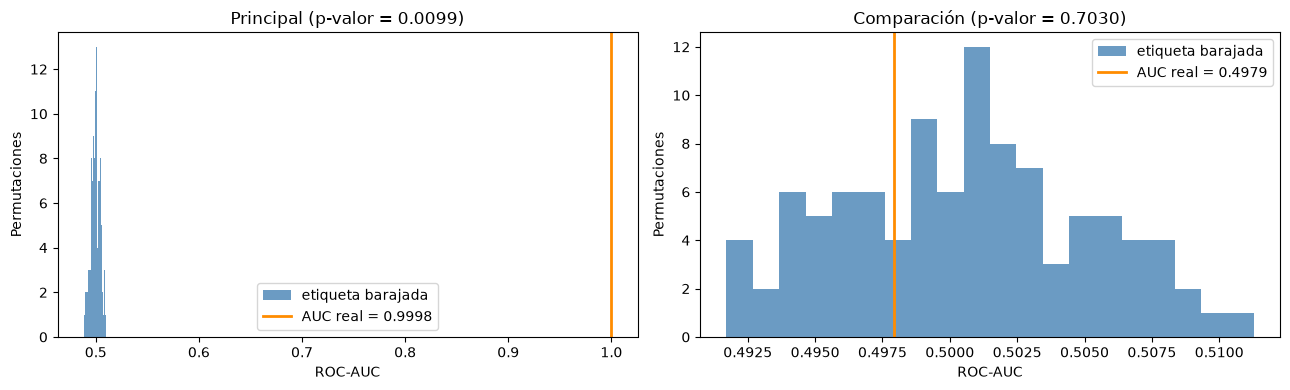

,variables,auc_real,auc_permutado_promedio,auc_permutado_maximo,p_valor
Principal,7,0.9998,0.4996,0.5101,0.0099
Comparación,51,0.4979,0.5005,0.5113,0.7030


In [68]:
muestra_perm = train.sample(min(30_000, len(train)), random_state=SEMILLA)
y_perm = muestra_perm[OBJETIVO].astype(int)
escenarios_perm = {
    "Principal": features.VARIABLES_ESCENARIO_PRINCIPAL,
    "Comparación": [c for c in SIN_RESUMEN if c not in features.COLUMNAS_REDUNDANTES],
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
resultados_perm = {}
for ax, (nombre, variables) in zip(axes, escenarios_perm.items()):
    numericas, categoricas, booleanas = separar_por_tipo(variables)
    auc_real, auc_permutados, p_valor = permutation_test_score(
        crear_modelo_rapido(numericas + booleanas, categoricas), preparar_X(muestra_perm, numericas, categoricas, booleanas), y_perm,
        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA), scoring="roc_auc",
        n_permutations=100, n_jobs=-1, random_state=SEMILLA,
    )
    resultados_perm[nombre] = {
        "variables": len(variables), "auc_real": auc_real, "auc_permutado_promedio": auc_permutados.mean(),
        "auc_permutado_maximo": auc_permutados.max(), "p_valor": p_valor,
    }
    ax.hist(auc_permutados, bins=20, color="steelblue", alpha=0.8, label="etiqueta barajada")
    ax.axvline(auc_real, color="darkorange", linewidth=2, label=f"AUC real = {auc_real:.4f}")
    ax.set_xlabel("ROC-AUC")
    ax.set_ylabel("Permutaciones")
    ax.set_title(f"{nombre} (p-valor = {p_valor:.4f})")
    ax.legend()
plt.tight_layout()
plt.show()
pd.DataFrame(resultados_perm).T.astype({"variables": int}).round(4)

**Conclusión**

- **Escenario principal:** el AUC real es 0,9998 y el mayor con la etiqueta barajada es 0,5101, con p-valor de 0,0099. La señal no se debe al azar. Esto no
  dice por qué existe: la auditoría de la sección 5.3 indica que `churn` parece calculado a partir de estas variables.
- **Escenario de comparación:** estas 51 variables no predicen `churn` mejor que el azar. Usar la etiqueta real (AUC de 0,4979) no supera a
  usarla barajada, es decir, sin relación con las variables (promedio de 0,5005). El p-valor de 0,7030 es coherente con esto, y la línea base pública da
  un resultado parecido, 0,5035.

## 7. Propuestas para el modelado

**Para usar en `02_modelado.ipynb`:**

```python
from churn import data, features
c360 = data.normalizar_tipos(data.cargar_customer_360(), features.COLUMNAS_FECHA)
limpio = features.crear_pipeline_limpieza().fit_transform(c360)
limpio = limpio.merge(data.cargar_particion(limpio), on=features.LLAVE)   # la misma partición del EDA
train = limpio[limpio["conjunto"] == "train"].drop(columns="conjunto")
test = limpio[limpio["conjunto"] == "test"].drop(columns="conjunto")      # se evalúa una sola vez, al final

variables_principal = features.VARIABLES_ESCENARIO_PRINCIPAL
variables_comparacion = features.variables_escenario_comparacion(train)
```

**Variables**

| Uso | Variables | Justificación |
|---|---|---|
| **Escenario principal** (7) | `summary_total_orders`, `total_spent`, `average_order_value`, `total_returns`, `return_rate`, `last_purchase_days` y `purchase_frequency` | Secciones 5.3 y 5.4 |
| **Escenario de comparación** (51) | `features.variables_escenario_comparacion(train)`: las demás variables, sin `customer_summary` | Secciones 5.3 y 5.4 |
| No usar, es fuga directa | `churn_risk_score` | Sección 5.3 |
| No usar, resume otras columnas y reintroduce señal | `customer_segment` | Sección 5.3 |
| No usar, son redundantes | `loyalty_points`, `lifetime_value` y `orders_status_returned_n`. `lifetime_value` se conserva para priorizar | Sección 5.4 |
| Ya las quita el pipeline de limpieza | `last_payment_date`, `payment_date_in_future` y `summary_vs_orders_mismatch` | Secciones 3.4, 3.6 y 3.7 |
| No usar directamente | `customer_id` (llave), y `signup_date`, `first_order_date` y `last_order_date` (fechas) | Sección 5 |

**Tratamiento en el pipeline del modelado (ajustado solo con `train`)**

- **Nulos estructurales:** solo afectan al escenario de comparación. Si el modelo no los admite, definir cómo representarlos, usando `has_orders` y `has_tickets`.
- **Asimetría y escala:** transformar según el modelo. Muchas variables tienen ceros, así que un logaritmo simple no serviría.
- **Multicolinealidad:** revisar si el VIF de 7,61 en `total_spent` afecta la lectura de coeficientes de la regresión logística.
- **Selección:** seguir el criterio de la sección 6.1, y comparar con las referencias de la sección 6.2.

**Interpretabilidad (retroalimentación del profesor)**

Para analizar cómo influye cada factor en `churn`, comparar 3 enfoques: los coeficientes de la regresión logística, la importancia de variables de los
modelos basados en árboles y los valores SHAP. Cómo leerlos en cada escenario:

- **Principal:** según la sección 5.3, se espera que dominen `last_purchase_days`, `return_rate` y `purchase_frequency`. Esto describe cómo se relacionan estas
  variables con `churn` en el dataset, donde la etiqueta parece calculada a partir de ellas; no demuestra que sean la causa del abandono.
- **Comparación:** como estas variables no muestran señal, sus importancias y valores SHAP no se deben interpretar como factores de abandono.

**¿Vale la pena crear más variables?** La propuesta inicial era agregar ratios y tendencias calculados desde `orders` y `support_tickets`. Se prueban en la siguiente celda.

In [69]:
# ¿Las variables propuestas aportan al escenario de comparación? Misma muestra y validación cruzada de la sección 5.3
variables_comparacion = features.variables_escenario_comparacion(train)
con_nuevas = muestra_train.copy()
pedidos = con_nuevas["orders_n"].astype(float).replace(0, np.nan)
con_nuevas["tendencia_3m_12m"] = con_nuevas["orders_last_3m"].astype(float) / con_nuevas["orders_last_12m"].astype(float).replace(0, np.nan)
con_nuevas["devoluciones_por_pedido"] = con_nuevas["orders_returned_flag_n"].astype(float) / pedidos
con_nuevas["cancelaciones_por_pedido"] = con_nuevas["orders_cancelled_n"].astype(float) / pedidos
con_nuevas["escalados_por_ticket"] = con_nuevas["tickets_escalated_n"].astype(float) / con_nuevas["tickets_n"].astype(float).replace(0, np.nan)
nuevas = ["tendencia_3m_12m", "devoluciones_por_pedido", "cancelaciones_por_pedido", "escalados_por_ticket"]

print("AUC univariado de cada variable nueva:")
display(eda.resumen_relacion_objetivo(con_nuevas.assign(**{OBJETIVO: y_muestra.values}), OBJETIVO, nuevas)[["pct_nulos", "auc_univariado"]])

numericas, categoricas, booleanas = separar_por_tipo(variables_comparacion)
X_nuevas = preparar_X(con_nuevas, numericas + nuevas, categoricas, booleanas)
r = cross_validate(crear_modelo_rapido(numericas + nuevas + booleanas, categoricas), X_nuevas, y_muestra, cv=cv,
                   scoring=["roc_auc", "average_precision"], n_jobs=-1)
print(f"Comparación con las variables nuevas: ROC-AUC {r['test_roc_auc'].mean():.4f} y PR-AUC {r['test_average_precision'].mean():.4f}")

AUC univariado de cada variable nueva:


,pct_nulos,auc_univariado
variable,,
tendencia_3m_12m,76.2490,0.5034
escalados_por_ticket,73.9510,0.5031
cancelaciones_por_pedido,13.6470,0.5006
devoluciones_por_pedido,13.6470,0.5003


Comparación con las variables nuevas: ROC-AUC 0.4975 y PR-AUC 0.2060


**Conclusión**

Las 4 variables nuevas tienen AUC univariado cercano a 0,50, y agregarlas al escenario de comparación no lo mejora (el AUC sigue cerca del azar).
Con el escenario principal tampoco se necesitan, porque su AUC ya es 0,9999. **No se propone crear más variables en esta etapa.**

In [70]:
# ¿Cómo se reparten las probabilidades del escenario principal? Predicciones fuera de muestra, con validación cruzada
numericas, categoricas, booleanas = separar_por_tipo(features.VARIABLES_ESCENARIO_PRINCIPAL)
probabilidad = cross_val_predict(crear_modelo_rapido(numericas + booleanas, categoricas), preparar_X(muestra_train, numericas, categoricas, booleanas),
                                 y_muestra, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
print(f"Clientes con probabilidad menor a 0,1: {100 * (probabilidad < 0.1).mean():.2f} %")
print(f"Clientes con probabilidad entre 0,1 y 0,9: {100 * ((probabilidad >= 0.1) & (probabilidad <= 0.9)).mean():.2f} %")
print(f"Clientes con probabilidad mayor a 0,9: {100 * (probabilidad > 0.9).mean():.2f} %")

Clientes con probabilidad menor a 0,1: 78.34 %
Clientes con probabilidad entre 0,1 y 0,9: 2.04 %
Clientes con probabilidad mayor a 0,9: 19.61 %


**Conclusión**

Casi todas las probabilidades quedan cerca de 0 o de 1. Solo 2,04 % de los clientes está entre 0,1 y 0,9.

**Priorización:** combinar la probabilidad de churn con `lifetime_value` para ordenar a qué clientes dirigir las
acciones de retención. Como las probabilidades son casi
binarias, en la práctica el orden lo definirá sobre todo `lifetime_value` entre los clientes marcados como riesgo alto. El modelado debe revisar además
la calibración antes de usar la probabilidad en este cálculo.